# 프로젝트 6. 제조업 실시간 이상 탐지 시스템 구축 (VisA pcb4)

- 실습: 정상 이미지로만 학습하는 이상 탐지 모델 3가지(PaDiM, AutoEncoder, One-Class SVM)를 비교하고, PaDiM을 Gradio로 실시간 추론한다.
- 추가 실험: PaDiM의 높은 AUROC가 실제 결함 탐지 능력에서 나온 것인지 검증하고(Test 1·2), AutoEncoder의 AUROC가 무작위보다 낮은 원인을 학습 과정으로 확인한다(Test 3). 불량 라벨을 쓰는 CatBoost도 같은 잣대로 비교한다(Test 4).
- 실행 환경: Google Colab T4 GPU

## 목차
1. 라이브러리 설치 · VisA 데이터셋 다운로드
2. Dataloader 구현 · 시각화
3. 모델 구현 · 비교 평가 (PaDiM, AutoEncoder, One-Class SVM)
4. 실시간 inference (Gradio)
5. 추가 실험: Test 1 (기판 종류 지름길 검증), Test 2 (결함 영역 검증: 실험 A·B), Test 3 (AutoEncoder 학습 과정 검증), Test 4 (불량 라벨을 쓰는 CatBoost 비교)
6. 개인 회고 (KPT, AAR)

### 이상탐지를 위한 라이브러리 설치

In [ ]:
# !pip install anomalib
# !pip install pytorch-lightning

In [ ]:
# !pip install wget

In [ ]:
# @title 실행 준비: 패키지 설치와 데이터 파일 미리 받기
import importlib.util, os, subprocess, sys
if os.path.isdir('/content'):
    os.chdir('/content')
for _pkg in ['wget', 'gradio']:
    if importlib.util.find_spec(_pkg) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', _pkg], check=True)
_tar = 'VisA_20220922.tar'
if not os.path.exists(_tar):
    subprocess.run(['curl', '-fsSL', '-o', _tar,
                    'https://amazon-visual-anomaly.s3.us-west-2.amazonaws.com/VisA_20220922.tar'], check=True)
print('작업 폴더:', os.getcwd())
print('설치 확인:', {p: importlib.util.find_spec(p) is not None for p in ['wget', 'gradio']})
print('데이터 파일:', _tar, f'{os.path.getsize(_tar) / 1e9:.2f} GB')


작업 폴더: /content
설치 확인: {'wget': True, 'gradio': True}
데이터 파일: VisA_20220922.tar 1.93 GB


## VisA 데이터셋 다운로드

In [ ]:
import os
import wget
import zipfile
from pathlib import Path
import pandas as pd
import tarfile

def download_visa_dataset():
    """VisA 데이터셋 다운로드"""
    base_url = "https://amazon-visual-anomaly.s3.us-west-2.amazonaws.com/VisA_20220922.tar"
    filename = "VisA_20220922.tar"
    extract_dir = "./VisA"


    if not os.path.exists(filename):
        print("VisA 데이터셋 다운로드 중...")
        wget.download(base_url, filename)
        print("\n다운로드 완료!")

    ## 압축 해제
    if not os.path.exists(extract_dir):
        os.makedirs(extract_dir, exist_ok=True)
        with tarfile.open(filename, 'r') as tar:
            tar.extractall(path=extract_dir)
        print("압축 해제 완료!")

def check_visa_structure(data_path="./VisA_pytorch/VisA"):
    """VisA 데이터셋 구조 확인"""
    data_path = Path(data_path)
    print(f"VisA 데이터셋 경로: {data_path}")

    categories = []
    for category_dir in data_path.iterdir():
        if category_dir.is_dir():
            categories.append(category_dir.name)
            print(f"\n카테고리: {category_dir.name}")

            # 이미지 개수 확인
            images_dir = category_dir / "Data" / "Images"
            if images_dir.exists():
                normal_count = len(list((images_dir / "Normal").glob("*"))) if (images_dir / "Normal").exists() else 0


                print(f"  정상 이미지: {normal_count}개")

    return categories

In [ ]:
download_visa_dataset()

In [ ]:
check_visa_structure(data_path="./VisA")

VisA 데이터셋 경로: VisA

카테고리: split_csv

카테고리: pipe_fryum
  정상 이미지: 500개

카테고리: cashew
  정상 이미지: 500개

카테고리: pcb1
  정상 이미지: 1004개

카테고리: pcb3
  정상 이미지: 1006개

카테고리: macaroni2
  정상 이미지: 1000개

카테고리: pcb4
  정상 이미지: 1005개

카테고리: candle
  정상 이미지: 1000개

카테고리: capsules
  정상 이미지: 602개

카테고리: fryum
  정상 이미지: 500개

카테고리: macaroni1
  정상 이미지: 1000개

카테고리: chewinggum
  정상 이미지: 503개

카테고리: pcb2
  정상 이미지: 1001개


['split_csv',
 'pipe_fryum',
 'cashew',
 'pcb1',
 'pcb3',
 'macaroni2',
 'pcb4',
 'candle',
 'capsules',
 'fryum',
 'macaroni1',
 'chewinggum',
 'pcb2']

**📝 이론 정리 / 기능 묘사 / 코멘트**

- 이론 정리: 제조 현장은 정상품이 99%, 불량품이 1% 정도라 불량 데이터가 부족하다. 그래서 이상 탐지는 정상 데이터만으로 정상 범위를 학습하고, 벗어나는 것을 불량으로 찾는다. VisA는 PCB·캡슐·양초 등 12개 카테고리에 균열·구멍·흠집 같은 결함과 픽셀 단위 마스크를 제공하는 이상 탐지용 데이터셋이다.
- 기능 묘사: VisA 데이터셋을 받아 압축을 풀고, 카테고리별 정상 이미지 수를 확인했다.
- 코멘트: VisA 데이터셋을 받는 구조이고, 이미지 개수가 많아보이는 것에 비해 총 데이터셋 크기는 작아 보였다.

### Dataloader 구현

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as transforms
import cv2
import numpy as np

class VisADataset(Dataset):
    def __init__(self, data_path, category, transform=None, is_train=True, include_mask=False, train_ratio=0.8):
        self.data_path = Path(data_path)
        self.category = category
        self.transform = transform
        self.is_train = is_train
        self.include_mask = include_mask

        self.image_paths = []
        self.mask_paths = []
        self.labels = []
        self.defect_types = []

        category_path = self.data_path / category

        # CSV 파일에서 메타데이터 로드
        csv_path = category_path / "image_anno.csv"
        if csv_path.exists():
            df = pd.read_csv(csv_path)
            print(f"CSV 컬럼: {df.columns.tolist()}")

            # 정상/비정상 데이터 분리
            normal_df = df[df['label'] == 'normal'].copy()
            anomaly_df = df[df['label'] != 'normal'].copy()

            if self.is_train:
                # 훈련용: 정상 데이터의 일부만 사용
                train_size = int(len(normal_df) * train_ratio)
                selected_df = normal_df.iloc[:train_size]
                print(f"훈련용 정상 데이터: {len(selected_df)}개")
            else:
                # 테스트용: 나머지 정상 데이터 + 모든 비정상 데이터
                test_normal_size = len(normal_df) - int(len(normal_df) * train_ratio)
                test_normal_df = normal_df.iloc[-test_normal_size:] if test_normal_size > 0 else pd.DataFrame()
                selected_df = pd.concat([test_normal_df, anomaly_df], ignore_index=True)
                print(f"테스트용 정상 데이터: {len(test_normal_df)}개")
                print(f"테스트용 비정상 데이터: {len(anomaly_df)}개")

            # 데이터 로드
            for _, row in selected_df.iterrows():
                # 이미지 경로 처리 (중복 경로 제거)
                image_rel_path = row['image']
                if image_rel_path.startswith(category + '/'):
                    image_path = self.data_path / image_rel_path
                else:
                    image_path = category_path / image_rel_path

                if image_path.exists():
                    self.image_paths.append(str(image_path))
                    self.labels.append(0 if row['label'] == 'normal' else 1)
                    self.defect_types.append(row['label'])

                    # 마스크 경로 처리
                    if pd.notna(row['mask']) and self.include_mask:
                        mask_rel_path = row['mask']
                        if mask_rel_path.startswith(category + '/'):
                            mask_path = self.data_path / mask_rel_path
                        else:
                            mask_path = category_path / mask_rel_path
                        self.mask_paths.append(str(mask_path) if mask_path.exists() else None)
                    else:
                        self.mask_paths.append(None)
                else:
                    print(f"이미지 파일을 찾을 수 없습니다: {image_path}")
        else:
            print("CSV 파일이 없습니다. 폴더 구조를 기반으로 데이터를 로드합니다.")
            self._load_from_folder_structure()

    def _load_from_folder_structure(self):
        """폴더 구조를 기반으로 데이터 로드 (CSV가 없는 경우)"""
        category_path = self.data_path / self.category
        images_path = category_path / "Data" / "Images"
        masks_path = category_path / "Data" / "Masks"

        if self.is_train:
            # 훈련용: 정상 이미지만 사용
            normal_path = images_path / "Normal"
            if normal_path.exists():
                for img_path in normal_path.glob("*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
                        self.image_paths.append(str(img_path))
                        self.labels.append(0)  # 정상: 0
                        self.defect_types.append('normal')
                        self.mask_paths.append(None)
        else:
            # 테스트용: 정상 + 비정상 이미지
            # 정상 이미지
            normal_path = images_path / "Normal"
            if normal_path.exists():
                for img_path in normal_path.glob("*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
                        self.image_paths.append(str(img_path))
                        self.labels.append(0)
                        self.defect_types.append('normal')
                        self.mask_paths.append(None)

            # 비정상 이미지
            anomaly_path = images_path / "Anomaly"
            if anomaly_path.exists():
                for img_path in anomaly_path.glob("*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
                        self.image_paths.append(str(img_path))
                        self.labels.append(1)  # 이상: 1
                        self.defect_types.append('anomaly')

                        # 마스크 경로 찾기
                        if self.include_mask:
                            mask_name = img_path.stem + '.png'  # 확장자를 png로 변경
                            mask_path = masks_path / "Anomaly" / mask_name
                            self.mask_paths.append(str(mask_path) if mask_path.exists() else None)
                        else:
                            self.mask_paths.append(None)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # 이미지 로드
        image = Image.open(self.image_paths[idx]).convert('RGB')
        label = self.labels[idx]

        # 마스크 로드 (있는 경우)
        mask = None
        if self.include_mask and self.mask_paths[idx] is not None:
            try:
                mask = Image.open(self.mask_paths[idx]).convert('L')
            except:
                mask = None

        # 변환 적용
        if self.transform:
            image = self.transform(image)
            if mask is not None:
                mask_transform = transforms.Compose([
                    transforms.Resize((256, 256)),
                    transforms.ToTensor()
                ])
                mask = mask_transform(mask)

        result = {
            'image': image,
            'label': label,
            'defect_type': self.defect_types[idx]
        }

        if mask is not None:
            result['mask'] = mask

        return result

In [ ]:
# 데이터 전처리 정의
def get_visa_transforms():
    train_transform = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                           std=[0.229, 0.224, 0.225])
    ])

    test_transform = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                           std=[0.229, 0.224, 0.225])
    ])

    return train_transform, test_transform


In [ ]:
def create_visa_data_loaders(data_path, category, batch_size=32, include_mask=False, train_ratio=0.8):
    """
    VisA 데이터셋용 데이터 로더 생성

    Args:
        data_path: VisA 데이터셋 경로
        category: 카테고리 이름
        batch_size: 배치 크기
        include_mask: 마스크 포함 여부
        train_ratio: 훈련 데이터 비율 (정상 데이터에서)
    """
    train_transform, test_transform = get_visa_transforms()

    train_dataset = VisADataset(
        data_path, category,
        transform=train_transform,
        is_train=True,
        include_mask=include_mask,
        train_ratio=train_ratio
    )

    test_dataset = VisADataset(
        data_path, category,
        transform=test_transform,
        is_train=False,
        include_mask=include_mask,
        train_ratio=train_ratio
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=2,  # Windows에서 문제가 있을 수 있으므로 낮춤
        pin_memory=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    return train_loader, test_loader


## 시각화

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np

def visualize_visa_samples(dataset, num_samples=8):
    """VisA 데이터셋 샘플 시각화"""
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()

    indices = np.random.choice(len(dataset), min(num_samples, len(dataset)), replace=False)

    for i, idx in enumerate(indices):
        sample = dataset[idx]
        image = sample['image']
        label = sample['label']
        defect_type = sample['defect_type']

        # 텐서를 이미지로 변환
        if isinstance(image, torch.Tensor):
            image = image.permute(1, 2, 0)
            image = image * torch.tensor([0.229, 0.224, 0.225]) + torch.tensor([0.485, 0.456, 0.406])
            image = torch.clamp(image, 0, 1)

        axes[i].imshow(image)
        title = f"{'Normal' if label == 0 else 'Anomaly'}"
        if defect_type != 'normal':
            title += f"\n({defect_type})"
        axes[i].set_title(title)
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

def visualize_with_mask(dataset, idx):
    """이미지와 마스크 함께 시각화"""
    sample = dataset[idx]
    image = sample['image']
    mask = sample.get('mask')
    label = sample['label']
    defect_type = sample['defect_type']

    # 이미지 정규화 해제
    if isinstance(image, torch.Tensor):
        image = image.permute(1, 2, 0)
        image = image * torch.tensor([0.229, 0.224, 0.225]) + torch.tensor([0.485, 0.456, 0.406])
        image = torch.clamp(image, 0, 1)

    if mask is not None:
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))

        # 원본 이미지
        axes[0].imshow(image)
        axes[0].set_title('Original Image')
        axes[0].axis('off')

        # 마스크
        axes[1].imshow(mask.squeeze(), cmap='gray')
        axes[1].set_title('Anomaly Mask')
        axes[1].axis('off')

        # 오버레이
        overlay = image.clone()
        if mask.sum() > 0:
            mask_resized = torch.nn.functional.interpolate(
                mask.unsqueeze(0),
                size=image.shape[:2],
                mode='nearest'
            ).squeeze()
            overlay[mask_resized > 0.01] = torch.tensor([255.0, 0.0, 0.0])  # 빨간색으로 표시

        axes[2].imshow(overlay)
        axes[2].set_title(f'Overlay ({defect_type})')
        axes[2].axis('off')

    else:
        plt.figure(figsize=(8, 6))
        plt.imshow(image)
        plt.title(f"{'Normal' if label == 0 else 'Anomaly'} - {defect_type}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()


In [ ]:
def plot_visa_statistics(data_path, category):
    """VisA 데이터셋 통계 시각화"""
    category_path = Path(data_path) / category
    csv_path = category_path / "image_anno.csv"

    if csv_path.exists():
        df = pd.read_csv(csv_path)

        fig, axes = plt.subplots(2, 2, figsize=(15, 10))

        title1 = 'Overall Class Distribution (Normal vs Anomaly)'
        title2 = 'Main Defect Types Distribution'
        title3 = 'Mask Availability Distribution'
        title4 = 'All Labels Distribution (Top 10)'
        xlabel2 = 'Number of Images'
        ylabel3 = 'Number of Images'
        xlabel4 = 'Number of Images'
        mask_labels = ['With Mask', 'Without Mask']

        # 전체 클래스 분포 (정상 vs 비정상)
        binary_labels = ['Normal' if label == 'normal' else 'Anomaly' for label in df['label']]
        class_counts = pd.Series(binary_labels).value_counts()
        axes[0, 0].pie(class_counts.values, labels=class_counts.index, autopct='%1.1f%%')
        axes[0, 0].set_title(title1)

        # 결함 유형별 상세 분포
        anomaly_df = df[df['label'] != 'normal']
        if not anomaly_df.empty:
            # 결함 유형을 단순화 (콤마로 구분된 경우 첫 번째만 사용)
            simplified_defects = [label.split(',')[0] for label in anomaly_df['label']]
            defect_counts = pd.Series(simplified_defects).value_counts()

            axes[0, 1].barh(defect_counts.index, defect_counts.values)
            axes[0, 1].set_title(title2)
            axes[0, 1].set_xlabel(xlabel2)

        # 마스크 유무 분포
        mask_counts = df['mask'].notna().value_counts()
        mask_labels_mapped = [mask_labels[0] if has_mask else mask_labels[1] for has_mask in mask_counts.index]
        axes[1, 0].bar(mask_labels_mapped, mask_counts.values)
        axes[1, 0].set_title(title3)
        axes[1, 0].set_ylabel(ylabel3)

        # 전체 결함 유형 (복합 결함 포함)
        all_defect_counts = df['label'].value_counts()
        # 상위 10개만 표시
        top_defects = all_defect_counts.head(10)
        axes[1, 1].barh(range(len(top_defects)), top_defects.values)
        axes[1, 1].set_yticks(range(len(top_defects)))
        axes[1, 1].set_yticklabels(top_defects.index)
        axes[1, 1].set_title(title4)
        axes[1, 1].set_xlabel(xlabel4)

        plt.tight_layout()
        plt.show()

        # 데이터 요약 출력

        print(f"Total images: {len(df)}")
        print(f"Normal images: {len(df[df['label'] == 'normal'])}")
        print(f"Anomaly images: {len(df[df['label'] != 'normal'])}")
        print(f"Images with masks: {df['mask'].notna().sum()}")
        print(f"Unique defect types: {df['label'].nunique()}")

    else:
        error_msg = f"CSV 파일을 찾을 수 없습니다: {csv_path}" if KOREAN_FONT_AVAILABLE else f"CSV file not found: {csv_path}"
        print(error_msg)


In [ ]:
DATA_PATH = "./VisA" # <--- 실제 데이터셋 경로로 변경하세요!
CATEGORY_NAME = "pcb4" # VisA 데이터셋의 카테고리 중 하나 (예: 'pcb', 'capsules' 등)
BATCH_SIZE = 8 # 메모리에 따라 조절
D_REDUCED = 100 # PaDiM의 축소된 특징 차원
IMG_SIZE = 256  # 입력 이미지 크기 (예시)
NORMALIZE_MEAN = [0.485, 0.456, 0.406]
NORMALIZE_STD = [0.229, 0.224, 0.225]
# PaDiM 내부에서 특징맵을 리사이즈할 크기 (고정)
PADIM_PATCH_SIZE = 28

train_loader, test_loader = create_visa_data_loaders(DATA_PATH, CATEGORY_NAME, BATCH_SIZE, include_mask=True)

CSV 컬럼: ['image', 'label', 'mask']
훈련용 정상 데이터: 804개
CSV 컬럼: ['image', 'label', 'mask']
테스트용 정상 데이터: 201개
테스트용 비정상 데이터: 100개


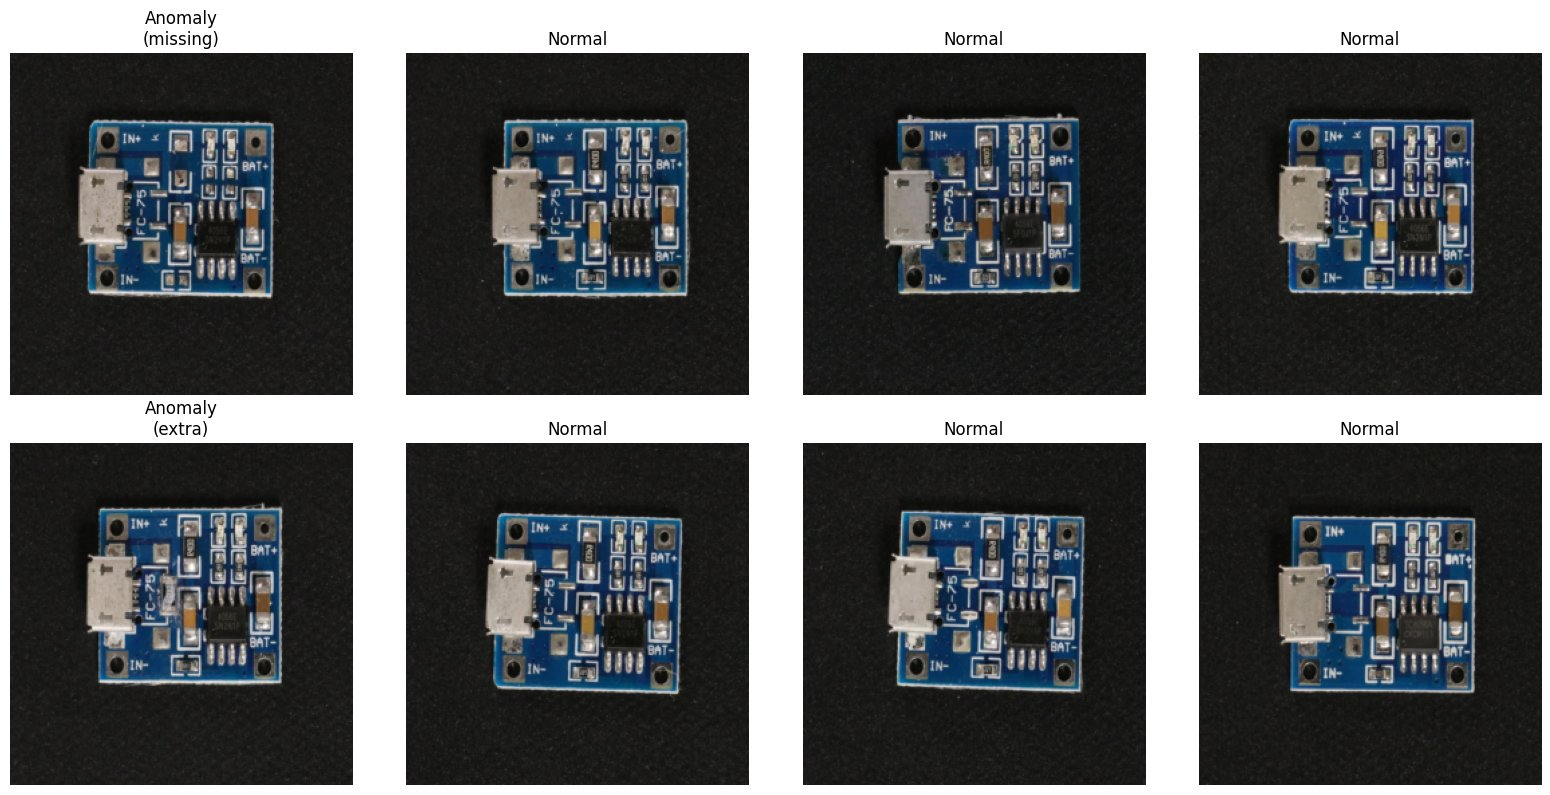

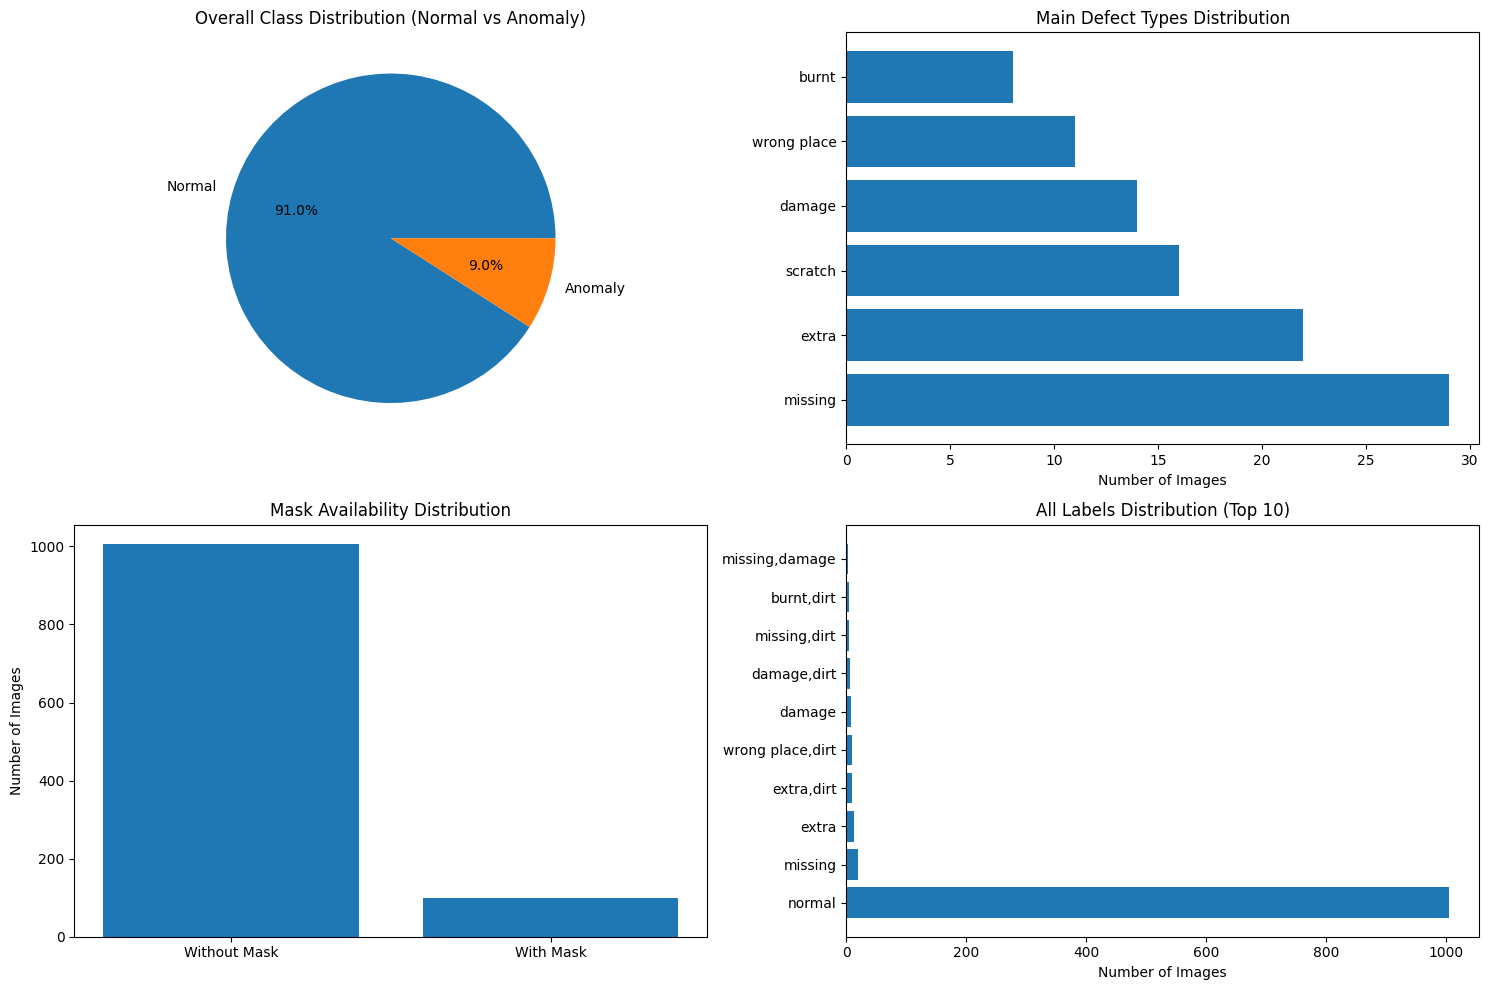

Total images: 1105
Normal images: 1005
Anomaly images: 100
Images with masks: 100
Unique defect types: 27


In [ ]:
visualize_visa_samples(test_loader.dataset)
plot_visa_statistics(DATA_PATH, CATEGORY_NAME)

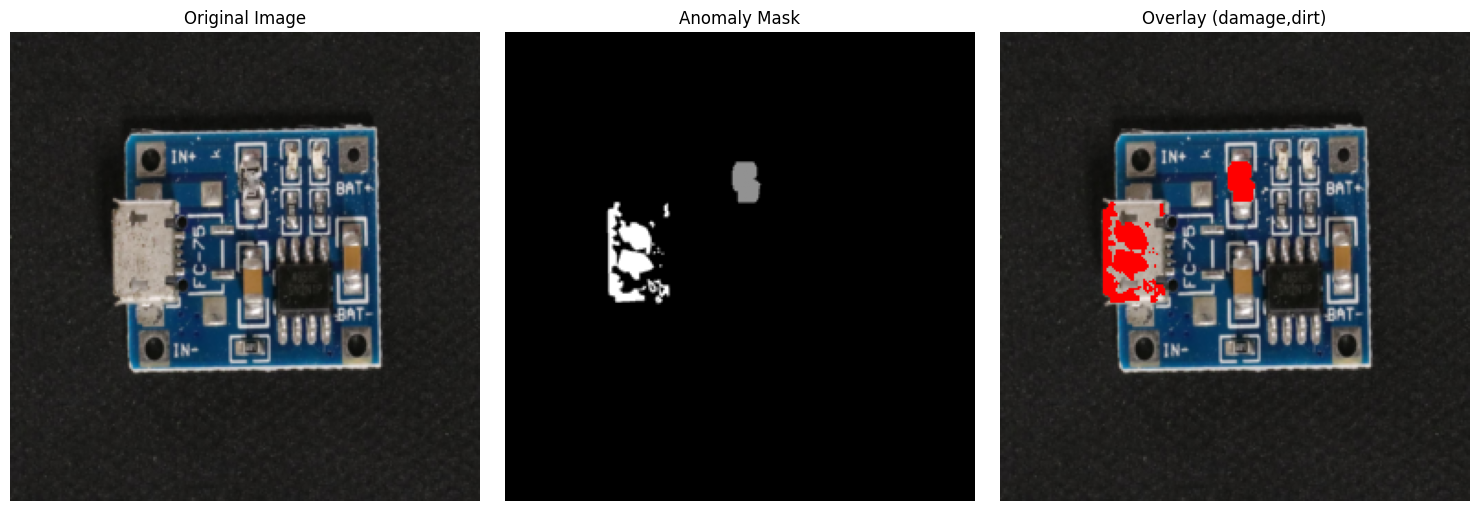

In [ ]:
visualize_with_mask(test_loader.dataset, 210)

**📝 이론 정리 / 기능 묘사 / 코멘트**

- 이론 정리: 데이터 전처리로 이미지 크기를 모델에 맞게 통일하고 픽셀 값을 평균 0, 표준편차 1로 정규화해 학습을 안정시킨다. 반전 같은 데이터 증강은 적은 데이터의 다양성을 늘려 과적합을 막는다.
- 기능 묘사: image_anno.csv를 읽어 정상 이미지의 대부분 앞부분은 학습용, 나머지 정상과 불량 데이터는 테스트용으로 나누고 정상 0, 불량 1로 라벨을 붙였다. 이미지는 256×256으로 줄이고, 학습용에는 좌우 반전을 넣었다. 테스트 데이터에서 무작위로 8장을 골라 정규화를 되돌려 보여 주고, 정상과 불량 비율, 결함 유형, 마스크 유무를 그래프로 그렸다. 불량 이미지 하나는 빨간색으로 결함 마스크를 겹쳐 결함 위치를 표시했다.
- 코멘트: 학습용과 학습 데이터, 정상 비정상 데이터 라벨로 데이터셋을 전처리하는 과정이다. 모델이 정상과 비정상을 잘 걸러내는 것 같은데 중간에 위 사진에서 FC-75라고 써져있는 부분과 그렇지 않은 부분이 있어 궁금했다

## 모델 구현

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
import torchvision.models as models

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc, roc_curve
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

import cv2
from PIL import Image
from pathlib import Path
import pickle
import json
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# GPU 설정
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"사용 장치: {device}")


사용 장치: cuda


In [ ]:
class FeatureExtractor(nn.Module):
    def __init__(self, model_name='resnet18', layers_to_extract=['layer1', 'layer2', 'layer3']):
        super(FeatureExtractor, self).__init__()

        if model_name == 'resnet18':
            self.model = models.resnet18(pretrained=True)
        elif model_name == 'resnet50':
            self.model = models.resnet50(pretrained=True)
        elif model_name == 'wide_resnet50':
            self.model = models.wide_resnet50_2(pretrained=True)
        else:
            raise ValueError(f"지원하지 않는 모델: {model_name}")

        self.layers_to_extract = layers_to_extract
        self.features = {}

        # Hook 등록
        for name, module in self.model.named_modules():
            if name in layers_to_extract:
                module.register_forward_hook(self.save_features(name))

        # 평가 모드로 설정
        self.model.eval()

        # 그래디언트 계산 비활성화
        for param in self.model.parameters():
            param.requires_grad = False

    def save_features(self, name):
        def hook(module, input, output):
            self.features[name] = output
        return hook

    def forward(self, x):
        self.features.clear()
        _ = self.model(x)
        return self.features

# Feature Extractor 초기화
feature_extractor = FeatureExtractor('wide_resnet50', ['layer2', 'layer3']).to(device)

In [ ]:
class PaDiM:
    def __init__(self, feature_extractor, d_reduced=100):
        self.feature_extractor = feature_extractor
        self.d_reduced = d_reduced
        self.means = []
        self.inv_covariances = []
        self.projection_matrix = None

    def fit(self, train_loader):
        """정상 데이터로 모델 훈련"""
        print("PaDiM 훈련 시작...")

        # 모든 훈련 데이터에서 특징 추출
        all_features = []

        for batch in tqdm(train_loader, desc="특징 추출 중"):
            images = batch['image'].to(device)

            with torch.no_grad():
                features = self.feature_extractor(images)

                # 각 이미지별로 처리
                for i in range(images.size(0)):
                    img_features = []

                    # 레이어별 특징 추출 및 결합
                    for layer_name, feat in features.items():
                        # 단일 이미지 특징 추출
                        single_feat = feat[i:i+1]  # [1, C, H, W]

                        # 28x28로 리사이즈
                        feat_resized = F.adaptive_avg_pool2d(single_feat, (28, 28))

                        # 패치별 특징으로 변환 [784, C]
                        feat_patches = feat_resized.permute(0, 2, 3, 1).reshape(28*28, -1)
                        img_features.append(feat_patches)

                    # 레이어별 특징 결합 [784, total_channels]
                    combined_features = torch.cat(img_features, dim=1)
                    all_features.append(combined_features)

        # 모든 특징을 하나로 결합 [N*784, total_channels]
        all_features = torch.cat(all_features, dim=0)
        print(f"전체 특징 크기: {all_features.shape}")

        # 차원 축소를 위한 Random Projection 행렬 생성
        if all_features.shape[1] > self.d_reduced:
            self.projection_matrix = torch.randn(all_features.shape[1], self.d_reduced).to(device)
            # 정규화
            self.projection_matrix = F.normalize(self.projection_matrix, dim=0)

            # 차원 축소 적용
            all_features = torch.mm(all_features, self.projection_matrix)
            print(f"차원 축소 후 크기: {all_features.shape}")

        # 패치 위치별로 분리하여 통계 계산
        n_samples = len(all_features) // (28 * 28)

        for patch_idx in range(28 * 28):
            # 특정 패치 위치의 모든 특징 추출
            patch_features = all_features[patch_idx::28*28]  # [n_samples, d_reduced]

            # 평균과 공분산 계산
            mean = torch.mean(patch_features, dim=0)

            # 공분산 행렬 계산 (정규화 추가)
            centered_features = patch_features - mean
            cov = torch.mm(centered_features.T, centered_features) / (patch_features.shape[0] - 1)

            # 수치 안정성을 위한 정규화
            cov += torch.eye(cov.shape[0]).to(device) * 1e-4

            # 역행렬 계산
            try:
                inv_cov = torch.linalg.inv(cov)
            except:
                # 특이행렬인 경우 pseudo-inverse 사용
                inv_cov = torch.linalg.pinv(cov)

            self.means.append(mean)
            self.inv_covariances.append(inv_cov)

        print(f"PaDiM 훈련 완료! (패치 수: {len(self.means)})")

    def predict(self, test_loader):
        """테스트 데이터에 대한 이상 점수 계산"""
        anomaly_scores = []

        for batch in tqdm(test_loader, desc="이상 탐지 중"):
            images = batch['image'].to(device)

            with torch.no_grad():
                features = self.feature_extractor(images)

                # 각 이미지별로 처리
                for i in range(images.size(0)):
                    img_features = []

                    # 레이어별 특징 추출 및 결합
                    for layer_name, feat in features.items():
                        single_feat = feat[i:i+1]
                        feat_resized = F.adaptive_avg_pool2d(single_feat, (28, 28))
                        feat_patches = feat_resized.permute(0, 2, 3, 1).reshape(28*28, -1)
                        img_features.append(feat_patches)

                    combined_features = torch.cat(img_features, dim=1)

                    # 차원 축소 (훈련 시와 동일한 방식)
                    if self.projection_matrix is not None:
                        combined_features = torch.mm(combined_features, self.projection_matrix)

                    # 각 패치별 Mahalanobis 거리 계산
                    patch_scores = []
                    for patch_idx in range(28 * 28):
                        diff = combined_features[patch_idx] - self.means[patch_idx]

                        # Mahalanobis 거리 계산
                        mahal_dist = torch.sqrt(torch.mm(
                            torch.mm(diff.unsqueeze(0), self.inv_covariances[patch_idx]),
                            diff.unsqueeze(1)
                        )).item()

                        patch_scores.append(mahal_dist)

                    # 전체 이상 점수 (최대값 사용)
                    anomaly_scores.append(max(patch_scores))

        return np.array(anomaly_scores), None

In [ ]:
class ConvAutoEncoder(nn.Module):
    def __init__(self, input_channels=3, latent_dim=128):
        super(ConvAutoEncoder, self).__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(input_channels, 32, 4, stride=2, padding=1),  # 128x128
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 64, 4, stride=2, padding=1),  # 64x64
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 128, 4, stride=2, padding=1),  # 32x32
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 256, 4, stride=2, padding=1),  # 16x16
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Conv2d(256, latent_dim, 4, stride=2, padding=1),  # 8x8
            nn.BatchNorm2d(latent_dim),
            nn.ReLU()
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, 256, 4, stride=2, padding=1),  # 16x16
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1),  # 32x32
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),  # 64x64
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),  # 128x128
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.ConvTranspose2d(32, input_channels, 4, stride=2, padding=1),  # 256x256
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

class AutoEncoderAnomalyDetector:
    def __init__(self, input_size=(256, 256), latent_dim=128):
        self.model = ConvAutoEncoder(input_channels=3, latent_dim=latent_dim).to(device)
        self.criterion = nn.MSELoss()
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=0.001)
        self.input_size = input_size

    def fit(self, train_loader, epochs=50):
        """AutoEncoder 훈련"""
        print("AutoEncoder 훈련 시작...")
        self.model.train()

        train_losses = []

        for epoch in range(epochs):
            epoch_loss = 0
            for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}"):
                images = batch['image'].to(device)

                self.optimizer.zero_grad()
                reconstructed = self.model(images)
                loss = self.criterion(reconstructed, images)
                loss.backward()
                self.optimizer.step()

                epoch_loss += loss.item()

            avg_loss = epoch_loss / len(train_loader)
            train_losses.append(avg_loss)
            print(f"Epoch {epoch+1}, Loss: {avg_loss:.6f}")

        self.model.eval()
        print("AutoEncoder 훈련 완료!")
        return train_losses

    def predict(self, test_loader):
        """테스트 데이터에 대한 재구성 오차 계산"""
        self.model.eval()
        anomaly_scores = []

        with torch.no_grad():
            for batch in tqdm(test_loader, desc="이상 탐지 중"):
                images = batch['image'].to(device)
                reconstructed = self.model(images)

                # 픽셀별 재구성 오차
                reconstruction_errors = F.mse_loss(reconstructed, images, reduction='none')
                reconstruction_errors = reconstruction_errors.view(images.size(0), -1).mean(dim=1)

                anomaly_scores.extend(reconstruction_errors.cpu().numpy())

        return np.array(anomaly_scores)

In [ ]:
class OneClassSVMAnomalyDetector:
    def __init__(self, feature_extractor, nu=0.1):
        self.feature_extractor = feature_extractor
        self.svm = OneClassSVM(nu=nu, kernel='rbf', gamma='scale')
        self.scaler = StandardScaler()

    def extract_features(self, data_loader):
        """특징 추출"""
        features = []

        for batch in tqdm(data_loader, desc="특징 추출 중"):
            images = batch['image'].to(device)

            with torch.no_grad():
                feat_dict = self.feature_extractor(images)

                # 모든 레이어의 특징을 결합하고 평균 풀링
                combined_features = []
                for layer_name, feat in feat_dict.items():
                    pooled_feat = F.adaptive_avg_pool2d(feat, (1, 1))
                    combined_features.append(pooled_feat.view(feat.size(0), -1))

                batch_features = torch.cat(combined_features, dim=1)
                features.append(batch_features.cpu().numpy())

        return np.concatenate(features, axis=0)

    def fit(self, train_loader):
        """One-Class SVM 훈련"""
        print("One-Class SVM 훈련 시작...")

        # 특징 추출
        train_features = self.extract_features(train_loader)

        # 정규화
        train_features_scaled = self.scaler.fit_transform(train_features)

        # SVM 훈련
        self.svm.fit(train_features_scaled)
        print("One-Class SVM 훈련 완료!")

    def predict(self, test_loader):
        """테스트 데이터에 대한 이상 점수 계산"""
        # 특징 추출
        test_features = self.extract_features(test_loader)

        # 정규화
        test_features_scaled = self.scaler.transform(test_features)

        # 이상 점수 계산 (결정 함수의 음수)
        anomaly_scores = -self.svm.decision_function(test_features_scaled)

        return anomaly_scores

**📝 이론 정리 / 기능 묘사 / 코멘트**

- 이론 정리: PaDiM은 사전학습된 CNN으로 패치마다 특징을 뽑아 위치별 정규 분포(평균, 공분산)를 만들고, 마할라노비스 거리로 이상을 찾는다. AutoEncoder는 정상을 압축했다 복원하도록 학습해 복원 오류가 크면 이상으로 보고, One-Class SVM은 정상 특징을 감싸는 경계 밖을 이상으로 본다.
- 기능 묘사: Wide-ResNet50을 불러와 hook으로 layer2와 layer3의 출력을 저장하게 하고, 가중치는 학습하지 않도록 고정했다. 이 특징을 쓰는 PaDiM과 One-Class SVM, 이미지를 직접 복원하는 AutoEncoder를 구현했다.
- 코멘트: 세 모델 모두 정상만 학습하는데, PaDiM은 사전학습된 CNN 특징으로 분포만 저장해서 따로 학습을 안 해도 된다는 점이 신기했다.

In [ ]:
class AnomalyDetectionEvaluator:
    def __init__(self):
        self.results = {}

    def evaluate(self, y_true, y_scores, method_name):
        """평가 메트릭 계산"""
        # AUROC
        auroc = roc_auc_score(y_true, y_scores)

        # AUPRC
        precision, recall, thresholds = precision_recall_curve(y_true, y_scores)
        auprc = auc(recall, precision)

        # 최적 임계값에서의 F1 스코어
        f1_scores = 2 * (precision * recall) / (precision + recall + 1e-8)

        # NaN 값 제거
        valid_indices = ~np.isnan(f1_scores)
        if np.any(valid_indices):
            valid_f1_scores = f1_scores[valid_indices]
            valid_thresholds = thresholds[valid_indices] if len(thresholds) == len(f1_scores) else thresholds[:len(valid_f1_scores)]

            best_f1_idx = np.argmax(valid_f1_scores)
            best_f1 = valid_f1_scores[best_f1_idx]
            best_threshold = valid_thresholds[best_f1_idx] if len(valid_thresholds) > best_f1_idx else 0.5
        else:
            best_f1 = 0.0
            best_threshold = 0.5

        self.results[method_name] = {
            'AUROC': auroc,
            'AUPRC': auprc,
            'Best_F1': best_f1,
            'Best_Threshold': best_threshold,
            'y_true': y_true,
            'y_scores': y_scores
        }

        print(f"{method_name} 결과:")
        print(f"  AUROC: {auroc:.4f}")
        print(f"  AUPRC: {auprc:.4f}")
        print(f"  Best F1: {best_f1:.4f}")
        print()

        return auroc, auprc, best_f1

    def plot_roc_curve(self):
        """ROC 곡선 그리기"""
        plt.figure(figsize=(10, 8))

        for method_name, result in self.results.items():
            fpr, tpr, _ = roc_curve(result['y_true'], result['y_scores'])
            plt.plot(fpr, tpr, label=f"{method_name} (AUC = {result['AUROC']:.3f})")

        plt.plot([0, 1], [0, 1], 'k--', label='Random')
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title('ROC Curves Comparison')
        plt.legend()
        plt.grid(True)
        plt.show()

    def plot_precision_recall_curve(self):
        """PR 곡선 그리기"""
        plt.figure(figsize=(10, 8))

        for method_name, result in self.results.items():
            precision, recall, _ = precision_recall_curve(result['y_true'], result['y_scores'])
            plt.plot(recall, precision, label=f"{method_name} (AUC = {result['AUPRC']:.3f})")

        plt.xlabel('Recall')
        plt.ylabel('Precision')
        plt.title('Precision-Recall Curves Comparison')
        plt.legend()
        plt.grid(True)
        plt.show()

    def plot_score_distribution(self):
        """이상 점수 분포 시각화"""
        fig, axes = plt.subplots(len(self.results), 1, figsize=(12, 4*len(self.results)))
        if len(self.results) == 1:
            axes = [axes]

        for i, (method_name, result) in enumerate(self.results.items()):
            normal_scores = result['y_scores'][result['y_true'] == 0]
            anomaly_scores = result['y_scores'][result['y_true'] == 1]

            axes[i].hist(normal_scores, bins=50, alpha=0.7, label='Normal', density=True)
            axes[i].hist(anomaly_scores, bins=50, alpha=0.7, label='Anomaly', density=True)
            axes[i].axvline(result['Best_Threshold'], color='red', linestyle='--',
                           label=f"Best Threshold: {result['Best_Threshold']:.3f}")
            axes[i].set_title(f'{method_name} - Anomaly Score Distribution')
            axes[i].set_xlabel('Anomaly Score')
            axes[i].set_ylabel('Density')
            axes[i].legend()
            axes[i].grid(True)

        plt.tight_layout()
        plt.show()

    def compare_methods(self):
        """방법별 성능 비교"""
        methods = list(self.results.keys())
        aurocs = [self.results[m]['AUROC'] for m in methods]
        auprcs = [self.results[m]['AUPRC'] for m in methods]
        f1_scores = [self.results[m]['Best_F1'] for m in methods]

        x = np.arange(len(methods))
        width = 0.25

        plt.figure(figsize=(12, 6))
        plt.bar(x - width, aurocs, width, label='AUROC', alpha=0.8)
        plt.bar(x, auprcs, width, label='AUPRC', alpha=0.8)
        plt.bar(x + width, f1_scores, width, label='Best F1', alpha=0.8)

        plt.xlabel('Methods')
        plt.ylabel('Score')
        plt.title('Performance Comparison')
        plt.xticks(x, methods, rotation=45)
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

In [ ]:
class VisAAnomalyDetectionSystem:
    def __init__(self, data_path, category):
        self.data_path = data_path
        self.category = category
        self.evaluator = AnomalyDetectionEvaluator()

        # 데이터 로더 생성
        self.train_loader, self.test_loader = create_visa_data_loaders(
            data_path, category, batch_size=16, include_mask=False, train_ratio=0.8
        )

        # 테스트 레이블 추출
        self.test_labels = []
        for batch in self.test_loader:
            self.test_labels.extend(batch['label'].numpy())
        self.test_labels = np.array(self.test_labels)

        print(f"시스템 초기화 완료:")
        print(f"  카테고리: {category}")
        print(f"  훈련 데이터: {len(self.train_loader.dataset)}개")
        print(f"  테스트 데이터: {len(self.test_loader.dataset)}개")
        print(f"  테스트 중 이상 데이터: {self.test_labels.sum()}개")

    def run_padim(self):
        """PaDiM 실행"""
        print("\n=== PaDiM 실행 ===")
        padim = PaDiM(feature_extractor, d_reduced=100)
        padim.fit(self.train_loader)
        scores, _ = padim.predict(self.test_loader)
        self.evaluator.evaluate(self.test_labels, scores, 'PaDiM')
        return scores

    def run_autoencoder(self, epochs=30):
        """AutoEncoder 실행"""
        print("\n=== AutoEncoder 실행 ===")
        ae_detector = AutoEncoderAnomalyDetector()
        ae_detector.fit(self.train_loader, epochs=epochs)
        scores = ae_detector.predict(self.test_loader)
        self.evaluator.evaluate(self.test_labels, scores, 'AutoEncoder')
        return scores

    def run_ocsvm(self):
        """One-Class SVM 실행"""
        print("\n=== One-Class SVM 실행 ===")
        ocsvm_detector = OneClassSVMAnomalyDetector(feature_extractor, nu=0.1)
        ocsvm_detector.fit(self.train_loader)
        scores = ocsvm_detector.predict(self.test_loader)
        self.evaluator.evaluate(self.test_labels, scores, 'One-Class SVM')
        return scores

    def run_all_methods(self):
        """모든 방법 실행 및 비교"""
        print("모든 anomaly detection 방법을 실행합니다...")

        # 각 방법 실행 (오류가 발생해도 계속 진행)
        methods_tried = []

        # 1. AutoEncoder (가장 안정적)
        try:
            print("\n=== AutoEncoder 실행 ===")
            self.run_autoencoder(epochs=15)
            methods_tried.append("AutoEncoder")
        except Exception as e:
            print(f"AutoEncoder 실행 중 오류: {e}")

        # 2. One-Class SVM
        try:
            print("\n=== One-Class SVM 실행 ===")
            self.run_ocsvm()
            methods_tried.append("One-Class SVM")
        except Exception as e:
            print(f"One-Class SVM 실행 중 오류: {e}")

        # 3. PaDiM (메모리 사용량이 많을 수 있음)
        try:
            print("\n=== PaDiM 실행 ===")
            self.run_padim()
            methods_tried.append("PaDiM")
        except Exception as e:
            print(f"PaDiM 실행 중 오류: {e}")
            print("팁: GPU 메모리가 부족할 수 있습니다. 배치 크기를 줄여보세요.")

        # 결과 시각화
        if self.evaluator.results:
            print(f"\n=== 전체 결과 ({len(methods_tried)}개 방법 성공) ===")
            try:
                self.evaluator.compare_methods()
            except Exception as e:
                print(f"비교 차트 생성 중 오류: {e}")

            try:
                self.evaluator.plot_roc_curve()
            except Exception as e:
                print(f"ROC 곡선 생성 중 오류: {e}")

            try:
                self.evaluator.plot_precision_recall_curve()
            except Exception as e:
                print(f"PR 곡선 생성 중 오류: {e}")

            try:
                self.evaluator.plot_score_distribution()
            except Exception as e:
                print(f"점수 분포 차트 생성 중 오류: {e}")
        else:
            print("❌ 성공적으로 실행된 방법이 없습니다.")
            print("다음을 확인해보세요:")
            print("1. 데이터 경로가 올바른지 확인")
            print("2. GPU 메모리가 충분한지 확인")
            print("3. 필요한 라이브러리가 모두 설치되어 있는지 확인")

    def save_results(self, filename):
        """결과 저장"""
        results_to_save = {}
        for method, result in self.evaluator.results.items():
            results_to_save[method] = {
                'AUROC': result['AUROC'],
                'AUPRC': result['AUPRC'],
                'Best_F1': result['Best_F1'],
                'Best_Threshold': result['Best_Threshold']
            }

        with open(filename, 'w') as f:
            json.dump(results_to_save, f, indent=2)
        print(f"결과가 {filename}에 저장되었습니다.")

In [ ]:
system = VisAAnomalyDetectionSystem("./VisA", "pcb4")

# 개별 방법 실행
padim_scores = system.run_padim()
ae_scores = system.run_autoencoder(epochs=50)
svm_scores = system.run_ocsvm()


CSV 컬럼: ['image', 'label', 'mask']
훈련용 정상 데이터: 804개
CSV 컬럼: ['image', 'label', 'mask']
테스트용 정상 데이터: 201개
테스트용 비정상 데이터: 100개


시스템 초기화 완료:
  카테고리: pcb4
  훈련 데이터: 804개
  테스트 데이터: 301개
  테스트 중 이상 데이터: 100개

=== PaDiM 실행 ===
PaDiM 훈련 시작...



특징 추출 중:   0%|          | 0/51 [00:00<?, ?it/s]


특징 추출 중:   2%|▏         | 1/51 [00:01<01:02,  1.24s/it]


특징 추출 중:   6%|▌         | 3/51 [00:01<00:18,  2.62it/s]

...


특징 추출 중:  89%|████████▉ | 17/19 [00:04<00:00,  4.04it/s]


특징 추출 중:  95%|█████████▍| 18/19 [00:04<00:00,  4.73it/s]


특징 추출 중: 100%|██████████| 19/19 [00:05<00:00,  5.25it/s]


특징 추출 중: 100%|██████████| 19/19 [00:05<00:00,  3.69it/s]

One-Class SVM 결과:
  AUROC: 0.8307
  AUPRC: 0.7228
  Best F1: 0.6693



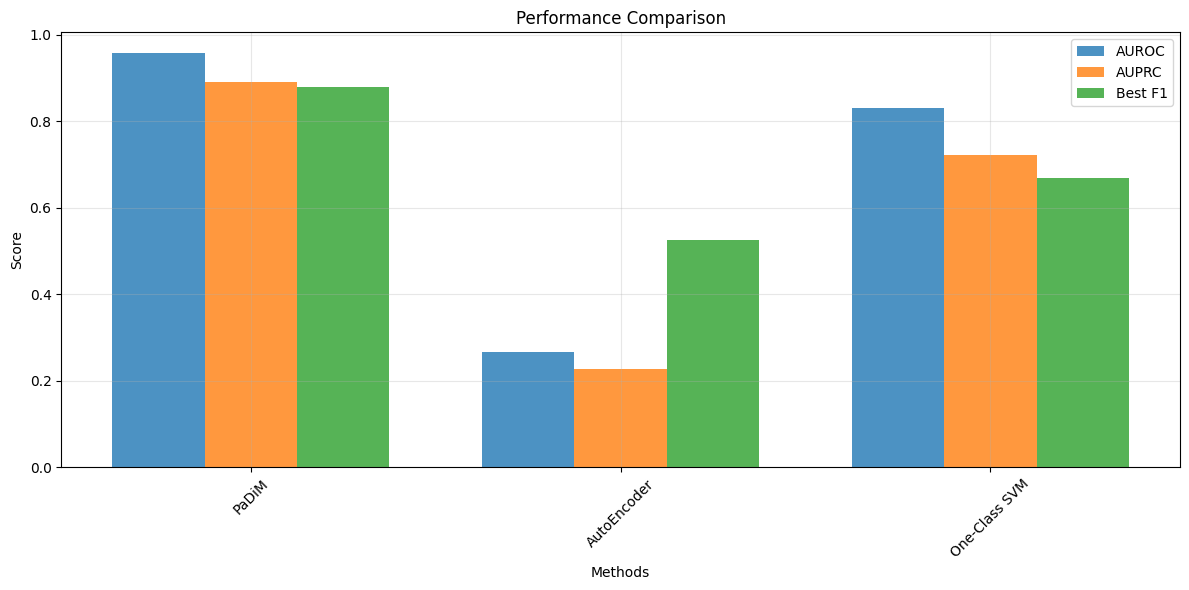

In [ ]:
system.evaluator.compare_methods()

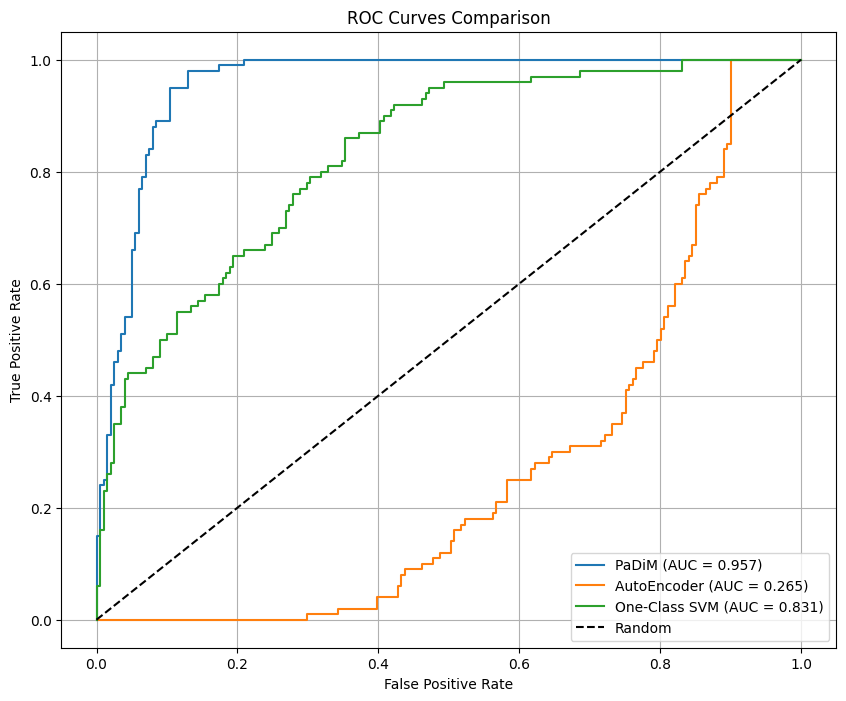

In [ ]:
system.evaluator.plot_roc_curve()

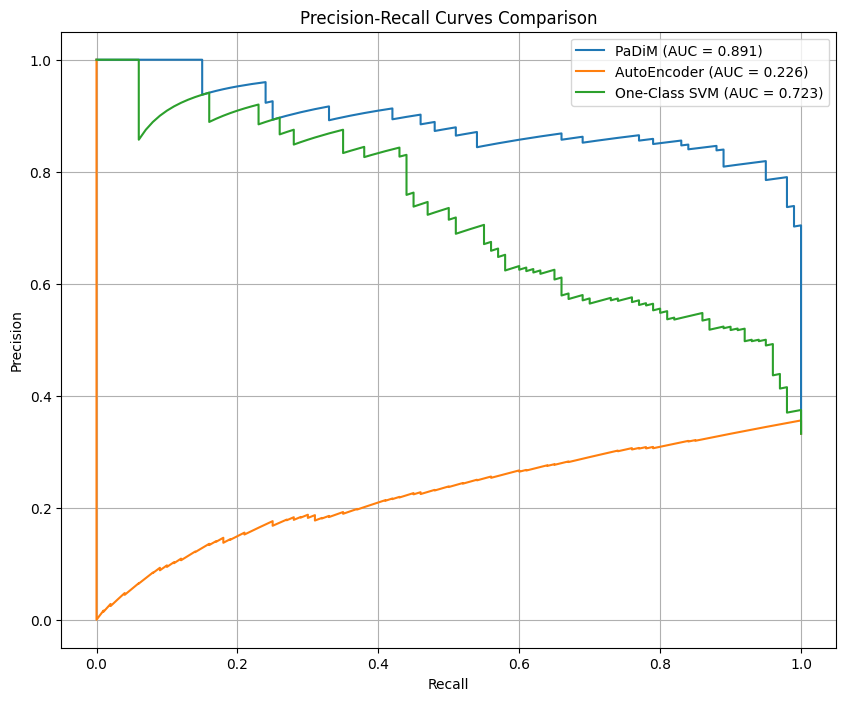

In [ ]:
system.evaluator.plot_precision_recall_curve()

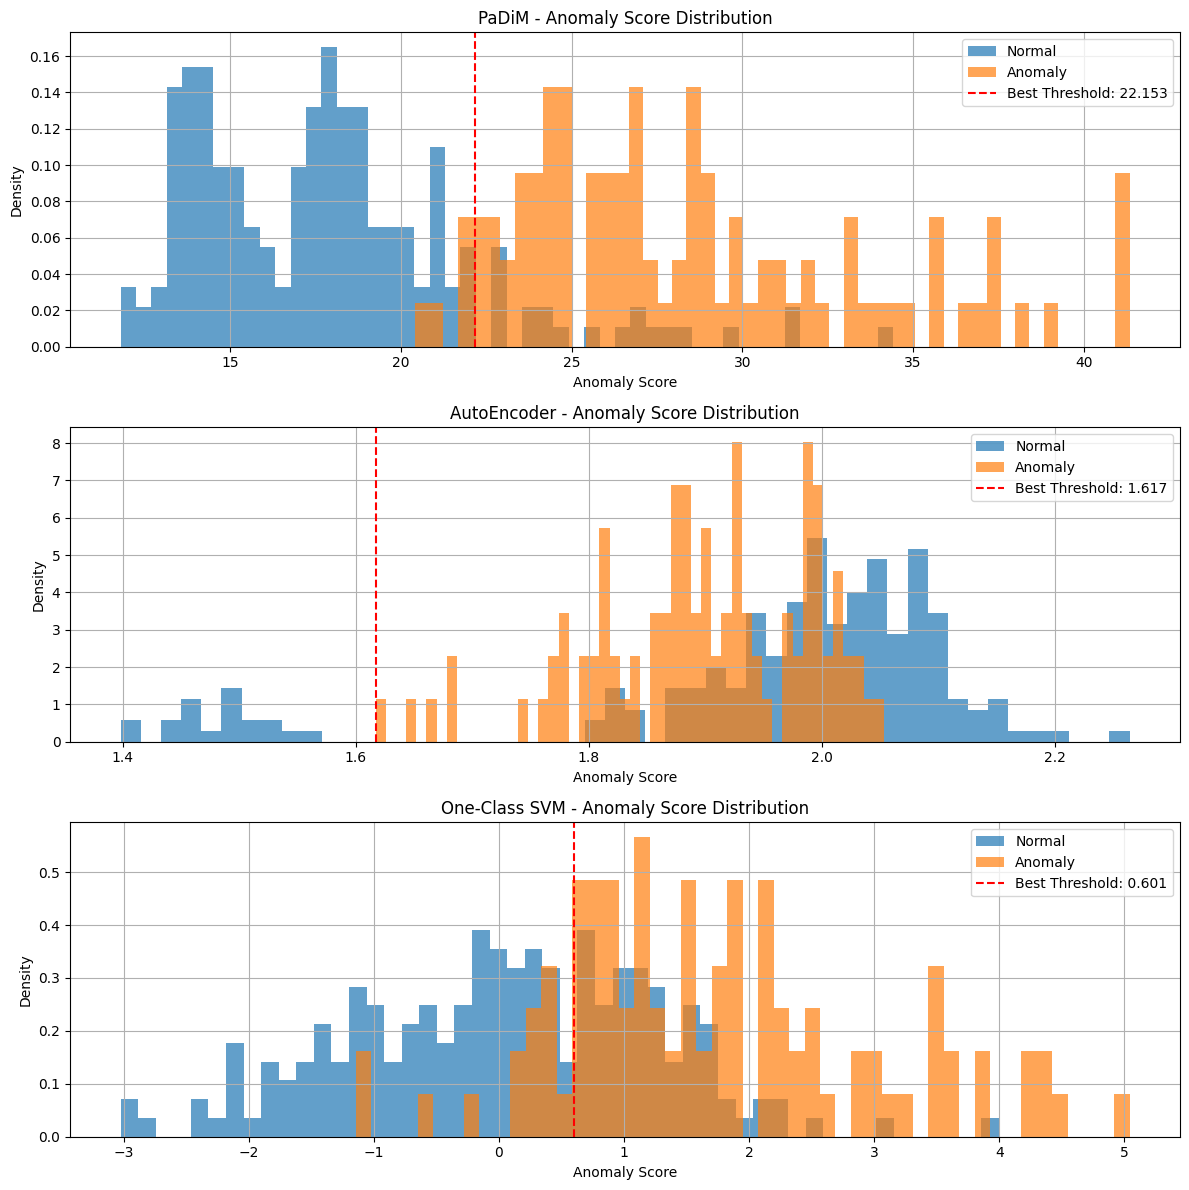

In [ ]:
system.evaluator.plot_score_distribution()

**📝 이론 정리 / 기능 묘사 / 코멘트**

- 이론 정리: 이상 탐지는 전체 정확도보다 불량을 잡는 비율(탐지율)과 정상을 불량으로 잘못 보는 비율(오탐율)로 평가하고, 임계값에 따라 둘의 균형이 달라진다. AUROC는 모든 임계값에서의 이 균형을 한 숫자로 나타낸다.
- 기능 묘사: 세 모델을 같은 데이터로 학습·평가하고, AUROC와 ROC·PR 곡선, 점수 분포로 비교했다.
- 코멘트: 일단 PaDiM은 잘 나왔지만, 점수에서 무작위 값이 0.5라고 알고 있었는데 AutoEncoder이 그것보다 낮아 뭔가 이상했다.

### 실시간 inference

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import cv2
import numpy as np
import torchvision.models as models

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc, roc_curve
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

import cv2
from PIL import Image
from pathlib import Path
import pickle
import json
from tqdm import tqdm
import warnings

In [ ]:
class VisADataset(Dataset):
    def __init__(self, data_path, category, transform=None, is_train=True, include_mask=False, train_ratio=0.8):
        self.data_path = Path(data_path)
        self.category = category
        self.transform = transform
        self.is_train = is_train
        self.include_mask = include_mask

        self.image_paths = []
        self.mask_paths = []
        self.labels = []
        self.defect_types = []

        category_path = self.data_path / category

        # CSV 파일에서 메타데이터 로드
        csv_path = category_path / "image_anno.csv"
        if csv_path.exists():
            df = pd.read_csv(csv_path)
            print(f"CSV 컬럼: {df.columns.tolist()}")

            # 정상/비정상 데이터 분리
            normal_df = df[df['label'] == 'normal'].copy()
            anomaly_df = df[df['label'] != 'normal'].copy()

            if self.is_train:
                # 훈련용: 정상 데이터의 일부만 사용
                train_size = int(len(normal_df) * train_ratio)
                selected_df = normal_df.iloc[:train_size]
                print(f"훈련용 정상 데이터: {len(selected_df)}개")
            else:
                # 테스트용: 나머지 정상 데이터 + 모든 비정상 데이터
                test_normal_size = len(normal_df) - int(len(normal_df) * train_ratio)
                test_normal_df = normal_df.iloc[-test_normal_size:] if test_normal_size > 0 else pd.DataFrame()
                selected_df = pd.concat([test_normal_df, anomaly_df], ignore_index=True)
                print(f"테스트용 정상 데이터: {len(test_normal_df)}개")
                print(f"테스트용 비정상 데이터: {len(anomaly_df)}개")

            # 데이터 로드
            for _, row in selected_df.iterrows():
                # 이미지 경로 처리 (중복 경로 제거)
                image_rel_path = row['image']
                if image_rel_path.startswith(category + '/'):
                    image_path = self.data_path / image_rel_path
                else:
                    image_path = category_path / image_rel_path

                if image_path.exists():
                    self.image_paths.append(str(image_path))
                    self.labels.append(0 if row['label'] == 'normal' else 1)
                    self.defect_types.append(row['label'])

                    # 마스크 경로 처리
                    if pd.notna(row['mask']) and self.include_mask:
                        mask_rel_path = row['mask']
                        if mask_rel_path.startswith(category + '/'):
                            mask_path = self.data_path / mask_rel_path
                        else:
                            mask_path = category_path / mask_rel_path
                        self.mask_paths.append(str(mask_path) if mask_path.exists() else None)
                    else:
                        self.mask_paths.append(None)
                else:
                    print(f"이미지 파일을 찾을 수 없습니다: {image_path}")
        else:
            print("CSV 파일이 없습니다. 폴더 구조를 기반으로 데이터를 로드합니다.")
            self._load_from_folder_structure()

    def _load_from_folder_structure(self):
        """폴더 구조를 기반으로 데이터 로드 (CSV가 없는 경우)"""
        category_path = self.data_path / self.category
        images_path = category_path / "Data" / "Images"
        masks_path = category_path / "Data" / "Masks"

        if self.is_train:
            # 훈련용: 정상 이미지만 사용
            normal_path = images_path / "Normal"
            if normal_path.exists():
                for img_path in normal_path.glob("*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
                        self.image_paths.append(str(img_path))
                        self.labels.append(0)  # 정상: 0
                        self.defect_types.append('normal')
                        self.mask_paths.append(None)
        else:
            # 테스트용: 정상 + 비정상 이미지
            # 정상 이미지
            normal_path = images_path / "Normal"
            if normal_path.exists():
                for img_path in normal_path.glob("*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
                        self.image_paths.append(str(img_path))
                        self.labels.append(0)
                        self.defect_types.append('normal')
                        self.mask_paths.append(None)

            # 비정상 이미지
            anomaly_path = images_path / "Anomaly"
            if anomaly_path.exists():
                for img_path in anomaly_path.glob("*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
                        self.image_paths.append(str(img_path))
                        self.labels.append(1)  # 이상: 1
                        self.defect_types.append('anomaly')

                        # 마스크 경로 찾기
                        if self.include_mask:
                            mask_name = img_path.stem + '.png'  # 확장자를 png로 변경
                            mask_path = masks_path / "Anomaly" / mask_name
                            self.mask_paths.append(str(mask_path) if mask_path.exists() else None)
                        else:
                            self.mask_paths.append(None)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # 이미지 로드
        image = Image.open(self.image_paths[idx]).convert('RGB')
        label = self.labels[idx]

        # 마스크 로드 (있는 경우)
        mask = None
        if self.include_mask and self.mask_paths[idx] is not None:
            try:
                mask = Image.open(self.mask_paths[idx]).convert('L')
            except:
                mask = None

        # 변환 적용
        if self.transform:
            image = self.transform(image)
            if mask is not None:
                mask_transform = transforms.Compose([
                    transforms.Resize((256, 256)),
                    transforms.ToTensor()
                ])
                mask = mask_transform(mask)

        result = {
            'image': image,
            'label': label,
            'defect_type': self.defect_types[idx]
        }

        if mask is not None:
            result['mask'] = mask

        return result

In [ ]:
def create_visa_data_loaders(data_path, category, batch_size=32, include_mask=False, train_ratio=0.8):
    """
    VisA 데이터셋용 데이터 로더 생성

    Args:
        data_path: VisA 데이터셋 경로
        category: 카테고리 이름
        batch_size: 배치 크기
        include_mask: 마스크 포함 여부
        train_ratio: 훈련 데이터 비율 (정상 데이터에서)
    """
    train_transform, test_transform = get_visa_transforms()

    train_dataset = VisADataset(
        data_path, category,
        transform=train_transform,
        is_train=True,
        include_mask=include_mask,
        train_ratio=train_ratio
    )

    test_dataset = VisADataset(
        data_path, category,
        transform=test_transform,
        is_train=False,
        include_mask=include_mask,
        train_ratio=train_ratio
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=2,  # Windows에서 문제가 있을 수 있으므로 낮춤
        pin_memory=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    return train_loader, test_loader


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
class FeatureExtractor(nn.Module):
    def __init__(self, model_name='resnet18', layers_to_extract=['layer1', 'layer2', 'layer3']):
        super(FeatureExtractor, self).__init__()

        if model_name == 'resnet18':
            self.model = models.resnet18(pretrained=True)
        elif model_name == 'resnet50':
            self.model = models.resnet50(pretrained=True)
        elif model_name == 'wide_resnet50':
            self.model = models.wide_resnet50_2(pretrained=True)
        else:
            raise ValueError(f"지원하지 않는 모델: {model_name}")

        self.layers_to_extract = layers_to_extract
        self.features = {}

        # Hook 등록
        for name, module in self.model.named_modules():
            if name in layers_to_extract:
                module.register_forward_hook(self.save_features(name))

        # 평가 모드로 설정
        self.model.eval()

        # 그래디언트 계산 비활성화
        for param in self.model.parameters():
            param.requires_grad = False

    def save_features(self, name):
        def hook(module, input, output):
            self.features[name] = output
        return hook

    def forward(self, x):
        self.features.clear()
        _ = self.model(x)
        return self.features

# Feature Extractor 초기화
feature_extractor = FeatureExtractor('wide_resnet50', ['layer2', 'layer3']).to(device)


In [ ]:
# --- PaDiM 클래스 (사용자 제공 코드, predict 수정) ---
class PaDiM:
    def __init__(self, feature_extractor, d_reduced=100, padim_patch_size=PADIM_PATCH_SIZE):
        self.feature_extractor = feature_extractor
        self.d_reduced = d_reduced
        self.padim_patch_size = padim_patch_size
        self.means = []
        self.inv_covariances = []
        self.projection_matrix = None

    def fit(self, train_loader):
        print("PaDiM 훈련 시작...")
        all_features = []
        for batch in tqdm(train_loader, desc="특징 추출 중"):
            images = batch['image'].to(device)
            with torch.no_grad():
                features = self.feature_extractor(images)
                for i in range(images.size(0)):
                    img_features = []
                    for layer_name, feat in features.items():
                        single_feat = feat[i:i+1]
                        feat_resized = F.adaptive_avg_pool2d(single_feat, (self.padim_patch_size, self.padim_patch_size))
                        feat_patches = feat_resized.permute(0, 2, 3, 1).reshape(self.padim_patch_size*self.padim_patch_size, -1)
                        img_features.append(feat_patches)
                    combined_features = torch.cat(img_features, dim=1)
                    all_features.append(combined_features)

        all_features = torch.cat(all_features, dim=0)
        print(f"전체 특징 크기: {all_features.shape}")

        if all_features.shape[1] > self.d_reduced:
            self.projection_matrix = torch.randn(all_features.shape[1], self.d_reduced).to(device)
            self.projection_matrix = F.normalize(self.projection_matrix, dim=0)
            all_features = torch.mm(all_features, self.projection_matrix)
            print(f"차원 축소 후 크기: {all_features.shape}")

        num_patches = self.padim_patch_size * self.padim_patch_size
        for patch_idx in range(num_patches):
            patch_features = all_features[patch_idx::num_patches]
            mean = torch.mean(patch_features, dim=0)
            centered_features = patch_features - mean
            cov = torch.mm(centered_features.T, centered_features) / (patch_features.shape[0] - 1)
            cov += torch.eye(cov.shape[0]).to(device) * 1e-4
            try:
                inv_cov = torch.linalg.inv(cov)
            except RuntimeError:
                inv_cov = torch.linalg.pinv(cov)
            self.means.append(mean)
            self.inv_covariances.append(inv_cov)
        print(f"PaDiM 훈련 완료! (패치 수: {len(self.means)})")

    def predict(self, images_tensor): # DataLoader 대신 이미지 텐서를 직접 받도록 수정
        """테스트 이미지 텐서에 대한 이상 점수 및 이상 맵 계산"""
        all_image_scores = []
        all_anomaly_maps = []

        with torch.no_grad():
            features = self.feature_extractor(images_tensor) # 이미지 텐서 바로 사용

            for i in range(images_tensor.size(0)):
                img_features = []
                for layer_name, feat in features.items():
                    single_feat = feat[i:i+1]
                    feat_resized = F.adaptive_avg_pool2d(single_feat, (self.padim_patch_size, self.padim_patch_size))
                    feat_patches = feat_resized.permute(0, 2, 3, 1).reshape(self.padim_patch_size*self.padim_patch_size, -1)
                    img_features.append(feat_patches)

                combined_features = torch.cat(img_features, dim=1)

                if self.projection_matrix is not None:
                    combined_features = torch.mm(combined_features, self.projection_matrix)

                patch_scores_for_image = []
                num_patches = self.padim_patch_size * self.padim_patch_size
                for patch_idx in range(num_patches):
                    diff = combined_features[patch_idx] - self.means[patch_idx]
                    mahal_dist = torch.sqrt(torch.mm(
                        torch.mm(diff.unsqueeze(0), self.inv_covariances[patch_idx]),
                        diff.unsqueeze(1)
                    )).item()
                    patch_scores_for_image.append(mahal_dist)

                all_image_scores.append(max(patch_scores_for_image))

                # 이상 맵 생성 (28x28 형태로)
                anomaly_map = torch.tensor(patch_scores_for_image).reshape(self.padim_patch_size, self.padim_patch_size).cpu().numpy()
                all_anomaly_maps.append(anomaly_map)

        return np.array(all_image_scores), np.array(all_anomaly_maps)

In [ ]:
def get_visa_transforms():
    """
    VisA 데이터셋에 적용할 이미지 변환(transform)을 반환합니다.
    실제 데이터셋과 모델에 맞게 이 부분을 수정해야 합니다.
    """
    train_transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=NORMALIZE_MEAN, std=NORMALIZE_STD)
    ])

    # 테스트 시에는 일반적으로 Augmentation을 많이 하지 않습니다.
    test_transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=NORMALIZE_MEAN, std=NORMALIZE_STD)
    ])
    return train_transform, test_transform


In [ ]:
# --- 데이터셋 경로 및 카테고리 설정 ---
# !!! 중요: 이 경로를 실제 VisA 데이터셋이 있는 경로로 수정해야 합니다 !!!
# 예시: DATA_PATH = "/path/to/your/visa_dataset"
# VisA 데이터셋이 없다면, 아래 예시처럼 직접 폴더를 만들고 소수의 이미지를 넣어 테스트할 수 있습니다.
# DATA_PATH/CATEGORY_NAME/train/good/img1.png, img2.png ...
# DATA_PATH/CATEGORY_NAME/test/good/img1.png, img2.png ...
# DATA_PATH/CATEGORY_NAME/test/anomaly_type1/img1.png, img2.png ...
DATA_PATH = "./VisA" # <--- 실제 데이터셋 경로로 변경하세요!
CATEGORY_NAME = "pcb4" # VisA 데이터셋의 카테고리 중 하나 (예: 'pcb', 'capsules' 등)
BATCH_SIZE = 8 # 메모리에 따라 조절
D_REDUCED = 100 # PaDiM의 축소된 특징 차원
IMG_SIZE = 256  # 입력 이미지 크기 (예시)
NORMALIZE_MEAN = [0.485, 0.456, 0.406]
NORMALIZE_STD = [0.229, 0.224, 0.225]
# PaDiM 내부에서 특징맵을 리사이즈할 크기 (고정)
PADIM_PATCH_SIZE = 28

# 결과물 저장 경로
OUTPUT_DIR = "padim_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
SAVED_MODEL_PATH = os.path.join(OUTPUT_DIR, "padim_model_state.pkl")

print(f"Data path set to: {DATA_PATH}")
print(f"Make sure you have data in the respective folders, e.g., {os.path.join(DATA_PATH, CATEGORY_NAME, 'train', 'good')}")
print("-" * 30)


# --- 모델 초기화 ---
print("FeatureExtractor 초기화 중...")
# 사용할 CNN 백본과 추출할 레이어 설정
# 예: wide_resnet50_2의 layer1, layer2, layer3 특징 사용
feature_extractor = FeatureExtractor(model_name='wide_resnet50', layers_to_extract=['layer1', 'layer2', 'layer3']).to(device)
print("PaDiM 모델 초기화 중...")
padim_model = PaDiM(feature_extractor=feature_extractor, d_reduced=D_REDUCED)

# --- 데이터 로더 생성 ---
print("데이터 로더 생성 중...")
try:
    train_loader, test_loader = create_visa_data_loaders(DATA_PATH, CATEGORY_NAME, BATCH_SIZE)

    # 훈련 데이터셋에 이미지가 있는지 확인
    if len(train_loader.dataset) == 0:
        print(f"훈련 데이터셋에 이미지가 없습니다! 경로를 확인하세요: {os.path.join(DATA_PATH, CATEGORY_NAME, 'train', 'good')}")
        # 이 경우 학습을 진행할 수 없으므로, 예외를 발생시키거나 중단할 수 있습니다.
        # raise ValueError("훈련 데이터가 비어있습니다. 학습을 진행할 수 없습니다.")
    else:
        print(f"훈련 데이터셋 크기: {len(train_loader.dataset)}")
        print(f"테스트 데이터셋 크기: {len(test_loader.dataset)}")

        # --- PaDiM 모델 학습 ---
        padim_model.fit(train_loader)

        # --- 학습된 모델 저장 ---
        print(f"학습된 PaDiM 모델을 '{SAVED_MODEL_PATH}'에 저장합니다...")
        # PaDiM 클래스 전체를 저장하거나, 필요한 attribute만 저장할 수 있습니다.
        # 여기서는 주요 attribute들을 딕셔너리 형태로 저장합니다.
        padim_state = {
            'means': padim_model.means,
            'inv_covariances': padim_model.inv_covariances,
            'projection_matrix': padim_model.projection_matrix,
            'd_reduced': padim_model.d_reduced,
            'padim_patch_size': padim_model.padim_patch_size
            # FeatureExtractor는 구조가 동일하므로 저장하지 않고 추론 시 새로 생성
        }
        with open(SAVED_MODEL_PATH, 'wb') as f:
            pickle.dump(padim_state, f)
        print("모델 저장 완료.")

except FileNotFoundError as e:
    print(f"데이터 경로 오류: {e}")
    print("DATA_PATH 및 CATEGORY_NAME을 올바르게 설정하고, 해당 경로에 이미지 파일이 있는지 확인해주세요.")
except Exception as e:
    print(f"학습 중 오류 발생: {e}")



Data path set to: ./VisA
Make sure you have data in the respective folders, e.g., ./VisA/pcb4/train/good
------------------------------
FeatureExtractor 초기화 중...


PaDiM 모델 초기화 중...
데이터 로더 생성 중...
CSV 컬럼: ['image', 'label', 'mask']
훈련용 정상 데이터: 804개
CSV 컬럼: ['image', 'label', 'mask']
테스트용 정상 데이터: 201개
테스트용 비정상 데이터: 100개
훈련 데이터셋 크기: 804
테스트 데이터셋 크기: 301
PaDiM 훈련 시작...



특징 추출 중:   0%|          | 0/101 [00:00<?, ?it/s]


특징 추출 중:   1%|          | 1/101 [00:00<00:44,  2.25it/s]


특징 추출 중:   3%|▎         | 3/101 [00:00<00:18,  5.19it/s]

...


특징 추출 중: 100%|██████████| 101/101 [00:12<00:00,  9.51it/s]


특징 추출 중: 100%|██████████| 101/101 [00:12<00:00,  7.95it/s]

전체 특징 크기: torch.Size([630336, 1792])
차원 축소 후 크기: torch.Size([630336, 100])


PaDiM 훈련 완료! (패치 수: 784)
학습된 PaDiM 모델을 'padim_outputs/padim_model_state.pkl'에 저장합니다...


모델 저장 완료.


In [ ]:
# --- 저장된 PaDiM 모델 로드 함수 ---
def load_padim_model_state(filepath, feature_extractor_instance):
    if not os.path.exists(filepath):
        print(f"저장된 모델 파일이 없습니다: {filepath}")
        return None

    with open(filepath, 'rb') as f:
        padim_state = pickle.load(f)

    # 새 PaDiM 인스턴스를 만들고 상태를 로드
    loaded_model = PaDiM(feature_extractor_instance,
                           d_reduced=padim_state.get('d_reduced', 100), # 기본값 설정
                           padim_patch_size=padim_state.get('padim_patch_size', PADIM_PATCH_SIZE)) # 기본값 설정
    loaded_model.means = padim_state['means']
    loaded_model.inv_covariances = padim_state['inv_covariances']
    loaded_model.projection_matrix = padim_state['projection_matrix']

    print(f"'{filepath}'에서 PaDiM 모델 상태 로드 완료.")
    return loaded_model

# --- Gradio 추론 함수 ---
# 모델 로드는 Gradio 앱 시작 시 한 번만 수행하도록 전역 변수로 관리
gradio_feature_extractor = None
gradio_padim_model = None
_, gradio_test_transform = get_visa_transforms() # 테스트용 변환 사용

def initialize_gradio_models():
    global gradio_feature_extractor, gradio_padim_model
    if gradio_feature_extractor is None:
        print("Gradio: FeatureExtractor 초기화 중...")
        gradio_feature_extractor = FeatureExtractor(model_name='wide_resnet50', layers_to_extract=['layer1', 'layer2', 'layer3']).to(device)

    if gradio_padim_model is None:
        print("Gradio: 저장된 PaDiM 모델 로드 중...")
        gradio_padim_model = load_padim_model_state(SAVED_MODEL_PATH, gradio_feature_extractor)
        if gradio_padim_model is None:
            print("Gradio: 모델 로드 실패! 학습을 먼저 실행하거나 모델 경로를 확인하세요.")
            # Gradio 인터페이스 실행 전에 모델이 로드되었는지 확인 필요

# Gradio 앱 시작 전에 모델 초기화 시도
initialize_gradio_models()


def padim_inference_gradio(input_image_pil):
    """Gradio 인터페이스를 위한 추론 함수"""
    if gradio_padim_model is None:
        return "모델이 로드되지 않았습니다. 학습을 먼저 실행하거나 모델 경로를 확인하세요.", None, None

    # PIL 이미지를 PyTorch 텐서로 변환 및 전처리
    img_tensor = gradio_test_transform(input_image_pil).unsqueeze(0).to(device) # 배치 차원 추가

    # PaDiM 모델로 추론
    image_score, anomaly_map_array = gradio_padim_model.predict(img_tensor)

    # 결과 처리
    score = image_score[0] # 단일 이미지이므로 첫 번째 점수 사용
    anomaly_map_single = anomaly_map_array[0] # 단일 이미지의 이상 맵

    # 이상 맵 시각화 (Heatmap)
    # 0-1 범위로 정규화 후 컬러맵 적용
    anomaly_map_normalized = (anomaly_map_single - np.min(anomaly_map_single)) / \
                             (np.max(anomaly_map_single) - np.min(anomaly_map_single) + 1e-6)

    heatmap_img = cv2.applyColorMap(np.uint8(255 * anomaly_map_normalized), cv2.COLORMAP_JET)
    heatmap_img = cv2.cvtColor(heatmap_img, cv2.COLOR_BGR2RGB) # Matplotlib/Gradio용 RGB

    # 원본 이미지에 히트맵 오버레이 (PIL 이미지를 NumPy로 변환 후 사용)
    original_np = np.array(input_image_pil.resize((IMG_SIZE, IMG_SIZE)))
    if original_np.shape[2] == 4: # RGBA -> RGB
        original_np = original_np[..., :3]

    heatmap_resized = cv2.resize(heatmap_img, (original_np.shape[1], original_np.shape[0]))
    overlayed_image = cv2.addWeighted(original_np, 0.6, heatmap_resized, 0.4, 0)

    result_text = f"이상 점수(Anomaly Score): {score:.4f}"
    if score > 15: # 임계값 예시 (데이터와 모델에 따라 크게 달라짐, 튜닝 필요!)
        result_text += "\n판정: 비정상 (Anomaly)"
    else:
        result_text += "\n판정: 정상 (Normal)"

    return result_text, heatmap_img, overlayed_image



Gradio: FeatureExtractor 초기화 중...


Gradio: 저장된 PaDiM 모델 로드 중...


'padim_outputs/padim_model_state.pkl'에서 PaDiM 모델 상태 로드 완료.


In [ ]:
import gradio as gr

In [ ]:
# --- Gradio 인터페이스 생성 및 실행 ---
if gradio_padim_model is not None: # 모델이 성공적으로 로드된 경우에만 인터페이스 실행
    iface = gr.Interface(
        fn=padim_inference_gradio,
        inputs=gr.Image(type="pil", label="검사할 이미지 업로드"),
        outputs=[
            gr.Textbox(label="결과"),
            gr.Image(type="numpy", label="이상 맵 (Anomaly Map Heatmap)"),
            gr.Image(type="numpy", label="오버레이된 이미지 (Overlayed Image)")
        ],
        title="PaDiM 이상 탐지 시스템 (VisA Dataset)",
        description="이미지를 업로드하여 정상/비정상 여부를 판별하고 이상 영역을 확인합니다. (백본: WideResNet50)",
        examples=[ # 예제 이미지가 있다면 경로를 지정 (Gradio에서 클릭 가능)
        ] if os.path.exists(os.path.join(DATA_PATH, CATEGORY_NAME, "test")) else None # 예제 폴더가 있을 때만 추가
    )

    iface.launch(share=True) # share=True로 하면 외부에서 접속 가능한 링크 생성 (주의해서 사용)
else:
    print("-" * 50)
    print("!!! PaDiM 모델이 로드되지 않았습니다. Gradio 인터페이스를 시작할 수 없습니다. !!!")
    print("!!! 셀 7에서 모델 학습 및 저장이 성공적으로 완료되었는지, SAVED_MODEL_PATH가 올바른지 확인해주세요. !!!")
    print("-" * 50)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()


* Running on public URL: https://33c4ff5d3ad184e8ac.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


**📝 이론 정리 / 기능 묘사 / 코멘트**

- 이론 정리: 생산 라인에서는 밀리초 단위의 실시간 판정이 필요해서, 학습한 모델을 저장해 두고 현장에서는 추론만 빠르게 돌린다. PaDiM은 이상 점수 맵을 주기 때문에 결함 위치를 화면에 바로 보여 줄 수 있다.
- 기능 묘사: 가장 좋았던 PaDiM을 다시 학습해 저장하고, Gradio로 이미지를 올리면 이상 점수와 히트맵을 보여 주는 화면을 만들었다.
- 코멘트: gradio로 이전에 zerogpu나 modal을 이용해 GPU를 사용하는 관련 웹사이트를 만든 적이 있었는데, 이번에도 보게 되어 반가웠다.

# 추가 실험: 모델 성능 검증

- Test 1·2: 위 비교에서 PaDiM의 AUROC가 가장 높았다. 이 점수가 실제로 결함을 찾아서 나온 것인지 확인한다.
- Test 3: AutoEncoder는 AUROC가 무작위(0.5)보다 낮았다. 그 원인을 epoch별 학습 기록으로 확인한다.
- Test 4: 데이터사이언스에서 많이 쓰는 CatBoost(불량 라벨 사용)를 Test 1과 같은 잣대로 비교한다.

**배경 (데이터 특성)**: pcb4에는 인쇄가 다른 기판이 섞여 있다. 불량 100장 중 99장이 `FC-75`가 인쇄된 기판인데, 정상은 1,005장 중 91장(9.1%)만 `FC-75`다. 노트북 분할에서는 학습용 정상의 1.5%, 테스트용 정상의 39.3%가 `FC-75`다. 기판 종류 라벨(`pcb4_variant_labels.csv`)은 `FC-75` 인쇄 템플릿 매칭으로 전체를 판별해 만들었다. 만든 방법과 검증은 아래 "Test 1·2의 바탕"에 적었다.

**Test 1·2 공통 실험 조건** (Test 3 조건은 Test 3 첫머리에 따로 적었다)

| 항목 | 설정 |
|---|---|
| 모델 | 위 평가와 같은 PaDiM (Wide-ResNet50 layer2+3, 28×28 패치, 무작위 투영 100차원) |
| 분할 | ① 노트북 분할 (CSV 순서 앞 80% 정상으로 학습, 원본 셀과 같은 조건) ② VisA 공식 `1cls` 분할 |
| 반복 | 시드 0~4 (무작위 투영, 학습 순서, 좌우 반전이 바뀜) → 평균 ± 표준편차 |
| 신뢰구간 | seed 0, 이미지 단위 부트스트랩 2,000회, 95% |
| 추가한 코드 | 28×28 이상 맵을 함께 구하는 함수. 이미지 점수는 원본 `predict` 값을 그대로 쓰고, 이상 맵의 최댓값과 같은지 확인한다 |

판정 기준은 실행 전에 정해 각 Test 첫머리에 적었다.

In [ ]:
# @title 평가 부분과 같은 설정 다시 만들기 (전처리, PaDiM, layer2+3 특징 추출기)
# 데이터 전처리 정의
def get_visa_transforms():
    train_transform = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                           std=[0.229, 0.224, 0.225])
    ])

    test_transform = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                           std=[0.229, 0.224, 0.225])
    ])

    return train_transform, test_transform


class PaDiM:
    def __init__(self, feature_extractor, d_reduced=100):
        self.feature_extractor = feature_extractor
        self.d_reduced = d_reduced
        self.means = []
        self.inv_covariances = []
        self.projection_matrix = None

    def fit(self, train_loader):
        """정상 데이터로 모델 훈련"""
        print("PaDiM 훈련 시작...")

        # 모든 훈련 데이터에서 특징 추출
        all_features = []

        for batch in tqdm(train_loader, desc="특징 추출 중"):
            images = batch['image'].to(device)

            with torch.no_grad():
                features = self.feature_extractor(images)

                # 각 이미지별로 처리
                for i in range(images.size(0)):
                    img_features = []

                    # 레이어별 특징 추출 및 결합
                    for layer_name, feat in features.items():
                        # 단일 이미지 특징 추출
                        single_feat = feat[i:i+1]  # [1, C, H, W]

                        # 28x28로 리사이즈
                        feat_resized = F.adaptive_avg_pool2d(single_feat, (28, 28))

                        # 패치별 특징으로 변환 [784, C]
                        feat_patches = feat_resized.permute(0, 2, 3, 1).reshape(28*28, -1)
                        img_features.append(feat_patches)

                    # 레이어별 특징 결합 [784, total_channels]
                    combined_features = torch.cat(img_features, dim=1)
                    all_features.append(combined_features)

        # 모든 특징을 하나로 결합 [N*784, total_channels]
        all_features = torch.cat(all_features, dim=0)
        print(f"전체 특징 크기: {all_features.shape}")

        # 차원 축소를 위한 Random Projection 행렬 생성
        if all_features.shape[1] > self.d_reduced:
            self.projection_matrix = torch.randn(all_features.shape[1], self.d_reduced).to(device)
            # 정규화
            self.projection_matrix = F.normalize(self.projection_matrix, dim=0)

            # 차원 축소 적용
            all_features = torch.mm(all_features, self.projection_matrix)
            print(f"차원 축소 후 크기: {all_features.shape}")

        # 패치 위치별로 분리하여 통계 계산
        n_samples = len(all_features) // (28 * 28)

        for patch_idx in range(28 * 28):
            # 특정 패치 위치의 모든 특징 추출
            patch_features = all_features[patch_idx::28*28]  # [n_samples, d_reduced]

            # 평균과 공분산 계산
            mean = torch.mean(patch_features, dim=0)

            # 공분산 행렬 계산 (정규화 추가)
            centered_features = patch_features - mean
            cov = torch.mm(centered_features.T, centered_features) / (patch_features.shape[0] - 1)

            # 수치 안정성을 위한 정규화
            cov += torch.eye(cov.shape[0]).to(device) * 1e-4

            # 역행렬 계산
            try:
                inv_cov = torch.linalg.inv(cov)
            except:
                # 특이행렬인 경우 pseudo-inverse 사용
                inv_cov = torch.linalg.pinv(cov)

            self.means.append(mean)
            self.inv_covariances.append(inv_cov)

        print(f"PaDiM 훈련 완료! (패치 수: {len(self.means)})")

    def predict(self, test_loader):
        """테스트 데이터에 대한 이상 점수 계산"""
        anomaly_scores = []

        for batch in tqdm(test_loader, desc="이상 탐지 중"):
            images = batch['image'].to(device)

            with torch.no_grad():
                features = self.feature_extractor(images)

                # 각 이미지별로 처리
                for i in range(images.size(0)):
                    img_features = []

                    # 레이어별 특징 추출 및 결합
                    for layer_name, feat in features.items():
                        single_feat = feat[i:i+1]
                        feat_resized = F.adaptive_avg_pool2d(single_feat, (28, 28))
                        feat_patches = feat_resized.permute(0, 2, 3, 1).reshape(28*28, -1)
                        img_features.append(feat_patches)

                    combined_features = torch.cat(img_features, dim=1)

                    # 차원 축소 (훈련 시와 동일한 방식)
                    if self.projection_matrix is not None:
                        combined_features = torch.mm(combined_features, self.projection_matrix)

                    # 각 패치별 Mahalanobis 거리 계산
                    patch_scores = []
                    for patch_idx in range(28 * 28):
                        diff = combined_features[patch_idx] - self.means[patch_idx]

                        # Mahalanobis 거리 계산
                        mahal_dist = torch.sqrt(torch.mm(
                            torch.mm(diff.unsqueeze(0), self.inv_covariances[patch_idx]),
                            diff.unsqueeze(1)
                        )).item()

                        patch_scores.append(mahal_dist)

                    # 전체 이상 점수 (최대값 사용)
                    anomaly_scores.append(max(patch_scores))

        return np.array(anomaly_scores), None


feature_extractor = FeatureExtractor('wide_resnet50', ['layer2', 'layer3']).to(device)


In [ ]:
# @title 추가 실험 공통 도구 (분할, 이상 맵, 지표)
import io, contextlib, random
from scipy import ndimage

TEST_DATA_PATH = './VisA'
VARIANT = pd.read_csv('pcb4_variant_labels.csv')       # 기판 종류 라벨 (fc75: True/False)
FC75 = dict(zip(VARIANT['image'], VARIANT['fc75']))
ANNO = pd.read_csv(f'{TEST_DATA_PATH}/pcb4/image_anno.csv')
MASK_OF = dict(zip(ANNO['image'], ANNO['mask']))
SEEDS = [0, 1, 2, 3, 4]
GRID = 28                                              # PaDiM 패치 격자 (28×28)
RESULT_DIR = 'test_results'
os.makedirs(RESULT_DIR, exist_ok=True)
_trapezoid = getattr(np, 'trapezoid', None) or np.trapz


def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


@contextlib.contextmanager
def quiet():
    """PaDiM의 진행 막대와 출력을 실험 중에만 숨긴다"""
    global tqdm
    original_tqdm = tqdm
    tqdm = lambda iterable, **kwargs: iterable
    try:
        with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
            yield
    finally:
        tqdm = original_tqdm


def make_dataset(rel_paths, labels, defect_types, transform):
    """공식 분할 목록을 그대로 넣은 VisADataset (CSV 순서 분할 대신)"""
    ds = VisADataset.__new__(VisADataset)
    ds.data_path, ds.category, ds.transform = Path(TEST_DATA_PATH), 'pcb4', transform
    ds.is_train, ds.include_mask = None, False
    ds.image_paths = [str(Path(TEST_DATA_PATH) / p) for p in rel_paths]
    ds.labels, ds.defect_types = list(labels), list(defect_types)
    ds.mask_paths = [None] * len(rel_paths)
    return ds


def build_splits():
    """노트북 분할(원본 셀과 같은 조건: batch 16, include_mask=False, train_ratio 0.8)과 공식 1cls 분할"""
    with quiet():
        nb_train, nb_test = create_visa_data_loaders(TEST_DATA_PATH, 'pcb4', batch_size=16,
                                                     include_mask=False, train_ratio=0.8)
    train_tf, test_tf = get_visa_transforms()
    tr = VARIANT[VARIANT.official_split == 'train']
    te = VARIANT[VARIANT.official_split == 'test']
    off_train = make_dataset(tr.image, (tr.label != 'normal').astype(int), tr.label, train_tf)
    off_test = make_dataset(te.image, (te.label != 'normal').astype(int), te.label, test_tf)
    kw = dict(batch_size=16, num_workers=2, pin_memory=True)
    return {'notebook': (nb_train, nb_test),
            'official': (DataLoader(off_train, shuffle=True, **kw), DataLoader(off_test, shuffle=False, **kw))}


def padim_maps(padim, loader):
    """원본 PaDiM.predict와 같은 계산(위치별 마할라노비스 거리)을 한 번에 해서 28×28 이상 맵을 구한다"""
    means = torch.stack(padim.means)                    # [784, d]
    inv_covs = torch.stack(padim.inv_covariances)       # [784, d, d]
    maps = []
    with torch.no_grad():
        for batch in loader:
            images = batch['image'].to(device)
            feats = padim.feature_extractor(images)
            x = torch.cat([F.adaptive_avg_pool2d(f, (GRID, GRID)).permute(0, 2, 3, 1).reshape(images.size(0), GRID * GRID, -1)
                           for f in feats.values()], dim=2)
            if padim.projection_matrix is not None:
                x = x @ padim.projection_matrix
            diff = x - means
            d2 = (torch.einsum('bpi,pij->bpj', diff, inv_covs) * diff).sum(-1)
            maps.append(d2.clamp_min(0).sqrt().reshape(-1, GRID, GRID).cpu().numpy())
    return np.concatenate(maps)


def run_once(train_loader, test_loader, seed):
    """원본 PaDiM(d_reduced=100) 학습 → 원본 predict 점수 + 이상 맵. 시드만 고정"""
    set_seed(seed)
    padim = PaDiM(feature_extractor, d_reduced=100)
    with quiet():
        padim.fit(train_loader)
        scores, _ = padim.predict(test_loader)
    scores = np.asarray(scores)
    maps = padim_maps(padim, test_loader)
    gap = float(np.abs(maps.reshape(len(maps), -1).max(1) - scores).max())
    del padim
    torch.cuda.empty_cache()
    return scores, maps, gap


def frame(dataset, scores):
    rel = [os.path.relpath(p, TEST_DATA_PATH) for p in dataset.image_paths]
    return pd.DataFrame({'image': rel, 'label': dataset.labels,
                         'fc75': [bool(FC75[r]) for r in rel], 'score': scores})


def load_masks(dataset, size=256):
    """테스트 이미지의 정답 마스크(정상은 전부 0). 원본 전처리처럼 256×256으로 맞춘다"""
    out = np.zeros((len(dataset.image_paths), size, size), dtype=bool)
    for i, p in enumerate(dataset.image_paths):
        m = MASK_OF.get(os.path.relpath(p, TEST_DATA_PATH))
        if isinstance(m, str):
            img = Image.open(Path(TEST_DATA_PATH) / m).convert('L').resize((size, size), Image.NEAREST)
            out[i] = np.array(img) > 0
    return out


def groups(df, col='score'):
    return {'normal_nonfc': df[(df.label == 0) & ~df.fc75][col].values,
            'normal_fc': df[(df.label == 0) & df.fc75][col].values,
            'anomaly_fc': df[(df.label == 1) & df.fc75][col].values,
            'normal': df[df.label == 0][col].values,
            'anomaly': df[df.label == 1][col].values}


def auroc(neg, pos):
    y = np.r_[np.zeros(len(neg)), np.ones(len(pos))]
    return roc_auc_score(y, np.r_[neg, pos])


def boot_ci(neg, pos, n=2000, seed=0):
    """음성·양성을 각각 복원 추출하는 부트스트랩 95% 신뢰구간"""
    rng = np.random.default_rng(seed)
    neg, pos = np.asarray(neg), np.asarray(pos)
    vals = [auroc(rng.choice(neg, len(neg)), rng.choice(pos, len(pos))) for _ in range(n)]
    return np.percentile(vals, [2.5, 97.5])


def test1_metrics(df):
    g = groups(df)
    thr = np.sort(g['anomaly'])[int(len(g['anomaly']) * 0.10)]   # 불량 90%를 잡는 임계값
    return {'auroc_all': roc_auc_score(df.label, df.score),
            'same_variant': auroc(g['normal_fc'], g['anomaly_fc']),
            'cross_variant': auroc(g['normal_nonfc'], g['anomaly_fc']),
            'variant_reaction': auroc(g['normal_nonfc'], g['normal_fc']),
            'fpr_fc75_normal': float((g['normal_fc'] >= thr).mean()),
            'fpr_nonfc75_normal': float((g['normal_nonfc'] >= thr).mean()),
            'mean_normal_nonfc': g['normal_nonfc'].mean(), 'mean_normal_fc': g['normal_fc'].mean(),
            'mean_anomaly_fc': g['anomaly_fc'].mean()}


def mean_std_table(df, cols, names, by='split', digits=3):
    g = df.groupby(by)[cols]
    m, s = g.mean(), g.std()
    return pd.DataFrame({k: [f'{m.loc[k, c]:.{digits}f} ± {s.loc[k, c]:.{digits}f}' for c in cols] for k in m.index},
                        index=[names[c] for c in cols])


def patch_masks(masks256, r):
    """정답 마스크를 28×28 격자로 줄이고(한 칸이라도 겹치면 포함) r칸 넓힌다"""
    m = torch.from_numpy(masks256[:, None].astype(np.float32))
    pm = F.adaptive_max_pool2d(m, (GRID, GRID))
    if r > 0:
        pm = F.max_pool2d(pm, kernel_size=2 * r + 1, stride=1, padding=r)
    return pm[:, 0].numpy() > 0


def masked_max(maps, excl):
    """excl 위치를 뺀 나머지의 최댓값 (거리는 0 이상이라 뺀 자리는 0으로 둔다)"""
    return np.where(excl, 0.0, maps).reshape(len(maps), -1).max(1)


def exp_a_scores(maps, df, masks256, r):
    """실험 A 점수. 불량: 자기 결함 마스크를 뺀 최댓값 / 정상: 불량 마스크를 하나씩 똑같이 빼고 평균 (빼는 면적을 맞춤)"""
    pm = patch_masks(masks256, r)
    is_anom = df.label.values == 1
    s = np.empty(len(df))
    s[is_anom] = masked_max(maps[is_anom], pm[is_anom])
    normal_maps = maps[~is_anom]
    s[~is_anom] = np.mean([masked_max(normal_maps, np.broadcast_to(m, normal_maps.shape)) for m in pm[is_anom]], axis=0)
    return s


def upsample_smooth(maps, size=256, sigma=4):
    """이중선형 업샘플 후 가우시안(σ=4)"""
    up = F.interpolate(torch.from_numpy(maps)[:, None].float(), size=(size, size), mode='bilinear', align_corners=False)[:, 0].numpy()
    return np.stack([ndimage.gaussian_filter(m, sigma=sigma) for m in up])


def aupro(score, gt, max_fpr=0.3, n_points=300):
    """PRO 곡선 아래 면적 (FPR 0~max_fpr 구간, max_fpr로 나눠 0~1). 결함 영역마다 덮은 비율을 평균"""
    normal_px = np.sort(score[~gt])
    fprs = np.linspace(0, max_fpr, n_points)
    idx = np.clip(np.ceil((1 - fprs) * len(normal_px)).astype(int) - 1, 0, len(normal_px) - 1)
    thr = normal_px[idx]
    real_fpr = 1 - np.searchsorted(normal_px, thr, side='left') / len(normal_px)
    regions = []
    for s_img, g_img in zip(score, gt):
        if g_img.any():
            lab, n = ndimage.label(g_img)
            regions += [np.sort(s_img[lab == k]) for k in range(1, n + 1)]
    pro = np.mean([1 - np.searchsorted(r, thr, side='left') / len(r) for r in regions], axis=0)
    keep = real_fpr <= max_fpr
    return float(_trapezoid(pro[keep], real_fpr[keep]) / max_fpr), real_fpr, pro


def pointing(maps, masks256, r):
    """불량 이미지에서 이상 맵 최댓값(= 이미지 점수 위치)이 마스크 안에 있는 비율과 무작위 기대값"""
    pm = patch_masks(masks256, r).reshape(len(maps), -1)
    hit = pm[np.arange(len(maps)), maps.reshape(len(maps), -1).argmax(1)]
    return float(hit.mean()), float(pm.mean(1).mean())

print('기판 라벨', VARIANT.shape, '| FC-75 정상', int(((VARIANT.label == 'normal') & VARIANT.fc75).sum()),
      '| FC-75 불량', int(((VARIANT.label != 'normal') & VARIANT.fc75).sum()))


기판 라벨 (1105, 7) | FC-75 정상 91 | FC-75 불량 99


In [ ]:
# @title 추가 실험 실행: 분할 2개 × 시드 5개 = PaDiM 10회 (이미지 점수와 이상 맵 저장)
SPLITS = build_splits()
RUNS, MASKS = {}, {}
for split, (train_loader, test_loader) in SPLITS.items():
    MASKS[split] = load_masks(test_loader.dataset)
    for seed in SEEDS:
        scores, maps, gap = run_once(train_loader, test_loader, seed)
        df = frame(test_loader.dataset, scores)
        RUNS[(split, seed)] = (df, maps)
        print(f'{split:8s} seed {seed}: 학습 {len(train_loader.dataset)}장, 테스트 {len(df)}장 (불량 {int(df.label.sum())}) '
              f'| AUROC {roc_auc_score(df.label, df.score):.4f} | 이상 맵 최댓값 - 원본 점수 최대 차이 {gap:.1e}')
REL_GAP = max(float(np.abs(m.reshape(len(m), -1).max(1) - d.score.values).max() / d.score.abs().max()) for d, m in RUNS.values())
print('이상 맵 최댓값 = 원본 predict 점수:', REL_GAP < 1e-4, f'(최대 상대 차이 {REL_GAP:.1e})')
pd.concat([d.assign(split=s, seed=k) for (s, k), (d, _) in RUNS.items()]).to_csv(f'{RESULT_DIR}/scores_by_image.csv', index=False)
np.savez_compressed(f'{RESULT_DIR}/anomaly_maps.npz', **{f'{s}_seed{k}': m for (s, k), (_, m) in RUNS.items()})


notebook seed 0: 학습 804장, 테스트 301장 (불량 100) | AUROC 0.9535 | 이상 맵 최댓값 - 원본 점수 최대 차이 7.6e-06


notebook seed 1: 학습 804장, 테스트 301장 (불량 100) | AUROC 0.9616 | 이상 맵 최댓값 - 원본 점수 최대 차이 7.6e-06


notebook seed 2: 학습 804장, 테스트 301장 (불량 100) | AUROC 0.9573 | 이상 맵 최댓값 - 원본 점수 최대 차이 7.6e-06


notebook seed 3: 학습 804장, 테스트 301장 (불량 100) | AUROC 0.9640 | 이상 맵 최댓값 - 원본 점수 최대 차이 7.6e-06


notebook seed 4: 학습 804장, 테스트 301장 (불량 100) | AUROC 0.9638 | 이상 맵 최댓값 - 원본 점수 최대 차이 7.6e-06


official seed 0: 학습 904장, 테스트 201장 (불량 100) | AUROC 0.9460 | 이상 맵 최댓값 - 원본 점수 최대 차이 7.6e-06


official seed 1: 학습 904장, 테스트 201장 (불량 100) | AUROC 0.9458 | 이상 맵 최댓값 - 원본 점수 최대 차이 5.7e-06


official seed 2: 학습 904장, 테스트 201장 (불량 100) | AUROC 0.9542 | 이상 맵 최댓값 - 원본 점수 최대 차이 9.5e-06


official seed 3: 학습 904장, 테스트 201장 (불량 100) | AUROC 0.9555 | 이상 맵 최댓값 - 원본 점수 최대 차이 6.7e-06


official seed 4: 학습 904장, 테스트 201장 (불량 100) | AUROC 0.9546 | 이상 맵 최댓값 - 원본 점수 최대 차이 7.6e-06
이상 맵 최댓값 = 원본 predict 점수: True (최대 상대 차이 2.3e-07)


## Test 1 분석: 기판 종류 지름길 검증

**질문 (RQ1)**: PaDiM이 결함이 아니라 기판 종류(`FC-75` 인쇄)를 보고 불량을 구분하는가?

**가설**: 불량은 거의 다 `FC-75` 기판이고, 노트북 분할의 학습용 정상에는 `FC-75`가 1.5%뿐이다. PaDiM이 학습 때 거의 못 본 기판에 반응해서 점수를 얻었다면, 같은 `FC-75` 기판끼리 비교할 때 성능이 크게 떨어질 것이다.

| 지표 | 비교 | 의미 |
|---|---|---|
| 같은 기판 AUROC | `FC-75` 정상 vs `FC-75` 불량 | 기판이 같아서 결함 신호만 남는다 |
| 다른 기판 AUROC | 비FC-75 정상 vs `FC-75` 불량 | 결함과 기판 차이가 섞여 있다 |
| 기판 반응 AUROC | 비FC-75 정상 vs `FC-75` 정상 | 둘 다 정상이라 기판 종류에 대한 반응만 남는다 (0.5 = 반응 없음) |
| 기판 규칙 AUROC | "`FC-75`면 불량" 규칙 | 결함을 전혀 보지 않는 비교 기준 |
| 기판별 오탐률 | 불량 90%를 잡는 임계값에서 정상의 오탐 비율 | 실제 운영에서의 차이 |

**판정 기준 (실행 전 고정)**
- 같은 기판 AUROC(노트북 분할, 시드 평균) ≥ 0.9 → 같은 기판끼리도 결함을 구분한다. 지름길은 주원인이 아니다.
- 같은 기판 AUROC ≤ 0.75 이면서 기판 반응 AUROC ≥ 0.8 → 기판 종류 차이에 크게 기댄다.
- 공식 분할은 테스트용 `FC-75` 정상이 9장뿐이라 참고치로만 본다.

#### Test 1·2의 바탕: 기판 종류 라벨 만들기와 검증

Test 1·2는 사진마다 `FC-75` 기판인지 알아야 한다. VisA에는 이 정보가 없어서 직접 라벨을 만들었다(`pcb4_variant_labels.csv`).

1. **1차 방식, 템플릿 전체 비교**: `FC-75` 인쇄(53×165 px)를 템플릿으로 ±10° 돌려 가며 1,105장 전체에서 찾고, 가장 잘 맞은 점수가 0.7 이상이면 FC-75로 판정했다. 정상 사진은 점수가 0.42~0.53과 0.71~0.96으로 뚜렷하게 갈렸다.
2. **문제, 인쇄가 가려지면 틀린다**: 템플릿 사각형 전체(글자와 파란 바탕)를 비교해서 인쇄 일부만 가려져도 점수가 크게 떨어진다. 결함이나 스티커가 인쇄를 덮은 불량 3장(A035·A039·A079)이 비FC-75로 잘못 판정됐다. 사진을 보면 칩 표기(4056E)와 기판 모양이 FC-75 기판이다.
3. **해결, 글자만 비교**: 템플릿에서 흰 글자 획만 남겨 글자 부분만 비교하도록 바꿨다. 점수가 0.450 이하와 0.547 이상으로 갈리고 그 사이에는 사진이 한 장도 없어서(점수 분포에서 가장 넓은 빈 구간), 가운데인 0.50을 기준선으로 했다. 가려진 3장도 남은 글자로 FC-75가 나왔다(A035 0.49 → 0.65, A039 0.57 → 0.55, A079 0.68 → 0.74).
4. **결과**: 최종 라벨은 글자만 비교한 판별 결과와 1,105장 모두 같고, 아래 Test 1~4는 이 라벨로 실행했다. 불량 100장 중 99장, 정상 1,005장 중 91장이 FC-75다.
5. **한계**: 기준선을 고르는 방법에 따라 결과가 달라진다. 라벨 없이 기준선을 고르는 흔한 방법인 Otsu는 0.597을 골라 A039와 FC-75 정상 2장(N0346·N0939)을 틀린다. 가려진 3장은 사진으로도 확인했다.

검증 자료는 레포의 `evidence/` 폴더에 있다. 두 방식의 점수 분포, 최종 라벨에서 FC-75인 190장의 인쇄 부분, 1차 점수가 가장 높은 비FC-75 100장, 전체 1,105장 격자, 인쇄가 가려졌거나 따로 확인한 6장이다. 재현 스크립트는 `scripts/`의 `variant_score.py`, `textmask_check.py`, `evidence_sheets.py`다.

In [ ]:
# @title 표 1. Test 1 결과 (시드 5개 평균 ± 표준편차)
T1 = pd.DataFrame([dict(split=s, seed=k, **test1_metrics(d)) for (s, k), (d, _) in RUNS.items()])
T1.to_csv(f'{RESULT_DIR}/test1_by_seed.csv', index=False)
T1_NAMES = {'auroc_all': '전체 AUROC', 'same_variant': '같은 기판 AUROC (FC-75 정상 vs FC-75 불량)',
            'cross_variant': '다른 기판 AUROC (비FC-75 정상 vs FC-75 불량)',
            'variant_reaction': '기판 반응 AUROC (비FC-75 정상 vs FC-75 정상)',
            'fpr_fc75_normal': '오탐률: FC-75 정상 (불량 90% 검출 기준)', 'fpr_nonfc75_normal': '오탐률: 비FC-75 정상',
            'mean_normal_nonfc': '평균 점수: 비FC-75 정상', 'mean_normal_fc': '평균 점수: FC-75 정상',
            'mean_anomaly_fc': '평균 점수: FC-75 불량'}
table1 = mean_std_table(T1, list(T1_NAMES), T1_NAMES)
rule, ci, counts = {}, {}, {}
for split in SPLITS:
    d0, _ = RUNS[(split, 0)]
    g = groups(d0)
    rule[split] = f"{roc_auc_score(d0.label, d0.fc75.astype(int)):.3f}"
    lo, hi = boot_ci(g['normal_fc'], g['anomaly_fc'])
    ci[split] = f'[{lo:.3f}, {hi:.3f}]'
    counts[split] = f"{len(g['normal_nonfc'])} / {len(g['normal_fc'])} / {len(g['anomaly_fc'])}"
table1.loc['기판 규칙 AUROC ("FC-75면 불량", 결함을 보지 않는 기준)'] = pd.Series(rule)
table1.loc['같은 기판 AUROC 95% 신뢰구간 (seed 0)'] = pd.Series(ci)
table1.loc['장수: 비FC-75 정상 / FC-75 정상 / FC-75 불량'] = pd.Series(counts)
table1.columns = ['노트북 분할' if c == 'notebook' else '공식 1cls 분할' for c in table1.columns]
table1.to_csv(f'{RESULT_DIR}/table1_test1.csv')
display(table1)


,노트북 분할,공식 1cls 분할
전체 AUROC,0.960 ± 0.005,0.951 ± 0.005
같은 기판 AUROC (FC-75 정상 vs FC-75 불량),0.941 ± 0.007,0.985 ± 0.008
다른 기판 AUROC (비FC-75 정상 vs FC-75 불량),0.973 ± 0.004,0.948 ± 0.005
기판 반응 AUROC (비FC-75 정상 vs FC-75 정상),0.856 ± 0.010,0.737 ± 0.017
오탐률: FC-75 정상 (불량 90% 검출 기준),0.149 ± 0.011,0.022 ± 0.050
오탐률: 비FC-75 정상,0.064 ± 0.011,0.098 ± 0.020
평균 점수: 비FC-75 정상,16.191 ± 0.107,16.362 ± 0.152
평균 점수: FC-75 정상,20.145 ± 0.207,17.483 ± 0.353
평균 점수: FC-75 불량,28.226 ± 0.437,27.071 ± 0.359
"기판 규칙 AUROC (""FC-75면 불량"", 결함을 보지 않는 기준)",0.798,0.950


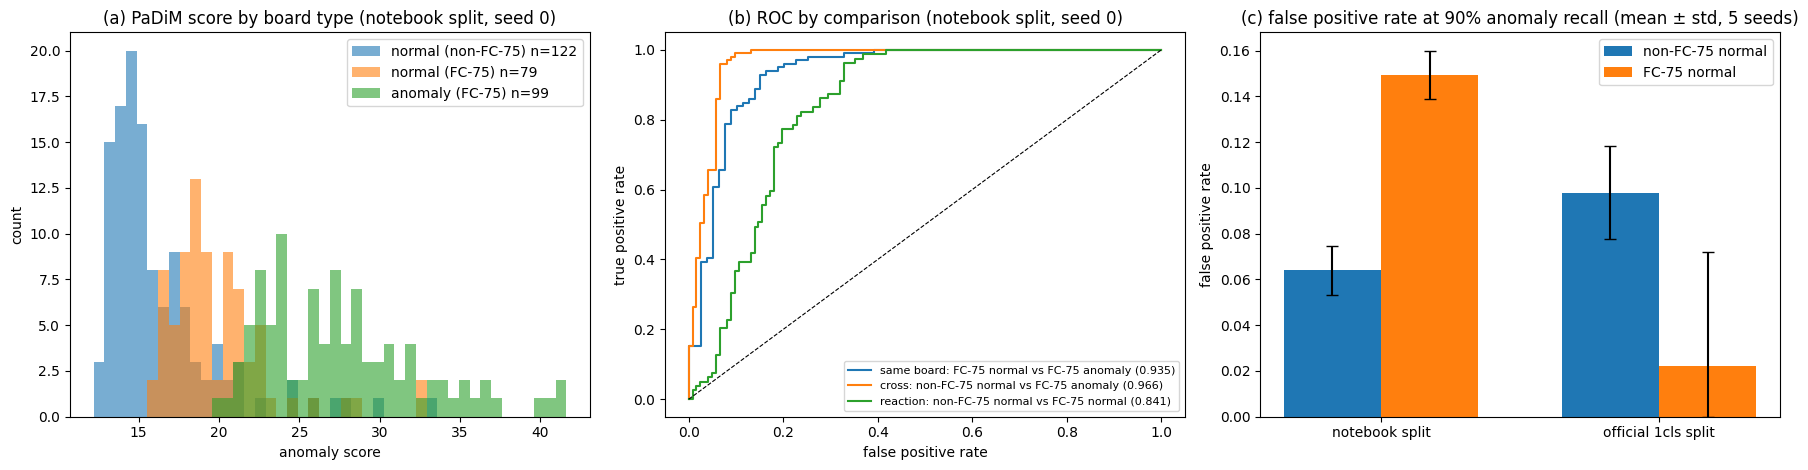

In [ ]:
# @title 그림 1. 기판 종류별 점수 분포, ROC, 오탐률
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
d0, _ = RUNS[('notebook', 0)]
g = groups(d0)
bins = np.linspace(d0.score.min(), d0.score.max(), 45)
for key, label in [('normal_nonfc', 'normal (non-FC-75)'), ('normal_fc', 'normal (FC-75)'), ('anomaly_fc', 'anomaly (FC-75)')]:
    axes[0].hist(g[key], bins=bins, alpha=0.6, label=f'{label} n={len(g[key])}')
axes[0].set(title='(a) PaDiM score by board type (notebook split, seed 0)', xlabel='anomaly score', ylabel='count')
axes[0].legend()
for (neg, pos, label) in [('normal_fc', 'anomaly_fc', 'same board: FC-75 normal vs FC-75 anomaly'),
                          ('normal_nonfc', 'anomaly_fc', 'cross: non-FC-75 normal vs FC-75 anomaly'),
                          ('normal_nonfc', 'normal_fc', 'reaction: non-FC-75 normal vs FC-75 normal')]:
    y = np.r_[np.zeros(len(g[neg])), np.ones(len(g[pos]))]
    fpr, tpr, _ = roc_curve(y, np.r_[g[neg], g[pos]])
    axes[1].plot(fpr, tpr, label=f'{label} ({auroc(g[neg], g[pos]):.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=0.8)
axes[1].set(title='(b) ROC by comparison (notebook split, seed 0)', xlabel='false positive rate', ylabel='true positive rate')
axes[1].legend(fontsize=8, loc='lower right')
x = np.arange(2)
for j, (col, label) in enumerate([('fpr_nonfc75_normal', 'non-FC-75 normal'), ('fpr_fc75_normal', 'FC-75 normal')]):
    m = T1.groupby('split')[col].mean().reindex(['notebook', 'official'])
    s = T1.groupby('split')[col].std().reindex(['notebook', 'official'])
    axes[2].bar(x + (j - 0.5) * 0.35, m.values, 0.35, yerr=[np.minimum(s.values, m.values), s.values], capsize=4, label=label)
axes[2].set_xticks(x, ['notebook split', 'official 1cls split'])
axes[2].set(title='(c) false positive rate at 90% anomaly recall (mean ± std, 5 seeds)', ylabel='false positive rate')
axes[2].legend()
plt.tight_layout()
plt.savefig(f'{RESULT_DIR}/fig1_test1.png', dpi=120)
plt.show()


In [ ]:
# @title Test 1 판정 (실행 전에 정한 기준)
same = T1[T1.split == 'notebook'].same_variant.mean()
react = T1[T1.split == 'notebook'].variant_reaction.mean()
if same >= 0.9:
    verdict = '같은 기판끼리도 결함을 구분한다 → 지름길은 주원인이 아니다'
elif same <= 0.75 and react >= 0.8:
    verdict = '기판 종류 차이에 크게 기댄다'
else:
    verdict = '기준 사이 구간 → 판정 보류'
print(f'노트북 분할: 같은 기판 AUROC {same:.3f}, 기판 반응 AUROC {react:.3f} → {verdict}')
off = T1[T1.split == 'official']
print(f'공식 분할(참고): 같은 기판 AUROC {off.same_variant.mean():.3f}, 기판 반응 AUROC {off.variant_reaction.mean():.3f}')


노트북 분할: 같은 기판 AUROC 0.941, 기판 반응 AUROC 0.856 → 같은 기판끼리도 결함을 구분한다 → 지름길은 주원인이 아니다
공식 분할(참고): 같은 기판 AUROC 0.985, 기판 반응 AUROC 0.737


### Test 1 정리

- 실험 내용: 불량 100장 중 99장이 FC-75 기판인데 학습용 정상에는 FC-75가 거의 없어보여서, PaDiM이 결함이 아니라 기판 종류를 보고 맞힌 건 아닌지 같은 FC-75 기판끼리만 따로 비교해 보았다.
- 결과: 같은 기판끼리도 AUROC 0.941로 결함을 잘 구분했다. 다만 정상끼리도 기판 종류에 반응해서, FC-75 정상의 오탐률이 14.9%로 FC-75 기판이 아닐 때 정상의 2배가 넘었다.
- 분석: 처음에는 불량이 거의 다 FC-75 기판이라 PaDiM이 기판 종류를 보고 맞힌 줄 알았는데, 같은 기판끼리 비교해도 0.94가 나와서 실제로 불량을 탐지하고 있지만, 학습 데이터에 FC-75 정상이 거의 없어서 FC-75 정상 제품을 불량으로 잘못 보는 경우가 많았고, 학습 데이터에 어떤 제품이 얼마나 들어가 있는지도 중요하다고 생각했다.

## Test 2 분석: 결함 영역 검증 (실험 A·B)

Test 1은 이미지 점수만 봤다. Test 2는 28×28 이상 맵으로 **점수가 이미지의 어디에서 나오는지** 확인한다. pcb4 불량 100장에는 결함 위치를 칠한 정답 마스크가 있다.

**실험 A (RQ2): 이미지 점수가 결함 영역에서 나오는가?**
- 방법: 이상 맵에서 결함 마스크 부분을 빼고, 남은 위치의 최댓값으로 AUROC를 다시 구한다.
  - 마스크는 28×28 격자로 줄인 뒤(한 칸이라도 겹치면 포함) r칸 넓힌다. CNN 특징은 주변 픽셀까지 섞기 때문에 결함의 영향이 마스크 밖으로 번진다.
  - 정상 이미지에도 불량 마스크 100개를 하나씩 똑같이 적용해 뺀 값의 평균을 쓴다. 빼는 면적이 달라서 생기는 차이를 없애기 위해서다.
- 주 지표: 노트북 분할, 같은 기판(`FC-75` 정상 vs `FC-75` 불량), r=2. r=0~4는 민감도로 함께 본다.
- 판정 기준 (실행 전 고정): 주 지표 ≤ 0.6 → 점수는 결함 영역에서 나온다 / ≥ 0.8 → 결함 밖에도 불량을 가르는 단서가 있다 / 그 사이 → 부분적이다.

**실험 B (RQ3): 이상 맵이 결함 위치를 가리키는가?**
- 픽셀 AUROC: 이상 맵을 256×256으로 이중선형 업샘플하고 가우시안(σ=4)으로 부드럽게 한 뒤 정답 마스크와 픽셀 단위로 비교한다.
- AUPRO (FPR 0.3까지): 결함 영역 하나하나를 덮은 비율(PRO)을 오탐률 0~30% 구간에서 평균 낸다. 큰 결함 하나가 점수를 독차지하지 않게 하는 지표다.
- 최댓값 적중률: 불량 이미지에서 이상 맵 최댓값(= 이미지 점수를 만든 위치)이 마스크 안(r=0, r=1)에 있는 비율. 무작위로 찍었을 때의 기대값(마스크 면적 비율)과 비교한다.
- 판정 기준 (실행 전 고정): 픽셀 AUROC ≥ 0.9 그리고 적중률(r=1) ≥ 0.7 → 결함 위치를 잘 가리킨다 / 적중률(r=1) < 0.5 → 이미지 점수의 최댓값이 결함 밖에서 자주 나온다.

,분할,결함 영역,같은 기판 AUROC,전체 AUROC,뺀 면적 (불량 이미지 평균)
0,notebook,빼지 않음 (원래 점수),0.941 ± 0.007,0.960 ± 0.005,0.0%
1,notebook,r=0,0.866 ± 0.013,0.913 ± 0.007,3.1%
2,notebook,r=1,0.743 ± 0.028,0.839 ± 0.014,7.5%
3,notebook,r=2,0.654 ± 0.014,0.785 ± 0.008,13.2%
4,notebook,r=3,0.636 ± 0.011,0.764 ± 0.009,19.9%
5,notebook,r=4,0.619 ± 0.013,0.739 ± 0.007,27.6%
6,official,빼지 않음 (원래 점수),0.985 ± 0.008,0.951 ± 0.005,0.0%
7,official,r=0,0.938 ± 0.019,0.911 ± 0.007,3.1%
8,official,r=1,0.815 ± 0.032,0.843 ± 0.009,7.5%
9,official,r=2,0.725 ± 0.024,0.795 ± 0.009,13.2%


주 지표 (노트북 분할, 같은 기판, r=2) seed 0: 0.648, 95% 신뢰구간 [0.564, 0.726]


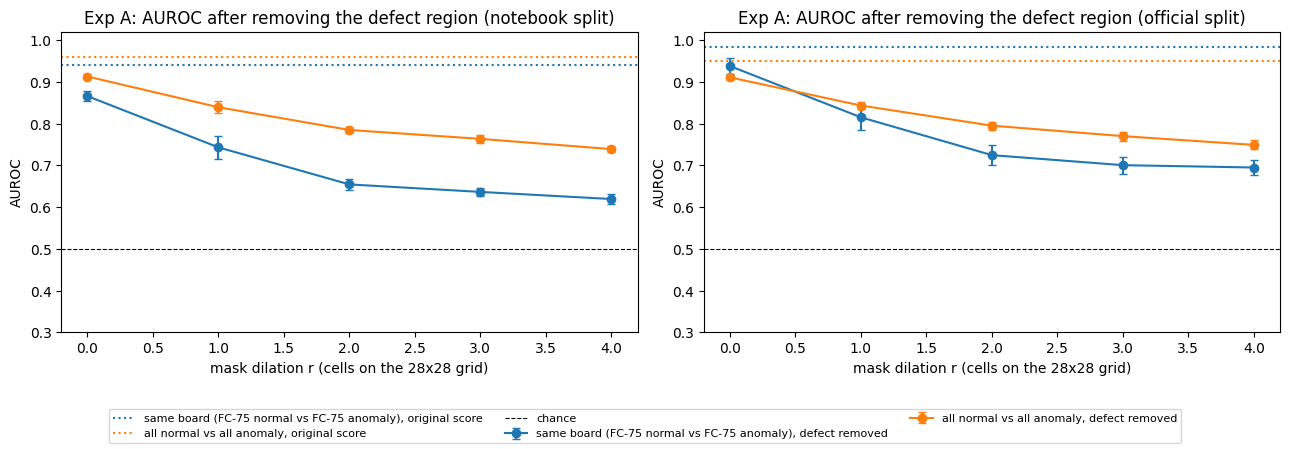

In [ ]:
# @title 표 2·그림 2. 실험 A: 결함 영역을 뺀 AUROC
R_LIST = [0, 1, 2, 3, 4]
rows = []
for (split, seed), (d, maps) in RUNS.items():
    g0 = groups(d)
    rows.append(dict(split=split, seed=seed, r='-', all=auroc(g0['normal'], g0['anomaly']),
                     same=auroc(g0['normal_fc'], g0['anomaly_fc']), excluded=0.0))
    for r in R_LIST:
        s = exp_a_scores(maps, d, MASKS[split], r)
        g = groups(d.assign(masked=s), 'masked')
        excluded = patch_masks(MASKS[split][d.label.values == 1], r).mean()
        rows.append(dict(split=split, seed=seed, r=r, all=auroc(g['normal'], g['anomaly']),
                         same=auroc(g['normal_fc'], g['anomaly_fc']), excluded=excluded))
TA = pd.DataFrame(rows)
TA.to_csv(f'{RESULT_DIR}/exp_a_by_seed.csv', index=False)

def fmt(x):
    return f'{x.mean():.3f} ± {x.std():.3f}'
table2 = TA.groupby(['split', 'r'], sort=False).agg(
    same=('same', fmt), all=('all', fmt), excluded=('excluded', lambda x: f'{x.mean():.1%}')).reset_index()
table2['r'] = table2['r'].map(lambda v: '빼지 않음 (원래 점수)' if v == '-' else f'r={v}')
table2.columns = ['분할', '결함 영역', '같은 기판 AUROC', '전체 AUROC', '뺀 면적 (불량 이미지 평균)']
table2.to_csv(f'{RESULT_DIR}/table2_exp_a.csv', index=False)
display(table2)

d0, maps0 = RUNS[('notebook', 0)]
g = groups(d0.assign(masked=exp_a_scores(maps0, d0, MASKS['notebook'], 2)), 'masked')
lo, hi = boot_ci(g['normal_fc'], g['anomaly_fc'])
print(f"주 지표 (노트북 분할, 같은 기판, r=2) seed 0: {auroc(g['normal_fc'], g['anomaly_fc']):.3f}, 95% 신뢰구간 [{lo:.3f}, {hi:.3f}]")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, split in zip(axes, ['notebook', 'official']):
    sub = TA[(TA.split == split) & (TA.r != '-')].astype({'r': int})
    base = TA[(TA.split == split) & (TA.r == '-')]
    for col, label in [('same', 'same board (FC-75 normal vs FC-75 anomaly)'), ('all', 'all normal vs all anomaly')]:
        m, s = sub.groupby('r')[col].mean(), sub.groupby('r')[col].std()
        line = ax.errorbar(m.index, m.values, yerr=s.values, marker='o', capsize=3, label=f'{label}, defect removed')
        ax.axhline(base[col].mean(), ls=':', color=line[0].get_color(), label=f'{label}, original score')
    ax.axhline(0.5, color='k', lw=0.8, ls='--', label='chance')
    ax.set(title=f'Exp A: AUROC after removing the defect region ({split} split)',
           xlabel='mask dilation r (cells on the 28x28 grid)', ylabel='AUROC', ylim=(0.3, 1.02))
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, fontsize=8)
plt.tight_layout(rect=[0, 0.12, 1, 1])
plt.savefig(f'{RESULT_DIR}/fig2_exp_a.png', dpi=120)
plt.show()


,노트북 분할,공식 1cls 분할
픽셀 AUROC,0.979 ± 0.001,0.975 ± 0.001
AUPRO (FPR ≤ 0.3),0.859 ± 0.005,0.832 ± 0.005
최댓값 적중률 (마스크 r=0),0.794 ± 0.023,0.778 ± 0.031
무작위 기대값 (r=0),0.031 ± 0.000,0.031 ± 0.000
최댓값 적중률 (마스크 r=1),0.848 ± 0.022,0.832 ± 0.028
무작위 기대값 (r=1),0.075 ± 0.000,0.075 ± 0.000


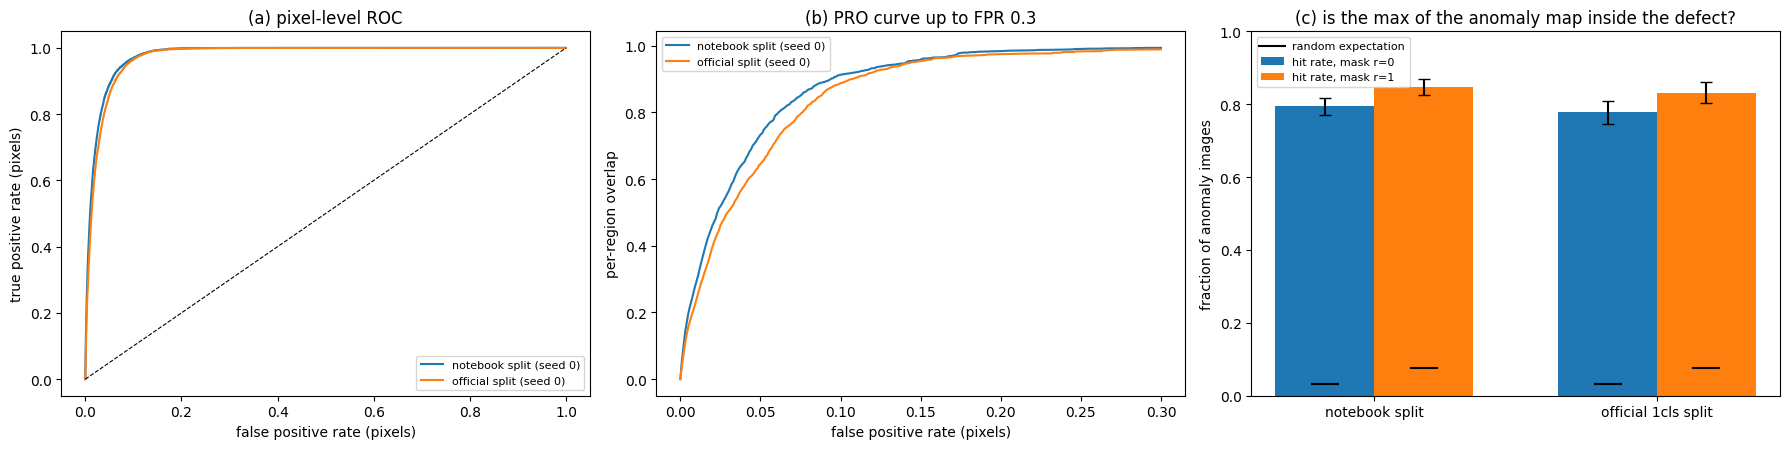

In [ ]:
# @title 표 3·그림 3. 실험 B: 이상 맵이 결함 위치를 가리키는가
rows, curves = [], {}
for (split, seed), (d, maps) in RUNS.items():
    gt = MASKS[split]
    score = upsample_smooth(maps)
    is_anom = d.label.values == 1
    pro_area, fpr_curve, pro_curve = aupro(score, gt)
    h0, c0 = pointing(maps[is_anom], gt[is_anom], 0)
    h1, c1 = pointing(maps[is_anom], gt[is_anom], 1)
    rows.append(dict(split=split, seed=seed, pixel_auroc=roc_auc_score(gt.ravel(), score.ravel()), aupro=pro_area,
                     hit_r0=h0, chance_r0=c0, hit_r1=h1, chance_r1=c1))
    if seed == 0:
        curves[split] = (gt, score, fpr_curve, pro_curve)
TB = pd.DataFrame(rows)
TB.to_csv(f'{RESULT_DIR}/exp_b_by_seed.csv', index=False)
TB_NAMES = {'pixel_auroc': '픽셀 AUROC', 'aupro': 'AUPRO (FPR ≤ 0.3)',
            'hit_r0': '최댓값 적중률 (마스크 r=0)', 'chance_r0': '무작위 기대값 (r=0)',
            'hit_r1': '최댓값 적중률 (마스크 r=1)', 'chance_r1': '무작위 기대값 (r=1)'}
table3 = mean_std_table(TB, list(TB_NAMES), TB_NAMES)
table3.columns = ['노트북 분할' if c == 'notebook' else '공식 1cls 분할' for c in table3.columns]
table3.to_csv(f'{RESULT_DIR}/table3_exp_b.csv')
display(table3)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
for split, color in [('notebook', 'C0'), ('official', 'C1')]:
    gt, score, fpr_curve, pro_curve = curves[split]
    rng = np.random.default_rng(0)
    pick = rng.choice(gt.size, size=min(gt.size, 2_000_000), replace=False)  # 그림용 표본 (지표는 전체 픽셀로 계산)
    fpr, tpr, _ = roc_curve(gt.ravel()[pick], score.ravel()[pick])
    axes[0].plot(fpr, tpr, color=color, label=f'{split} split (seed 0)')
    axes[1].plot(fpr_curve, pro_curve, color=color, label=f'{split} split (seed 0)')
axes[0].plot([0, 1], [0, 1], 'k--', lw=0.8)
axes[0].set(title='(a) pixel-level ROC', xlabel='false positive rate (pixels)', ylabel='true positive rate (pixels)')
axes[1].set(title='(b) PRO curve up to FPR 0.3', xlabel='false positive rate (pixels)', ylabel='per-region overlap')
x = np.arange(2)
for j, (col, chance, label) in enumerate([('hit_r0', 'chance_r0', 'mask r=0'), ('hit_r1', 'chance_r1', 'mask r=1')]):
    m = TB.groupby('split')[col].mean().reindex(['notebook', 'official'])
    s = TB.groupby('split')[col].std().reindex(['notebook', 'official'])
    c = TB.groupby('split')[chance].mean().reindex(['notebook', 'official'])
    axes[2].bar(x + (j - 0.5) * 0.35, m.values, 0.35, yerr=[np.minimum(s.values, m.values), np.minimum(s.values, 1 - m.values)],
                capsize=4, label=f'hit rate, {label}')
    axes[2].scatter(x + (j - 0.5) * 0.35, c.values, color='k', marker='_', s=400, zorder=3,
                    label='random expectation' if j == 0 else None)
axes[2].set_xticks(x, ['notebook split', 'official 1cls split'])
axes[2].set(title='(c) is the max of the anomaly map inside the defect?', ylabel='fraction of anomaly images', ylim=(0, 1))
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f'{RESULT_DIR}/fig3_exp_b.png', dpi=120)
plt.show()


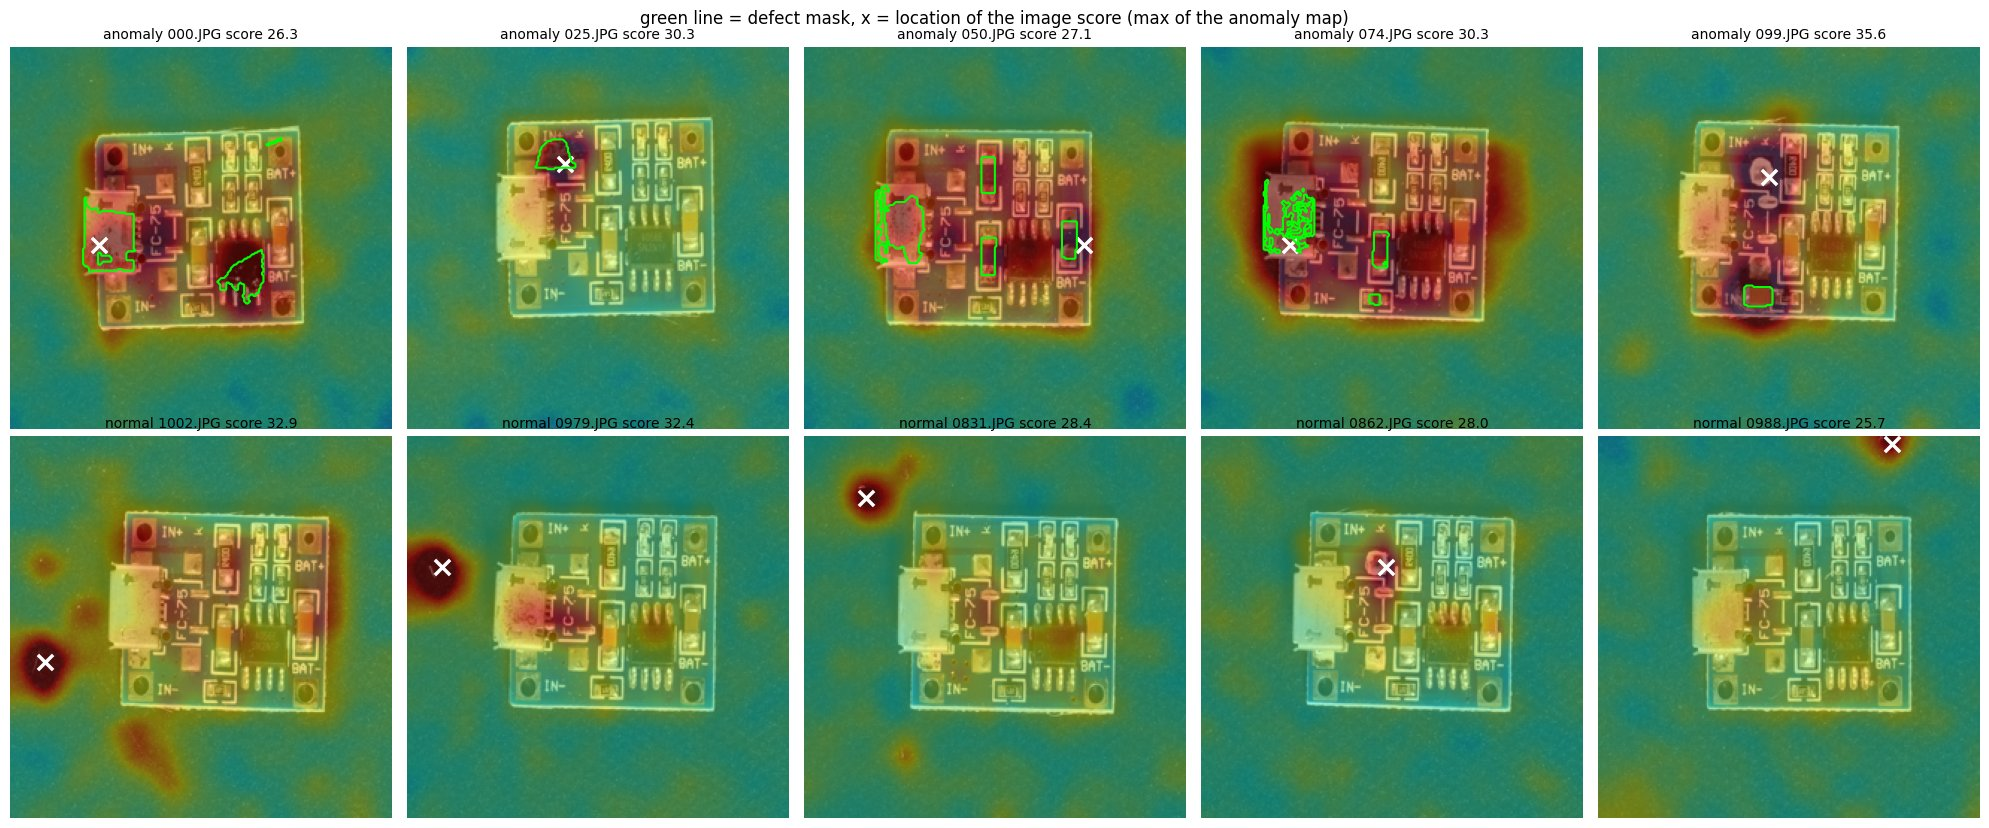

In [ ]:
# @title 그림 4. 이상 맵 예시 (노트북 분할, seed 0): 위 = FC-75 불량, 아래 = 점수가 가장 높은 FC-75 정상
d0, maps0 = RUNS[('notebook', 0)]
up0 = upsample_smooth(maps0)
gt0 = MASKS['notebook']
anom_idx = d0.index[(d0.label == 1) & d0.fc75].tolist()
anom_pick = [anom_idx[i] for i in np.linspace(0, len(anom_idx) - 1, 5).astype(int)]
norm_pick = d0[(d0.label == 0) & d0.fc75].sort_values('score', ascending=False).index[:5].tolist()
fig, axes = plt.subplots(2, 5, figsize=(20, 8.4))
vmax = np.percentile(up0, 99.5)
for ax, i in zip(axes.ravel(), anom_pick + norm_pick):
    img = np.array(Image.open(Path(TEST_DATA_PATH) / d0.image[i]).convert('RGB').resize((256, 256)))
    ax.imshow(img)
    ax.imshow(up0[i], cmap='jet', alpha=0.45, vmin=0, vmax=vmax)
    if gt0[i].any():
        ax.contour(gt0[i].astype(float), levels=[0.5], colors='lime', linewidths=1.5)
    py, px = np.unravel_index(maps0[i].argmax(), maps0[i].shape)
    ax.scatter((px + 0.5) * 256 / GRID, (py + 0.5) * 256 / GRID, marker='x', s=120, c='white', linewidths=2.5)
    kind = 'anomaly' if d0.label[i] == 1 else 'normal'
    ax.set_title(f"{kind} {Path(d0.image[i]).name} score {d0.score[i]:.1f}", fontsize=10)
    ax.axis('off')
plt.suptitle('green line = defect mask, x = location of the image score (max of the anomaly map)')
plt.tight_layout()
plt.savefig(f'{RESULT_DIR}/fig4_maps.png', dpi=110)
plt.show()


In [ ]:
# @title Test 2 판정 (실행 전에 정한 기준)
a = TA[(TA.split == 'notebook') & (TA.r == 2)].same.mean()
if a <= 0.6:
    va = '이미지 점수는 결함 영역에서 나온다'
elif a >= 0.8:
    va = '결함 영역 밖에도 불량을 가르는 단서가 있다'
else:
    va = '부분적이다 (결함 영역 밖에도 일부 단서가 있다)'
print(f'실험 A 주 지표 (노트북 분할, 같은 기판, r=2): {a:.3f} → {va}')
nb = TB[TB.split == 'notebook']
px, hit1 = nb.pixel_auroc.mean(), nb.hit_r1.mean()
if px >= 0.9 and hit1 >= 0.7:
    vb = '이상 맵이 결함 위치를 잘 가리킨다'
elif hit1 < 0.5:
    vb = '이미지 점수의 최댓값이 결함 밖에서 자주 나온다'
else:
    vb = '기준 사이 구간 → 판정 보류'
print(f'실험 B (노트북 분할): 픽셀 AUROC {px:.3f}, 최댓값 적중률(r=1) {hit1:.3f} → {vb}')


실험 A 주 지표 (노트북 분할, 같은 기판, r=2): 0.654 → 부분적이다 (결함 영역 밖에도 일부 단서가 있다)
실험 B (노트북 분할): 픽셀 AUROC 0.979, 최댓값 적중률(r=1) 0.848 → 이상 맵이 결함 위치를 잘 가리킨다


### Test 2 정리

- 실험 내용: 점수가 정말 결함에서 나오는지 보려고, 이상 맵에서 결함 영역을 지우고 다시 평가하고, 이상 맵이 결함 위치를 가리키는지 확인해 보았다.
- 결과: 결함과 주변 2칸을 지우니 같은 기판 AUROC가 0.941에서 0.654로 떨어졌다. 이상 맵은 픽셀 AUROC 0.979로 결함 위치를 잘 가리켰고, 가장 이상한 위치의 85%가 결함 근처였다.
- 분석: 결함 부분을 지우니 점수가 크게 떨어지고 이상 맵도 결함 위치를 잘 가리켜서, PaDiM이 실제로 결함을 보는구나를 알 수 있었다.

## Test 3 분석: AutoEncoder 학습 과정 검증

위 비교에서 AutoEncoder의 AUROC는 0.27 정도로 무작위(0.5)보다도 낮았다. 정상과 불량을 거꾸로 판단한다는 뜻이다. 학습 기록을 보면 손실도 빠르게 떨어진 뒤 1.65 근처에서 거의 줄지 않는다.

**가설**: 입력은 ImageNet 정규화를 거쳐 대략 −2.1~+2.6 범위인데, 디코더 마지막 층이 Sigmoid라 출력은 0~1밖에 못 낸다. 그래서 정상 이미지도 제대로 복원할 수 없고, 복원 오차가 결함보다 밝기·색 분포를 재게 된다.

**질문**
- RQ3-1: 원본 학습이 이론적으로 정상인가? 손실이 멈춘 이유가 출력 범위 때문인가?
- RQ3-2: 입력과 출력의 범위를 맞추면 AUROC가 회복되는가?
- RQ3-3: epoch를 늘리면 어디서부터 overfitting이 생기는가?

**실험 조건**

| 조건 | 입력 | 출력층 | 바꾼 것 |
|---|---|---|---|
| 원본 | ImageNet 정규화 (−2.1~+2.6) | Sigmoid (0~1) | 없음 |
| 수정 1 | ImageNet 정규화 | 없음 (선형) | 마지막 Sigmoid만 제거 |
| 수정 2 | 정규화 없음 (0~1) | Sigmoid (0~1) | 입력 정규화만 제거 |

- 모델과 학습 설정은 원본 그대로다: 위 `ConvAutoEncoder`, Adam(lr 0.001), MSE 손실, batch 16, 학습 때 좌우 반전.
- 노트북 분할의 학습용 정상 804장 중 무작위 80장(10%, 고정)을 검증용으로 떼고 724장으로 학습한다. 검증 손실로 overfitting을 본다.
- epoch는 100(원본 50의 두 배), 시드는 0~2. epoch마다 학습 손실, 검증 손실, 테스트 AUROC를 기록한다. 테스트 AUROC는 관찰용이고 epoch 선택에 쓰지 않는다.
- 이상 점수는 원본처럼 이미지 전체의 평균 복원 오차다. 보조로 오차 상위 1% 픽셀의 평균도 계산해, 작은 결함이 평균에 묻히는지 본다.
- 속도를 위해 256×256으로 줄인 이미지를 메모리에 두고 정규화·반전은 GPU에서 한다. 입력 값은 원본 전처리와 같다.

**판정 기준 (실행 전 고정)**
- RQ3-1: 원본 조건의 100 epoch 학습 손실이 "출력이 0~1이라 어떤 모델도 내려갈 수 없는 최소 손실"의 1.1배 이내면 → 손실이 멈춘 원인은 출력 범위 불일치다.
- RQ3-2: 수정 1 또는 수정 2의 100 epoch AUROC(평균 오차 점수, 시드 평균) ≥ 0.6 → 범위 불일치가 AUROC 0.27의 주원인이다 / 둘 다 < 0.5 → 범위 불일치만으로는 설명되지 않는다 / 그 사이 → 부분적이다.
- RQ3-3: 검증 손실이 최저점보다 5% 이상 다시 오르면 overfitting으로 보고, 최저점 epoch를 overfitting 시작점으로 본다.

In [ ]:
# @title Test 3 도구: 이미지 캐시, 조건별 AutoEncoder, epoch별 기록
import time
T3_EPOCHS, T3_SEEDS, T3_BATCH = 100, [0, 1, 2], 16
T3_CONDITIONS = {'original': dict(normalize=True, sigmoid=True),
                 'fix1_no_sigmoid': dict(normalize=True, sigmoid=False),
                 'fix2_no_normalize': dict(normalize=False, sigmoid=True)}
T3_NAMES = {'original': '원본 (정규화 입력 + Sigmoid)', 'fix1_no_sigmoid': '수정 1 (Sigmoid 제거)',
            'fix2_no_normalize': '수정 2 (입력 정규화 제거)'}
T3_NAMES_EN = {'original': 'original', 'fix1_no_sigmoid': 'fix 1 (no Sigmoid)', 'fix2_no_normalize': 'fix 2 (no normalization)'}
IMNET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
IMNET_STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
_resize = transforms.Resize((256, 256))


def load_uint8(paths):
    """원본 전처리의 Resize((256, 256)) 결과를 uint8로 보관한다 (ToTensor는 /255만 하므로 값이 같다)"""
    return torch.stack([torch.from_numpy(np.array(_resize(Image.open(p).convert('RGB')))).permute(2, 0, 1) for p in paths])


def prep(x_uint8, normalize, flip=False):
    x = x_uint8.float() / 255.0
    if flip:  # 원본 학습 전처리의 RandomHorizontalFlip(p=0.5)
        m = torch.rand(x.size(0), device=x.device) < 0.5
        x[m] = x[m].flip(-1)
    return (x - IMNET_MEAN) / IMNET_STD if normalize else x


def make_ae(sigmoid):
    model = ConvAutoEncoder(input_channels=3, latent_dim=128).to(device)  # 원본 클래스 그대로
    if not sigmoid:
        model.decoder[-1] = nn.Identity()  # 마지막 Sigmoid만 제거
    return model


@torch.no_grad()
def recon_errors(model, X, normalize, bs=32):
    """이미지별 평균 복원 오차(원본 predict와 같은 계산)와 오차 상위 1% 픽셀의 평균"""
    model.eval()
    mean_s, top_s = [], []
    for i in range(0, len(X), bs):
        x = prep(X[i:i + bs], normalize)
        err = ((model(x) - x) ** 2).mean(1).flatten(1)  # 픽셀별 오차 (채널 평균)
        mean_s.append(err.mean(1).cpu())
        top_s.append(err.topk(max(1, int(err.size(1) * 0.01)), dim=1).values.mean(1).cpu())
    return torch.cat(mean_s).numpy(), torch.cat(top_s).numpy()


@torch.no_grad()
def range_floor(X):
    """출력이 0~1로 묶여 있을 때, 정규화된 입력에 대해 어떤 모델도 내려갈 수 없는 최소 MSE"""
    tot, n = 0.0, 0
    for i in range(0, len(X), 64):
        x = prep(X[i:i + 64], True)
        tot += ((x - x.clamp(0, 1)) ** 2).sum().item()
        n += x.numel()
    return tot / n


def train_ae(cond, seed):
    """원본 설정(Adam lr 0.001, MSE, batch 16, 좌우 반전)으로 학습하며 epoch마다 손실과 AUROC를 기록"""
    set_seed(seed)
    c = T3_CONDITIONS[cond]
    model = make_ae(c['sigmoid'])
    opt = torch.optim.Adam(model.parameters(), lr=0.001)
    crit = nn.MSELoss()
    hist = []
    for epoch in range(1, T3_EPOCHS + 1):
        model.train()
        order = torch.randperm(len(X_TR), device=device)
        losses = []
        for i in range(0, len(order), T3_BATCH):
            idx = order[i:i + T3_BATCH]
            if len(idx) < 2:  # BatchNorm은 1장짜리 배치로 학습할 수 없다
                continue
            x = prep(X_TR[idx], c['normalize'], flip=True)
            opt.zero_grad()
            loss = crit(model(x), x)
            loss.backward()
            opt.step()
            losses.append(loss.item())
        val = float(recon_errors(model, X_VAL, c['normalize'])[0].mean())
        s_mean, s_top = recon_errors(model, X_TEST, c['normalize'])
        hist.append(dict(cond=cond, seed=seed, epoch=epoch, train_loss=float(np.mean(losses)), val_loss=val,
                         auroc_mean=roc_auc_score(Y_TEST, s_mean), auroc_top1=roc_auc_score(Y_TEST, s_top)))
    return model, pd.DataFrame(hist), s_mean, s_top


nb_train_ds, nb_test_ds = SPLITS['notebook'][0].dataset, SPLITS['notebook'][1].dataset
X_ALL = load_uint8(nb_train_ds.image_paths).to(device)   # 노트북 분할 학습용 정상
X_TEST = load_uint8(nb_test_ds.image_paths).to(device)   # 테스트 (정상 + 불량), Test 1·2와 같은 순서
Y_TEST = np.array(nb_test_ds.labels)
_perm = torch.randperm(len(X_ALL), generator=torch.Generator().manual_seed(0)).to(device)
_n_val = int(round(len(X_ALL) * 0.1))
X_VAL, X_TR = X_ALL[_perm[:_n_val]], X_ALL[_perm[_n_val:]]
del X_ALL
FLOOR = range_floor(X_TR)
_x = prep(X_TR[:64], True)
print(f'학습 {len(X_TR)}장, 검증 {len(X_VAL)}장, 테스트 {len(X_TEST)}장 (불량 {int(Y_TEST.sum())})')
print(f'정규화 입력 값 범위: {_x.min().item():.2f} ~ {_x.max().item():.2f}, 0~1 밖 비율 {((_x < 0) | (_x > 1)).float().mean().item():.1%} (학습 이미지 64장)')
print(f'원본 조건에서 도달할 수 없는 최소 손실 (출력 0~1 제한): {FLOOR:.4f}')


학습 724장, 검증 80장, 테스트 301장 (불량 100)
정규화 입력 값 범위: -2.12 ~ 2.64, 0~1 밖 비율 90.6% (학습 이미지 64장)
원본 조건에서 도달할 수 없는 최소 손실 (출력 0~1 제한): 1.6323


In [ ]:
# @title Test 3 실행: 조건 3개 × 시드 3개 × 100 epoch
T3_HIST, T3_MODELS, T3_SCORES = [], {}, {}
for cond in T3_CONDITIONS:
    for seed in T3_SEEDS:
        t = time.time()
        model, hist, s_mean, s_top = train_ae(cond, seed)
        T3_HIST.append(hist)
        T3_SCORES[(cond, seed)] = (s_mean, s_top)
        if seed == T3_SEEDS[0]:
            T3_MODELS[cond] = model
        last = hist.iloc[-1]
        print(f'{T3_NAMES[cond]} seed {seed}: 학습 손실 {last.train_loss:.4f}, 검증 손실 {last.val_loss:.4f}, '
              f'AUROC(평균 오차) {last.auroc_mean:.3f}, AUROC(상위 1%) {last.auroc_top1:.3f} ({time.time() - t:.0f}초)')
T3_HIST = pd.concat(T3_HIST, ignore_index=True)
T3_HIST.to_csv(f'{RESULT_DIR}/test3_history.csv', index=False)


원본 (정규화 입력 + Sigmoid) seed 0: 학습 손실 1.6365, 검증 손실 1.6635, AUROC(평균 오차) 0.266, AUROC(상위 1%) 0.236 (290초)


원본 (정규화 입력 + Sigmoid) seed 1: 학습 손실 1.6342, 검증 손실 1.6644, AUROC(평균 오차) 0.269, AUROC(상위 1%) 0.251 (289초)


원본 (정규화 입력 + Sigmoid) seed 2: 학습 손실 1.6396, 검증 손실 1.6634, AUROC(평균 오차) 0.266, AUROC(상위 1%) 0.240 (289초)


수정 1 (Sigmoid 제거) seed 0: 학습 손실 0.0249, 검증 손실 0.0308, AUROC(평균 오차) 0.939, AUROC(상위 1%) 0.935 (287초)


수정 1 (Sigmoid 제거) seed 1: 학습 손실 0.0238, 검증 손실 0.0349, AUROC(평균 오차) 0.902, AUROC(상위 1%) 0.918 (287초)


수정 1 (Sigmoid 제거) seed 2: 학습 손실 0.0234, 검증 손실 0.0284, AUROC(평균 오차) 0.930, AUROC(상위 1%) 0.931 (288초)


수정 2 (입력 정규화 제거) seed 0: 학습 손실 0.0013, 검증 손실 0.0015, AUROC(평균 오차) 0.931, AUROC(상위 1%) 0.927 (287초)


수정 2 (입력 정규화 제거) seed 1: 학습 손실 0.0013, 검증 손실 0.0019, AUROC(평균 오차) 0.934, AUROC(상위 1%) 0.934 (289초)


수정 2 (입력 정규화 제거) seed 2: 학습 손실 0.0011, 검증 손실 0.0014, AUROC(평균 오차) 0.923, AUROC(상위 1%) 0.927 (288초)


In [ ]:
# @title 표 4. Test 3 결과 (시드 3개 평균 ± 표준편차)
E_LAST, E_MID = T3_EPOCHS, min(50, T3_EPOCHS)
rows = []
for (cond, seed), g in T3_HIST.groupby(['cond', 'seed'], sort=False):
    g = g.set_index('epoch')
    rows.append(dict(cond=cond, seed=seed,
                     train_mid=g.train_loss[E_MID], train_last=g.train_loss[E_LAST],
                     val_min=g.val_loss.min(), val_min_epoch=float(g.val_loss.idxmin()), val_last=g.val_loss[E_LAST],
                     val_rise=g.val_loss[E_LAST] / g.val_loss.min() - 1,
                     auroc_mid=g.auroc_mean[E_MID], auroc_last=g.auroc_mean[E_LAST], auroc_top_last=g.auroc_top1[E_LAST],
                     auroc_best=g.auroc_mean.max(), auroc_best_epoch=float(g.auroc_mean.idxmax())))
T3 = pd.DataFrame(rows)
T3.to_csv(f'{RESULT_DIR}/test3_by_seed.csv', index=False)
T3_COLS = {'train_mid': f'학습 손실 ({E_MID} epoch, 원본 설정)', 'train_last': f'학습 손실 ({E_LAST} epoch)',
           'val_min': '검증 손실 최저값', 'val_min_epoch': '검증 손실 최저 epoch', 'val_last': f'검증 손실 ({E_LAST} epoch)',
           'val_rise': '최저점 대비 검증 손실 상승률', 'auroc_mid': f'AUROC ({E_MID} epoch, 평균 오차)',
           'auroc_last': f'AUROC ({E_LAST} epoch, 평균 오차)', 'auroc_top_last': f'AUROC ({E_LAST} epoch, 오차 상위 1%)',
           'auroc_best': 'AUROC 최고값 (평균 오차, 관찰용)', 'auroc_best_epoch': 'AUROC 최고 epoch'}
table4 = mean_std_table(T3, list(T3_COLS), T3_COLS, by='cond', digits=4)[list(T3_CONDITIONS)]
_g = T3.groupby('cond')
for key, fmt in [('val_min_epoch', '{:.0f} ± {:.0f}'), ('auroc_best_epoch', '{:.0f} ± {:.0f}'), ('val_rise', '{:+.1%} ± {:.1%}')]:
    table4.loc[T3_COLS[key]] = pd.Series({c: fmt.format(_g[key].mean()[c], _g[key].std()[c]) for c in T3_CONDITIONS})
table4.loc['도달할 수 없는 최소 손실 (출력 0~1 제한)'] = pd.Series({'original': f'{FLOOR:.4f}', 'fix1_no_sigmoid': '-', 'fix2_no_normalize': '-'})
table4.columns = [T3_NAMES[c] for c in table4.columns]
table4.to_csv(f'{RESULT_DIR}/table4_test3.csv')
print('손실은 조건마다 입력 범위가 달라 조건끼리 크기를 직접 비교하지 않는다 (원본·수정 1: 정규화 공간, 수정 2: 0~1 공간).')
display(table4)


손실은 조건마다 입력 범위가 달라 조건끼리 크기를 직접 비교하지 않는다 (원본·수정 1: 정규화 공간, 수정 2: 0~1 공간).


,원본 (정규화 입력 + Sigmoid),수정 1 (Sigmoid 제거),수정 2 (입력 정규화 제거)
"학습 손실 (50 epoch, 원본 설정)",1.6422 ± 0.0015,0.0310 ± 0.0010,0.0016 ± 0.0002
학습 손실 (100 epoch),1.6368 ± 0.0027,0.0240 ± 0.0008,0.0012 ± 0.0001
검증 손실 최저값,1.6636 ± 0.0003,0.0286 ± 0.0009,0.0015 ± 0.0001
검증 손실 최저 epoch,99 ± 1,99 ± 1,99 ± 1
검증 손실 (100 epoch),1.6638 ± 0.0006,0.0314 ± 0.0033,0.0016 ± 0.0002
최저점 대비 검증 손실 상승률,+0.0% ± 0.0%,+10.1% ± 13.9%,+8.3% ± 13.3%
"AUROC (50 epoch, 평균 오차)",0.2657 ± 0.0007,0.9205 ± 0.0122,0.9244 ± 0.0102
"AUROC (100 epoch, 평균 오차)",0.2672 ± 0.0019,0.9238 ± 0.0190,0.9294 ± 0.0060
"AUROC (100 epoch, 오차 상위 1%)",0.2422 ± 0.0081,0.9278 ± 0.0091,0.9292 ± 0.0037
"AUROC 최고값 (평균 오차, 관찰용)",0.2675 ± 0.0016,0.9410 ± 0.0071,0.9362 ± 0.0050


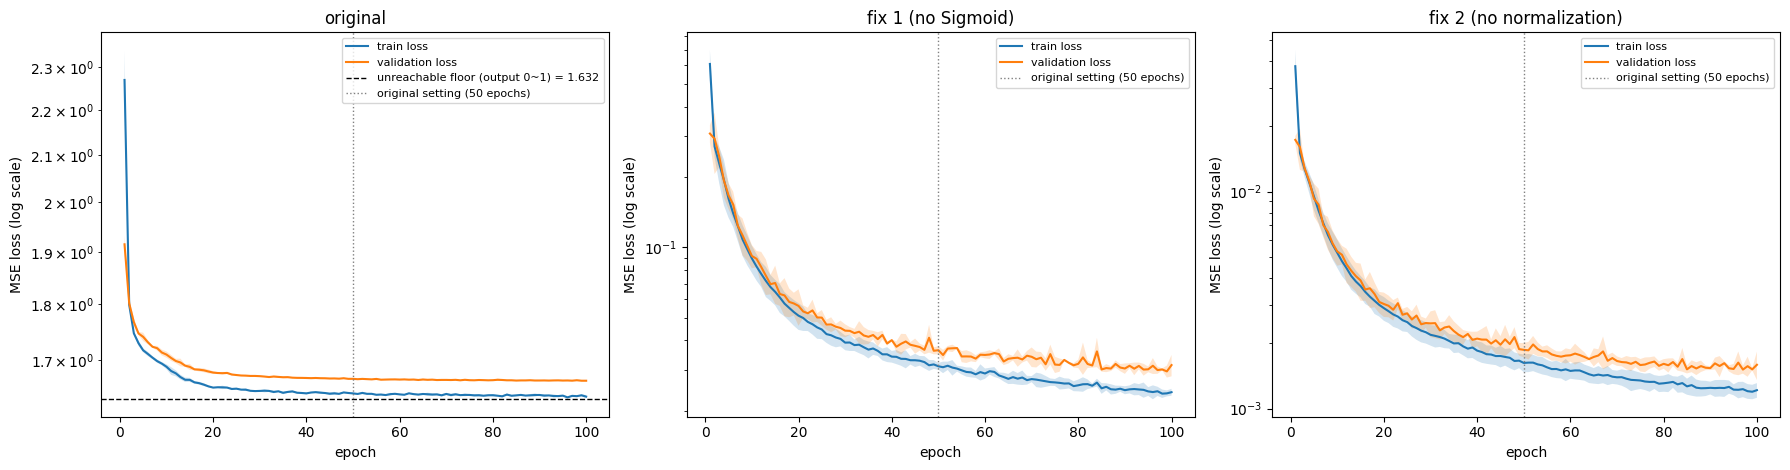

In [ ]:
# @title 그림 5. epoch별 학습·검증 손실 (시드 평균 ± 표준편차, 로그 축)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, cond in zip(axes, T3_CONDITIONS):
    h = T3_HIST[T3_HIST.cond == cond].groupby('epoch')
    for col, label in [('train_loss', 'train loss'), ('val_loss', 'validation loss')]:
        m, s = h[col].mean(), h[col].std().fillna(0)
        ax.plot(m.index, m.values, label=label)
        ax.fill_between(m.index, (m - s).values, (m + s).values, alpha=0.2)
    if cond == 'original':
        ax.axhline(FLOOR, color='k', ls='--', lw=1, label=f'unreachable floor (output 0~1) = {FLOOR:.3f}')
    ax.axvline(min(50, T3_EPOCHS), color='gray', ls=':', lw=1, label='original setting (50 epochs)')
    ax.set_yscale('log')
    ax.set(title=T3_NAMES_EN[cond], xlabel='epoch', ylabel='MSE loss (log scale)')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f'{RESULT_DIR}/fig5_test3_loss.png', dpi=120)
plt.show()


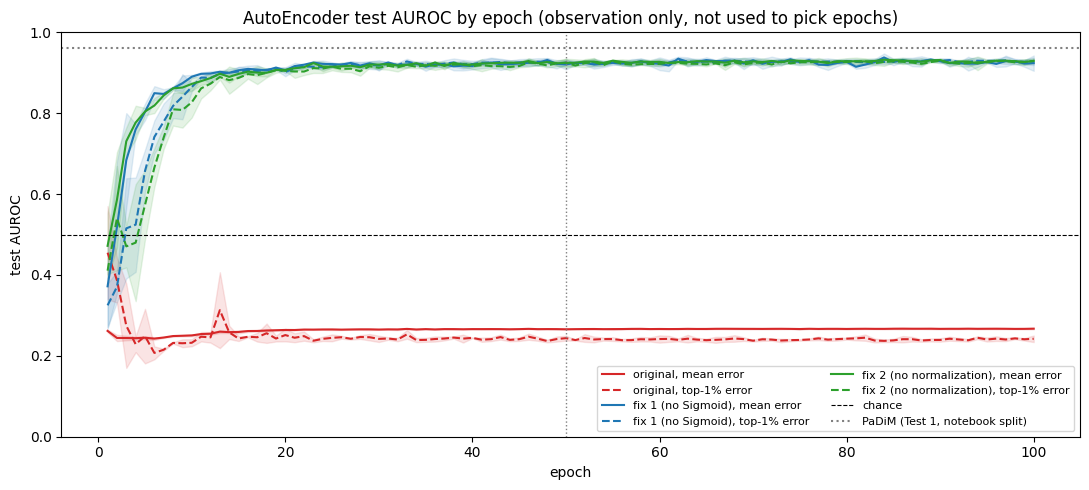

In [ ]:
# @title 그림 6. epoch별 테스트 AUROC (관찰용, 시드 평균 ± 표준편차)
fig, ax = plt.subplots(figsize=(11, 5))
colors = {'original': 'C3', 'fix1_no_sigmoid': 'C0', 'fix2_no_normalize': 'C2'}
for cond in T3_CONDITIONS:
    h = T3_HIST[T3_HIST.cond == cond].groupby('epoch')
    for col, ls, label in [('auroc_mean', '-', 'mean error'), ('auroc_top1', '--', 'top-1% error')]:
        m, s = h[col].mean(), h[col].std().fillna(0)
        ax.plot(m.index, m.values, ls=ls, color=colors[cond], label=f'{T3_NAMES_EN[cond]}, {label}')
        ax.fill_between(m.index, (m - s).values, (m + s).values, color=colors[cond], alpha=0.12)
ax.axhline(0.5, color='k', ls='--', lw=0.8, label='chance')
ax.axhline(T1[T1.split == 'notebook'].auroc_all.mean(), color='gray', ls=':', label='PaDiM (Test 1, notebook split)')
ax.axvline(min(50, T3_EPOCHS), color='gray', ls=':', lw=1)
ax.set(xlabel='epoch', ylabel='test AUROC', ylim=(0, 1), title='AutoEncoder test AUROC by epoch (observation only, not used to pick epochs)')
ax.legend(fontsize=8, loc='lower right', ncol=2)
plt.tight_layout()
plt.savefig(f'{RESULT_DIR}/fig6_test3_auroc.png', dpi=120)
plt.show()


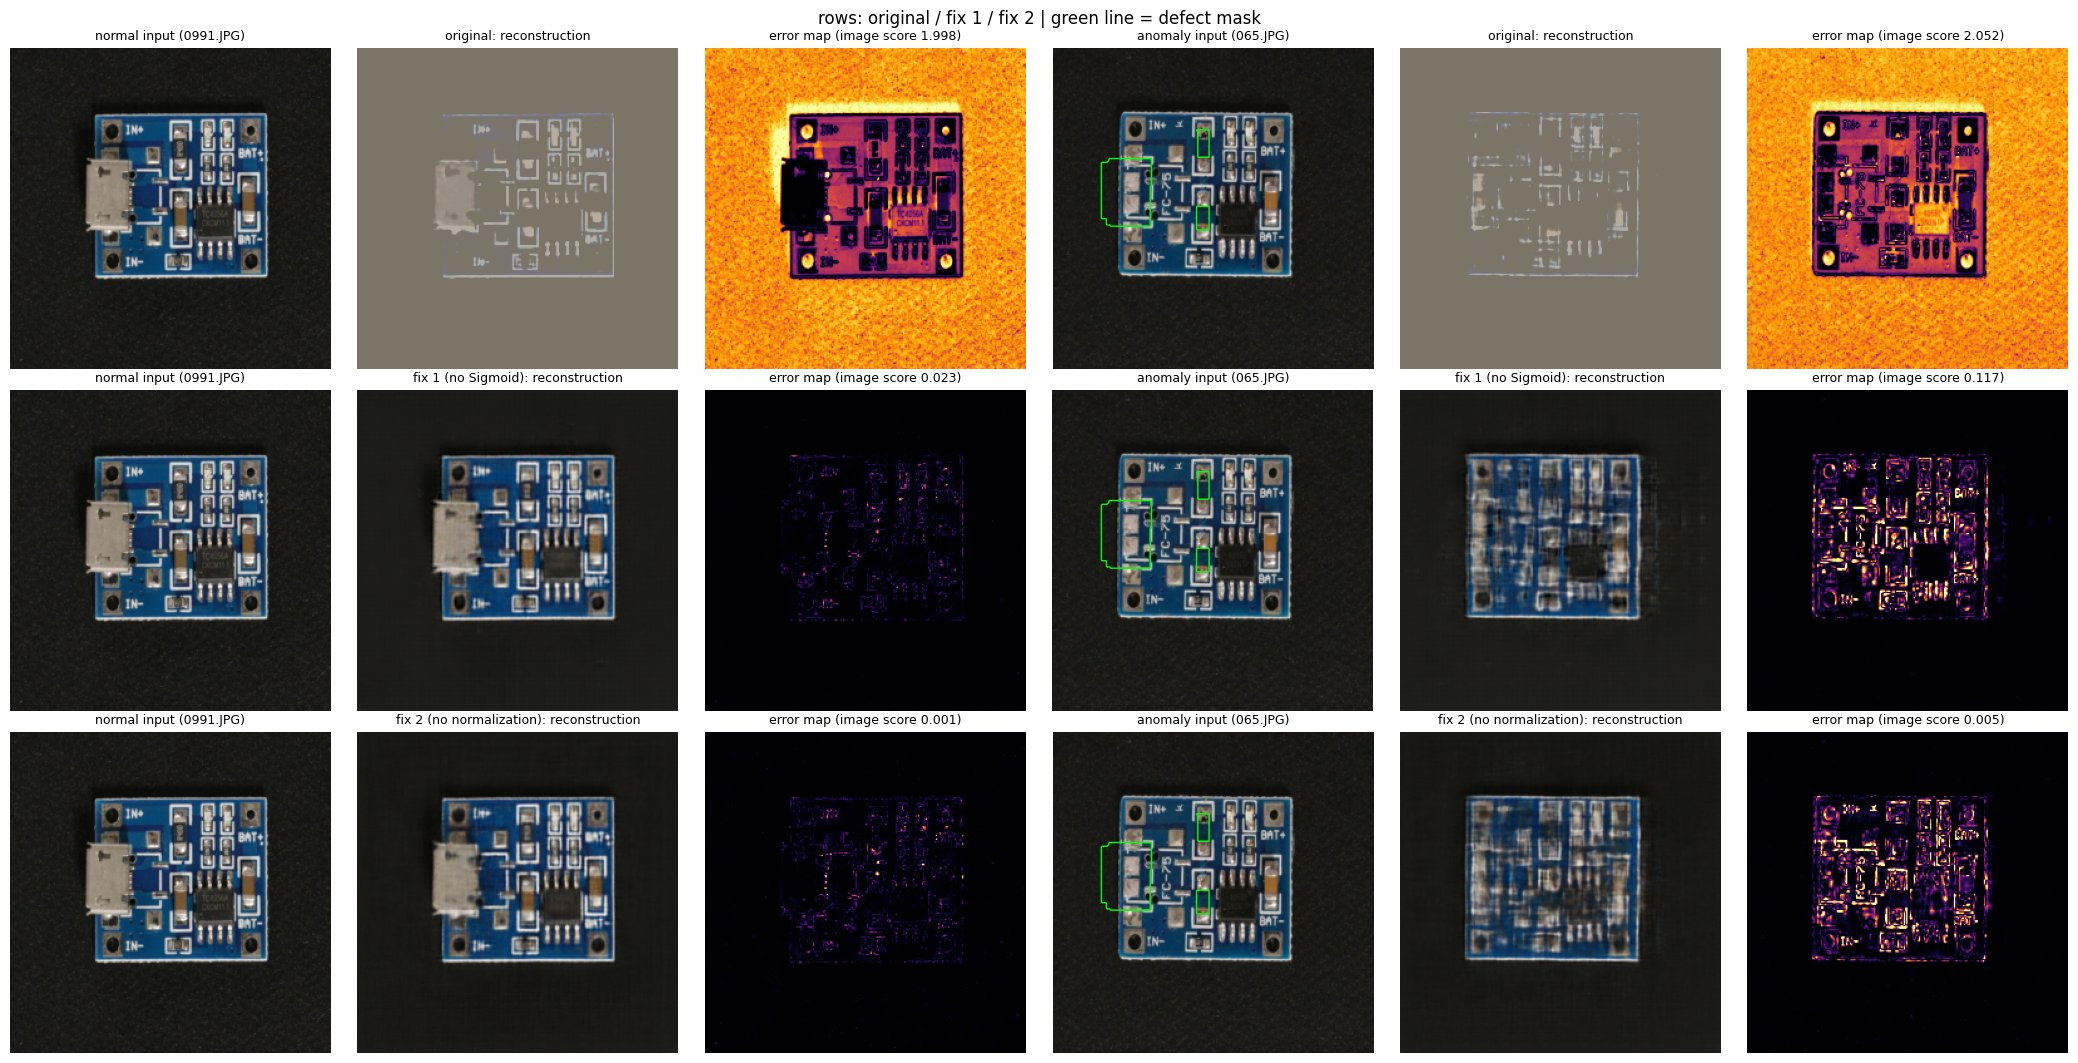

In [ ]:
# @title 그림 7. 복원 예시 (seed 0, 마지막 epoch): 입력, 복원, 오차 맵
def to_rgb(x, normalize):
    x = x * IMNET_STD + IMNET_MEAN if normalize else x
    return x.clamp(0, 1)[0].permute(1, 2, 0).cpu().numpy()

s0 = T3_SCORES[('original', T3_SEEDS[0])][0]
normals = np.flatnonzero(Y_TEST == 0)
i_norm = int(normals[np.argsort(s0[normals])[len(normals) // 2]])                    # 원본 점수가 중간인 정상
i_anom = int(np.argmax(np.where(Y_TEST == 1, MASKS['notebook'].reshape(len(Y_TEST), -1).sum(1), -1)))  # 결함이 가장 큰 불량
fig, axes = plt.subplots(3, 6, figsize=(21, 10.8))
for r, cond in enumerate(T3_CONDITIONS):
    c, model = T3_CONDITIONS[cond], T3_MODELS[cond]
    model.eval()
    shown = []
    for i in [i_norm, i_anom]:
        with torch.no_grad():
            x = prep(X_TEST[i:i + 1], c['normalize'])
            out = model(x)
        shown.append((i, to_rgb(x, c['normalize']), to_rgb(out, c['normalize']), ((out - x) ** 2).mean(1)[0].cpu().numpy()))
    vmax = np.percentile(np.concatenate([e.ravel() for *_, e in shown]), 99.5)
    for k, (i, inp, rec, err) in enumerate(shown):
        kind = 'normal' if k == 0 else 'anomaly'
        axes[r, 3 * k].imshow(inp)
        if k == 1:
            axes[r, 3 * k].contour(MASKS['notebook'][i].astype(float), levels=[0.5], colors='lime', linewidths=1)
        axes[r, 3 * k + 1].imshow(rec)
        axes[r, 3 * k + 2].imshow(err, cmap='inferno', vmin=0, vmax=vmax)
        axes[r, 3 * k].set_title(f'{kind} input ({Path(nb_test_ds.image_paths[i]).name})', fontsize=9)
        axes[r, 3 * k + 1].set_title(f'{T3_NAMES_EN[cond]}: reconstruction', fontsize=9)
        axes[r, 3 * k + 2].set_title(f'error map (image score {err.mean():.3f})', fontsize=9)
for ax in axes.ravel():
    ax.axis('off')
plt.suptitle('rows: original / fix 1 / fix 2 | green line = defect mask')
plt.tight_layout()
plt.savefig(f'{RESULT_DIR}/fig7_test3_recon.png', dpi=90)
plt.show()


In [ ]:
# @title 표 5. (보조) 마지막 epoch의 AutoEncoder도 기판 종류에 반응하는가 (Test 1 지표, 노트북 분할)
d_ref = RUNS[('notebook', 0)][0]   # Test 1과 같은 이미지 순서·라벨·기판 종류
rows = []
for (cond, seed), (s_mean, s_top) in T3_SCORES.items():
    for kind, s in [('평균 오차', s_mean), ('오차 상위 1%', s_top)]:
        m = test1_metrics(d_ref.assign(score=s))
        rows.append(dict(model=f'{T3_NAMES[cond]} · {kind}', seed=seed, **m))
rows += [dict(model='PaDiM (Test 1)', seed=r['seed'], **{k: r[k] for k in ['auroc_all', 'same_variant', 'cross_variant', 'variant_reaction']})
         for _, r in T1[T1.split == 'notebook'].iterrows()]
T5 = pd.DataFrame(rows)
COLS5 = {'auroc_all': '전체 AUROC', 'same_variant': '같은 기판 AUROC', 'cross_variant': '다른 기판 AUROC',
         'variant_reaction': '기판 반응 AUROC'}
table5 = T5.groupby('model', sort=False)[list(COLS5)].agg(lambda x: f'{x.mean():.3f} ± {x.std():.3f}')
table5.columns = list(COLS5.values())
table5.to_csv(f'{RESULT_DIR}/table5_test3_variant.csv')
display(table5)


,전체 AUROC,같은 기판 AUROC,다른 기판 AUROC,기판 반응 AUROC
model,,,,
원본 (정규화 입력 + Sigmoid) · 평균 오차,0.267 ± 0.002,0.104 ± 0.002,0.374 ± 0.002,0.762 ± 0.001
원본 (정규화 입력 + Sigmoid) · 오차 상위 1%,0.242 ± 0.008,0.125 ± 0.006,0.317 ± 0.010,0.637 ± 0.003
수정 1 (Sigmoid 제거) · 평균 오차,0.924 ± 0.019,0.851 ± 0.047,0.976 ± 0.001,0.969 ± 0.002
수정 1 (Sigmoid 제거) · 오차 상위 1%,0.928 ± 0.009,0.860 ± 0.022,0.977 ± 0.001,0.971 ± 0.001
수정 2 (입력 정규화 제거) · 평균 오차,0.929 ± 0.006,0.865 ± 0.015,0.976 ± 0.000,0.968 ± 0.001
수정 2 (입력 정규화 제거) · 오차 상위 1%,0.929 ± 0.004,0.863 ± 0.010,0.978 ± 0.000,0.971 ± 0.000
PaDiM (Test 1),0.960 ± 0.005,0.941 ± 0.007,0.973 ± 0.004,0.856 ± 0.010


In [ ]:
# @title Test 3 판정 (실행 전에 정한 기준)
o = T3[T3.cond == 'original']
ratio = o.train_last.mean() / FLOOR
print(f'RQ3-1: 원본 {E_LAST} epoch 학습 손실 {o.train_last.mean():.4f} = 도달할 수 없는 최소 손실 {FLOOR:.4f}의 {ratio:.2f}배 → '
      + ('손실이 멈춘 원인은 출력 범위 불일치다' if ratio <= 1.1 else '출력 범위 불일치만으로는 손실 정체가 설명되지 않는다'))
fix = {c: T3[T3.cond == c].auroc_last.mean() for c in ['fix1_no_sigmoid', 'fix2_no_normalize']}
if max(fix.values()) >= 0.6:
    v2 = '범위 불일치가 AUROC 0.27의 주원인이다'
elif max(fix.values()) < 0.5:
    v2 = '범위 불일치만으로는 설명되지 않는다'
else:
    v2 = '부분적이다'
print(f"RQ3-2: {E_LAST} epoch AUROC(평균 오차) 원본 {o.auroc_last.mean():.3f}, 수정 1 {fix['fix1_no_sigmoid']:.3f}, "
      f"수정 2 {fix['fix2_no_normalize']:.3f} → {v2}")
for cond in T3_CONDITIONS:
    sub = T3[T3.cond == cond]
    over = sub.val_rise.mean() >= 0.05
    print(f'RQ3-3 {T3_NAMES[cond]}: 검증 손실 최저 epoch {sorted(sub.val_min_epoch.astype(int).tolist())}, '
          f'{E_LAST} epoch에서 최저 대비 {sub.val_rise.mean():+.1%} → '
          + ('overfitting (최저점 이후 5% 이상 상승)' if over else 'overfitting 없음 (5% 기준)'))


RQ3-1: 원본 100 epoch 학습 손실 1.6368 = 도달할 수 없는 최소 손실 1.6323의 1.00배 → 손실이 멈춘 원인은 출력 범위 불일치다
RQ3-2: 100 epoch AUROC(평균 오차) 원본 0.267, 수정 1 0.924, 수정 2 0.929 → 범위 불일치가 AUROC 0.27의 주원인이다
RQ3-3 원본 (정규화 입력 + Sigmoid): 검증 손실 최저 epoch [99, 99, 100], 100 epoch에서 최저 대비 +0.0% → overfitting 없음 (5% 기준)
RQ3-3 수정 1 (Sigmoid 제거): 검증 손실 최저 epoch [99, 99, 100], 100 epoch에서 최저 대비 +10.1% → overfitting (최저점 이후 5% 이상 상승)
RQ3-3 수정 2 (입력 정규화 제거): 검증 손실 최저 epoch [99, 99, 100], 100 epoch에서 최저 대비 +8.3% → overfitting (최저점 이후 5% 이상 상승)


### Test 3 정리

- 실험 내용: AutoEncoder만 AUROC가 0.27로 무작위보다도 낮아서, 입력과 출력의 범위가 안 맞는 게 원인인지 Sigmoid를 빼거나 입력 정규화를 빼고 100 epoch씩 학습해 보았다.
- 결과: 원본은 학습 손실이 1.637로, 출력 범위 때문에 더 내려갈 수 없는 최소값에서 멈춰 있었다. Sigmoid 제거 시 AUROC가 0.267에서 0.924, 입력 정규화 제거 시 0.929로 올라갔다.
- 분석: AutoEncoder가 0.27로 무작위보다도 낮게 나와서 모델 자체가 안 좋은 줄 알았는데, 실제로는 입력과 출력의 값 범위가 맞지 않는 코드 문제였다. 범위만 맞춰 줘도 0.92 이상으로 올라가는 것을 보고, 결과가 이상하게 나오면 모델보다 먼저 데이터와 코드가 맞는지 확인해야겠다고 생각했다.

## Test 4 분석: 불량 라벨을 쓰는 CatBoost 비교

지금까지의 모델은 모두 정상 이미지로만 학습했다. 데이터사이언스에서 많이 쓰는 그래디언트 부스팅 CatBoost는 지도학습이라 불량 라벨이 필요하다. VisA는 이런 경우를 위한 공식 분할(`2cls_highshot`)을 제공한다.

**질문**
- RQ4-1: 불량 라벨을 쓰는 CatBoost가 정상만 쓰는 PaDiM보다 나은가?
- RQ4-2: 그 성능이 기판 종류 지름길에서 오는가? (Test 1과 같은 지표)

**가설**: `2cls_highshot`의 학습용 불량 60장 중 59장이 FC-75인데 학습용 정상은 9%만 FC-75다. 라벨로 학습하는 모델은 "FC-75면 불량"이라는 쉬운 규칙부터 배울 가능성이 크다.

**실험 조건**

| 모델 | 학습 데이터 | 입력 |
|---|---|---|
| PaDiM (기준) | 정상 603장 | 위치별 패치 특징 (Test 1과 같은 코드) |
| One-Class SVM | 정상 603장 | 이미지 전체 특징 1,536차원 (원본 셀 22와 같은 특징·설정) |
| CatBoost | 정상 603장 + 불량 60장 (라벨 사용) | One-Class SVM과 같은 1,536차원 특징 |

- 분할: VisA 공식 `2cls_highshot` (테스트: 정상 402장 중 FC-75 36장, 불량 40장은 모두 FC-75)
- One-Class SVM과 CatBoost는 같은 특징을 쓰므로, 둘의 차이는 "불량 라벨을 쓰는가"에서만 생긴다.
- 특징은 Wide-ResNet50 layer2·layer3를 평균 풀링해 좌우 반전 없이 한 번 추출한다.
- CatBoost는 기본 설정, 시드 0~4. PaDiM도 시드 0~4. One-Class SVM은 무작위성이 없어 1회.
- 지표: Test 1과 같다 (전체·같은 기판·다른 기판·기판 반응 AUROC, 기판별 오탐률). 같은 기판 AUROC는 seed 0 부트스트랩 95% 신뢰구간도 구한다.

**판정 기준 (실행 전 고정)**
- RQ4-1: CatBoost 전체 AUROC가 PaDiM보다 0.02 이상 높으면 "더 좋다", 0.02 이상 낮으면 "더 나쁘다", 그 사이면 "비슷하다".
- RQ4-2: CatBoost의 같은 기판 AUROC가 PaDiM보다 0.05 이상 낮고 기판 반응 AUROC가 0.8 이상이면 → 라벨을 쓴 모델이 기판 종류 지름길에 더 기댄다.

In [ ]:
# @title Test 4 실행: 2cls_highshot 분할에서 PaDiM, One-Class SVM, CatBoost
import importlib.util, subprocess, sys, time
if importlib.util.find_spec('catboost') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'catboost'], check=True)
from catboost import CatBoostClassifier
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

T4_SEEDS = [0, 1, 2, 3, 4]
SPLIT2 = pd.read_csv(f'{TEST_DATA_PATH}/split_csv/2cls_highshot.csv')
SPLIT2 = SPLIT2[SPLIT2.object == 'pcb4']
tr2, te2 = SPLIT2[SPLIT2.split == 'train'], SPLIT2[SPLIT2.split == 'test']
tr2_norm = tr2[tr2.label == 'normal']
y_tr2 = (tr2.label != 'normal').astype(int).values
y_te2 = (te2.label != 'normal').astype(int).values
train_tf, test_tf = get_visa_transforms()
kw = dict(batch_size=16, num_workers=2, pin_memory=True)
pad_train = DataLoader(make_dataset(tr2_norm.image, [0] * len(tr2_norm), tr2_norm.label, train_tf), shuffle=True, **kw)
test2_ds = make_dataset(te2.image, y_te2, te2.label, test_tf)
pad_test = DataLoader(test2_ds, shuffle=False, **kw)
print(f'학습: 정상 {len(tr2_norm)}장 + 불량 {int(y_tr2.sum())}장 | 테스트: 정상 {int((y_te2 == 0).sum())}장 + 불량 {int(y_te2.sum())}장')


@torch.no_grad()
def pooled_features(ds):
    """원본 셀 22(One-Class SVM)와 같은 이미지 특징: layer2·layer3 평균 풀링 1,536차원 (좌우 반전 없이 한 번)"""
    out = []
    for batch in DataLoader(ds, batch_size=32, shuffle=False, num_workers=2):
        f = feature_extractor(batch['image'].to(device))
        out.append(torch.cat([F.adaptive_avg_pool2d(v, 1).flatten(1) for v in f.values()], 1).cpu().numpy())
    return np.concatenate(out)


X_tr2 = pooled_features(make_dataset(tr2.image, y_tr2, tr2.label, test_tf))
X_te2 = pooled_features(test2_ds)
T4_SCORES = {}
for seed in T4_SEEDS:
    T4_SCORES[('PaDiM', seed)] = run_once(pad_train, pad_test, seed)[0]
    print(f"PaDiM seed {seed}: AUROC {roc_auc_score(y_te2, T4_SCORES[('PaDiM', seed)]):.3f}")
scaler = StandardScaler().fit(X_tr2[y_tr2 == 0])  # 원본 셀 22와 같은 설정
ocsvm = OneClassSVM(nu=0.1, kernel='rbf', gamma='scale').fit(scaler.transform(X_tr2[y_tr2 == 0]))
T4_SCORES[('One-Class SVM', 0)] = -ocsvm.decision_function(scaler.transform(X_te2))
print(f"One-Class SVM: AUROC {roc_auc_score(y_te2, T4_SCORES[('One-Class SVM', 0)]):.3f}")
for seed in T4_SEEDS:
    t = time.time()
    cb = CatBoostClassifier(random_seed=seed, verbose=0)  # 기본 설정
    cb.fit(X_tr2, y_tr2)
    T4_SCORES[('CatBoost', seed)] = cb.predict_proba(X_te2)[:, 1]
    print(f"CatBoost seed {seed}: AUROC {roc_auc_score(y_te2, T4_SCORES[('CatBoost', seed)]):.3f} ({time.time() - t:.0f}초)")
T4 = pd.DataFrame([dict(model=m, seed=k, **test1_metrics(frame(test2_ds, s))) for (m, k), s in T4_SCORES.items()])
T4.to_csv(f'{RESULT_DIR}/test4_by_seed.csv', index=False)
pd.concat([frame(test2_ds, s).assign(model=m, seed=k) for (m, k), s in T4_SCORES.items()]).to_csv(
    f'{RESULT_DIR}/test4_scores.csv', index=False)


학습: 정상 603장 + 불량 60장 | 테스트: 정상 402장 + 불량 40장


PaDiM seed 0: AUROC 0.974


PaDiM seed 1: AUROC 0.978


PaDiM seed 2: AUROC 0.975


PaDiM seed 3: AUROC 0.971


...

CatBoost seed 0: AUROC 0.995 (335초)


CatBoost seed 1: AUROC 0.996 (338초)


CatBoost seed 2: AUROC 0.996 (336초)


CatBoost seed 3: AUROC 0.996 (339초)


CatBoost seed 4: AUROC 0.996 (339초)


In [ ]:
# @title 표 6. Test 4 결과 (2cls_highshot, PaDiM·CatBoost는 시드 5개 평균 ± 표준편차)
T4_MODELS = ['PaDiM', 'One-Class SVM', 'CatBoost']
T4_NAMES = {'auroc_all': '전체 AUROC', 'same_variant': '같은 기판 AUROC (FC-75 정상 vs FC-75 불량)',
            'cross_variant': '다른 기판 AUROC (비FC-75 정상 vs FC-75 불량)',
            'variant_reaction': '기판 반응 AUROC (비FC-75 정상 vs FC-75 정상)',
            'fpr_fc75_normal': '오탐률: FC-75 정상 (불량 90% 검출 기준)', 'fpr_nonfc75_normal': '오탐률: 비FC-75 정상'}
table6 = mean_std_table(T4, list(T4_NAMES), T4_NAMES, by='model')[T4_MODELS].replace(r' ± nan', ' (1회)', regex=True)
ci = {}
for m in T4_MODELS:
    g = groups(frame(test2_ds, T4_SCORES[(m, 0)]))
    lo, hi = boot_ci(g['normal_fc'], g['anomaly_fc'])
    ci[m] = f'[{lo:.3f}, {hi:.3f}]'
table6.loc['같은 기판 AUROC 95% 신뢰구간 (seed 0)'] = pd.Series(ci)
table6.loc['학습에 쓴 데이터'] = pd.Series({'PaDiM': '정상 603장', 'One-Class SVM': '정상 603장', 'CatBoost': '정상 603장 + 불량 60장'})
table6.to_csv(f'{RESULT_DIR}/table6_test4.csv')
d2 = frame(test2_ds, T4_SCORES[('PaDiM', 0)])
g = groups(d2)
print(f"테스트 장수: 비FC-75 정상 {len(g['normal_nonfc'])} / FC-75 정상 {len(g['normal_fc'])} / FC-75 불량 {len(g['anomaly_fc'])}")
print(f'기판 규칙 AUROC ("FC-75면 불량", 결함을 보지 않는 기준): {roc_auc_score(d2.label, d2.fc75.astype(int)):.3f}')
display(table6)


테스트 장수: 비FC-75 정상 366 / FC-75 정상 36 / FC-75 불량 40
기판 규칙 AUROC ("FC-75면 불량", 결함을 보지 않는 기준): 0.955


,PaDiM,One-Class SVM,CatBoost
전체 AUROC,0.976 ± 0.003,0.927 (1회),0.996 ± 0.000
같은 기판 AUROC (FC-75 정상 vs FC-75 불량),0.968 ± 0.010,0.831 (1회),0.951 ± 0.002
다른 기판 AUROC (비FC-75 정상 vs FC-75 불량),0.976 ± 0.004,0.937 (1회),1.000 ± 0.000
기판 반응 AUROC (비FC-75 정상 vs FC-75 정상),0.705 ± 0.024,0.813 (1회),0.999 ± 0.000
오탐률: FC-75 정상 (불량 90% 검출 기준),0.089 ± 0.023,0.389 (1회),0.150 ± 0.015
오탐률: 비FC-75 정상,0.057 ± 0.012,0.101 (1회),0.000 ± 0.000
같은 기판 AUROC 95% 신뢰구간 (seed 0),"[0.936, 0.997]","[0.733, 0.919]","[0.895, 0.986]"
학습에 쓴 데이터,정상 603장,정상 603장,정상 603장 + 불량 60장


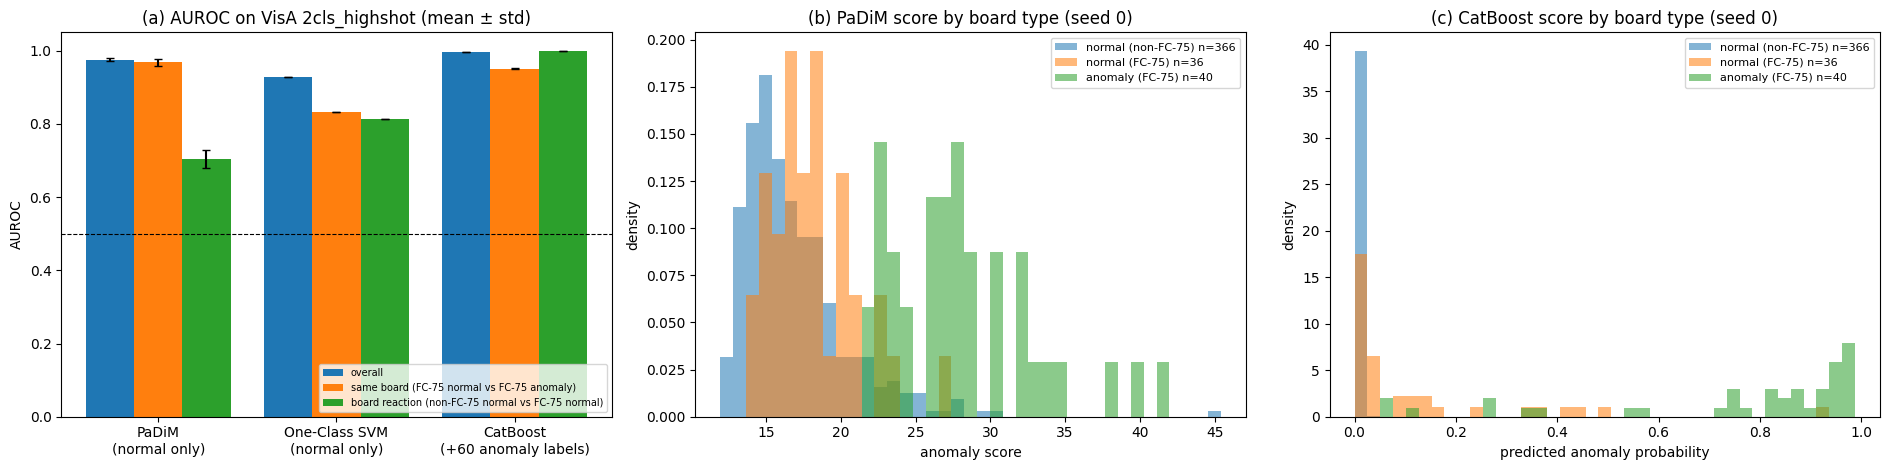

In [ ]:
# @title 그림 8. Test 4: 모델별 AUROC와 기판 종류별 점수 분포 (seed 0)
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
x = np.arange(len(T4_MODELS))
for j, (col, label) in enumerate([('auroc_all', 'overall'), ('same_variant', 'same board (FC-75 normal vs FC-75 anomaly)'),
                                  ('variant_reaction', 'board reaction (non-FC-75 normal vs FC-75 normal)')]):
    m = T4.groupby('model')[col].mean().reindex(T4_MODELS)
    s = T4.groupby('model')[col].std().reindex(T4_MODELS).fillna(0)
    axes[0].bar(x + (j - 1) * 0.27, m.values, 0.27, yerr=s.values, capsize=3, label=label)
axes[0].axhline(0.5, color='k', ls='--', lw=0.8)
axes[0].set_xticks(x, ['PaDiM\n(normal only)', 'One-Class SVM\n(normal only)', 'CatBoost\n(+60 anomaly labels)'])
axes[0].set(ylim=(0, 1.05), ylabel='AUROC', title='(a) AUROC on VisA 2cls_highshot (mean ± std)')
axes[0].legend(fontsize=7, loc='lower right')
for ax, (letter, m) in zip(axes[1:], [('b', 'PaDiM'), ('c', 'CatBoost')]):
    g = groups(frame(test2_ds, T4_SCORES[(m, 0)]))
    vals = np.concatenate([g['normal_nonfc'], g['normal_fc'], g['anomaly_fc']])
    bins = np.linspace(vals.min(), vals.max(), 40)
    for key, label in [('normal_nonfc', 'normal (non-FC-75)'), ('normal_fc', 'normal (FC-75)'), ('anomaly_fc', 'anomaly (FC-75)')]:
        ax.hist(g[key], bins=bins, alpha=0.55, density=True, label=f'{label} n={len(g[key])}')
    ax.set(title=f'({letter}) {m} score by board type (seed 0)', xlabel='anomaly score' if m == 'PaDiM' else 'predicted anomaly probability',
           ylabel='density')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f'{RESULT_DIR}/fig8_test4.png', dpi=120)
plt.show()


In [ ]:
# @title Test 4 판정 (실행 전에 정한 기준)
mean = T4.groupby('model')[['auroc_all', 'same_variant', 'variant_reaction']].mean()
d_all = mean.loc['CatBoost', 'auroc_all'] - mean.loc['PaDiM', 'auroc_all']
v1 = '더 좋다' if d_all >= 0.02 else ('더 나쁘다' if d_all <= -0.02 else '비슷하다')
print(f"RQ4-1: 전체 AUROC CatBoost {mean.loc['CatBoost', 'auroc_all']:.3f} vs PaDiM {mean.loc['PaDiM', 'auroc_all']:.3f} "
      f"(차이 {d_all:+.3f}) → 전체 성능은 {v1}")
d_same = mean.loc['CatBoost', 'same_variant'] - mean.loc['PaDiM', 'same_variant']
react = mean.loc['CatBoost', 'variant_reaction']
v2 = '라벨을 쓴 모델이 기판 종류 지름길에 더 기댄다' if (d_same <= -0.05 and react >= 0.8) else '사전 기준으로는 지름길에 더 기댄다고 볼 수 없다'
print(f"RQ4-2: 같은 기판 AUROC CatBoost {mean.loc['CatBoost', 'same_variant']:.3f} vs PaDiM {mean.loc['PaDiM', 'same_variant']:.3f} "
      f"(차이 {d_same:+.3f}), CatBoost 기판 반응 AUROC {react:.3f} → {v2}")


RQ4-1: 전체 AUROC CatBoost 0.996 vs PaDiM 0.976 (차이 +0.020) → 전체 성능은 비슷하다
RQ4-2: 같은 기판 AUROC CatBoost 0.951 vs PaDiM 0.968 (차이 -0.017), CatBoost 기판 반응 AUROC 0.999 → 사전 기준으로는 지름길에 더 기댄다고 볼 수 없다


### Test 4 정리

- 실험 내용: 지금까지는 정상만 학습하는 모델이었는데, 데이터사이언스에서 많이 쓰는 분류 모델인 CatBoost에 이미지 특징과 불량 라벨까지 주고 학습시키면 어떨지, PaDiM과 같은 기준(같은 기판 AUROC, 오탐률)으로 비교해 보았다.
- 결과: CatBoost가 전체 AUROC 0.996으로 PaDiM 0.976에 비해 가장 높았지만(PaDiM 0.976), 같은 기판끼리는 0.951로 PaDiM(0.968)보다 낮았다. 기판 종류는 거의 완벽히 구분해서 오탐이 FC-75 정상에만 몰렸고, 비FC-75 정상 오탐은 0%였다.
- 분석: 일단 CatBoost가 의외로 많이 높아서 놀랐지만, 같은 기판 기준에서는 낮아 기판 종류에 영향이 가는 경향이 있었지만, 아무튼 데이터사이언스에서나 봤던 이런 분류 모델이 이렇게까지 할 수 있다는 것을 알게 되었다.

## 개인 회고

### KPT
- Keep: AutoEncoder에서 점수가 생각보다 낮았던 것을 의심해 문제를 찾고 돌린 방식이나 데이터셋 기판에 몇가지 다른 점을 보고 혹시나 해서 돌린 실험처럼, 앞으로도 여러 방면으로 미리 이런 벤치마크 테스트를 돌리고, 비정상일 때 최대한 여러 방면으로 자세하게 확인해 볼 것이다.
- Problem: AutoEncoder가 0.27로 무작위보다 낮았는데, 모델 문제가 아니라 입력과 출력의 범위가 안 맞는 코드 문제였고, 기판 종류 라벨을 만들 때 결함이 인쇄를 가린 사진 때문에 자동 판별이 틀려 시간이 더 들었다.
- Try: 새 모델을 쓸 때는 입력·출력 범위와 손실이 제대로 줄어드는지부터 확인하고, 데이터셋은 미리 자세하게 확인해 볼 것이다.

### AAR
- 목표: 정상 이미지로만 학습하는 이상 탐지 모델 3개를 비교해 보고, 가장 잘 나온 PaDiM이 정말 불량을 보고 맞힌 건지 확인해 본다.
- 결과: PaDiM은 같은 기판끼리 비교해도 불량을 잘 찾아서 정말 불량을 보고 있었지만, FC-75 기판의 정상 제품은 불량으로 잘못 보는 경우가 2배 넘게 많았다. 또 AutoEncoder는 코드를 고치니 크게 좋아졌고, CatBoost는 점수는 제일 높았지만 기판 종류로 맞히는 경향이 있었다.
- 차이 원인: 일단 학습에 쓴 정상 사진에 FC-75 기판이 거의 없었고, AutoEncoder는 입력과 출력의 값 범위가 서로 달라서 학습이 잘 되지 않았었다. CatBoost는 불량 사진이 거의 다 FC-75 기판이라 기판 종류까지 같이 배웠다.
- 다음 액션: 학습 데이터에 기판 종류를 골고루 넣어서 다시 학습해 보거나 기판마다 기준을 따로 정해 보고, 실험할 때 시드를 고정해서 결과를 다시 확인해 볼 것이다.